In [1]:
# Installed before transformers is first imported (Task 3), so that Task 10 can load its relevance judge in 4-bit.
!pip install -q bitsandbytes

import kagglehub
from kagglehub import KaggleDatasetAdapter

# 1. Load Members Data
df_members = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "raiyanahmed/hummus",
  "pp_members.csv",
  pandas_kwargs={"low_memory": False}
)
print("Members first 5 records:\n", df_members.head(), "\n")

# 2. Load Recipes Data
# (This is usually the file with the most columns and the source of the warning)
df_recipes = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "raiyanahmed/hummus",
  "pp_recipes.csv",
  pandas_kwargs={"low_memory": False}
)
print("Recipes first 5 records:\n", df_recipes.head(), "\n")

# 3. Load Reviews Data
df_reviews = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "raiyanahmed/hummus",
  "pp_reviews.csv",
  pandas_kwargs={"low_memory": False}
)
print("Reviews first 5 records:\n", df_reviews.head())

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 49.8 MB/s eta 0:00:00
Members first 5 records:
    Unnamed: 0   member_id                            member_url  \
0           0      911346      https://www.food.com/user/911346   
1           1  2000090836  https://www.food.com/user/2000090836   
2           2  2002151276  https://www.food.com/user/2002151276   
3           3      472751      https://www.food.com/user/472751   
4           4     2682835     https://www.food.com/user/2682835   

      member_name member_description member_status  member_avg_rating  \
0  jerome.a.fried                NaN           NaN                NaN   
1     Kimberly L.                NaN           NaN                NaN   
2         leslieS                NaN   Contributor                NaN   
3          rekseb                NaN           NaN                NaN   
4        XPICTHNA                NaN           NaN                NaN   

  member_map_pin member_joined  follows_count  follow

# Task 1


--- Missing Values in Reviews ---
Unnamed: 0                 0
member_id                  0
recipe_id                  0
rating                     0
text                  506718
likes                 506510
last_modified_date         0
review_id             506510
review_url            506510
member_url            506510
new_member_id              0
new_recipe_id              0
dtype: int64

--- Missing Values in Members ---
Unnamed: 0                 0
member_id                  0
member_url                 0
member_name                0
member_description    260268
member_status         230424
member_avg_rating     268799
member_map_pin        267185
member_joined              0
follows_count              0
follow_me_count            0
avatar_url                 0
new_member_id              0
dtype: int64

--- Missing Values in Recipes ---
Unnamed: 0                       0
recipe_id                        0
title                            0
description                  10107
auth

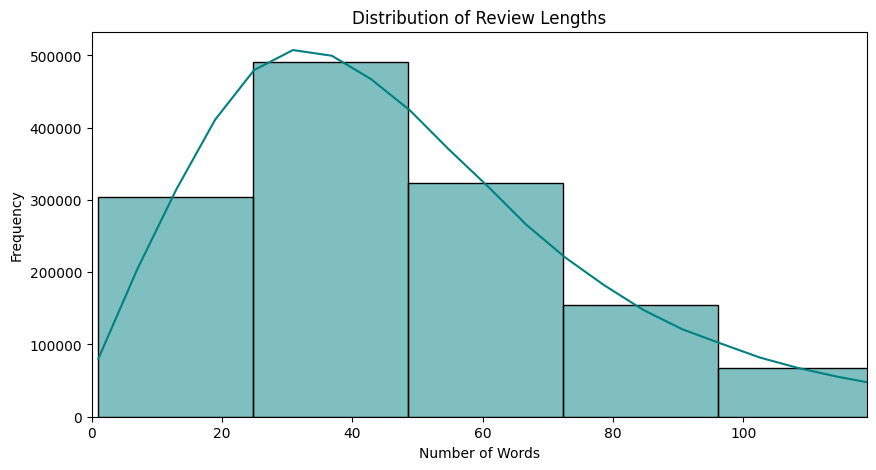


--- Rating Composition of Reviews With Text (%) ---
rating
1.0     1.199898
2.0     1.261046
2.5     5.453347
3.0     3.586642
4.0    16.303789
5.0    72.195278
Name: proportion, dtype: float64

Imputed (2.5) share: 5.45%

--- Explicit Star Rating Distribution (%, 1-5 only) ---
rating
1.0     1.269107
2.0     1.333782
3.0     3.793516
4.0    17.244173
5.0    76.359422
Name: proportion, dtype: float64


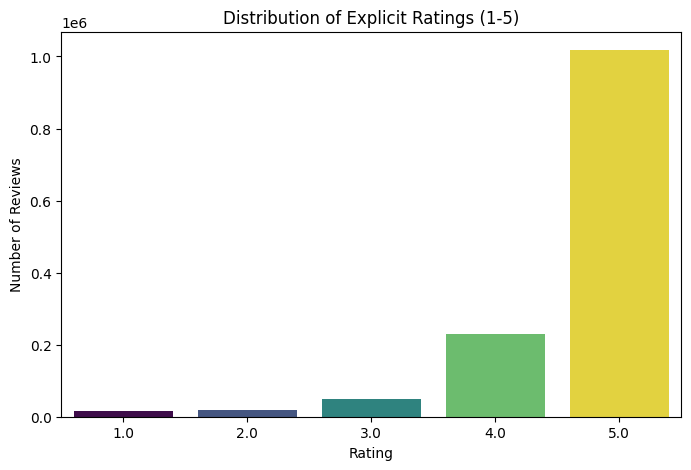


--- Frequency of Contextual Expressions ---
                   Review Count  Percentage (%)
partner/spouse            86219        6.116111
time-constrained          68480        4.857761
special occasion          57029        4.045462
children/kids             46116        3.271327
guests/company            33875        2.402988
weekend                   11278        0.800027
weeknight/weekday          5808        0.412002


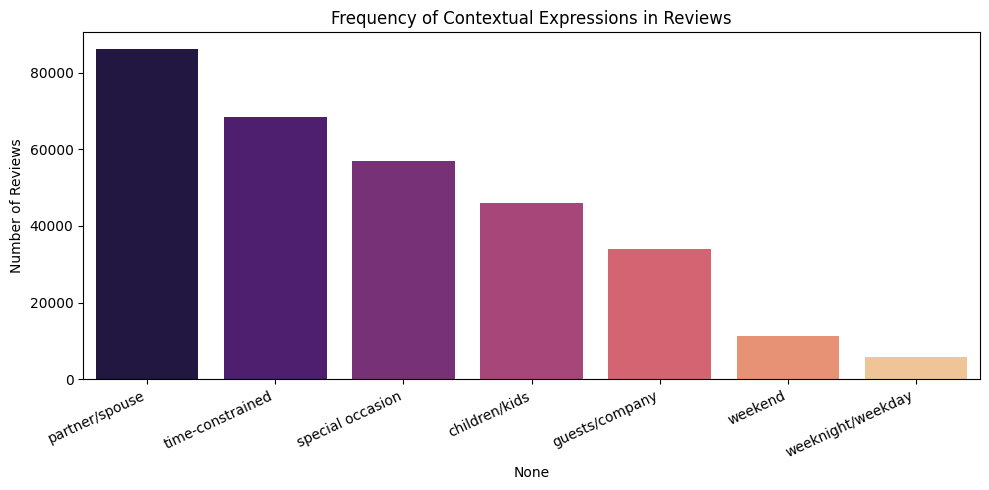


Clauses: 7072261 from 1409703 reviews
   review_row  review_id  recipe_id  member_id last_modified_date  rating  \
0           0   171462.0      96347     192799         2005-05-02     5.0   
1           0   171462.0      96347     192799         2005-05-02     5.0   
2           0   171462.0      96347     192799         2005-05-02     5.0   
3           0   171462.0      96347     192799         2005-05-02     5.0   
4           0   171462.0      96347     192799         2005-05-02     5.0   
5           0   171462.0      96347     192799         2005-05-02     5.0   
6           0   171462.0      96347     192799         2005-05-02     5.0   
7           1  1296592.0      37139     394617         2012-03-25     2.5   
8           1  1296592.0      37139     394617         2012-03-25     2.5   
9           1  1296592.0      37139     394617         2012-03-25     2.5   

                                           sentences  clause_idx  
0                 I've never made ham & beans 

In [2]:
import html
import re
import matplotlib.pyplot as plt
import nltk
import pandas as pd
import seaborn as sns
from nltk.tokenize import sent_tokenize

# Task 1: Exploratory Data Analysis and Text Preparation

# Run the dataset loader module first and use it here

for resource in ("punkt", "punkt_tab"):
    nltk.download(resource, quiet=True)

# HUMMUS pp_reviews.csv stores the review body in `text`.
TEXT_COL = "text"
RATING_COL = "rating"
# pp_reviews.csv has no submit_date; last_modified_date is the only review timestamp (an edit can move it later).
DATE_COL = "last_modified_date"
ID_COL = "review_id" if "review_id" in df_reviews.columns else None

# ==========================================
# 1. MISSING VALUES
# ==========================================
for name, df in [("Reviews", df_reviews), ("Members", df_members), ("Recipes", df_recipes)]:
    print(f"\n--- Missing Values in {name} ---")
    print(df.isnull().sum())

# Review text holds HTML: escaped characters ("&#039;", "&amp;"), line breaks as <br/> tags (some escaped as
# "&lt;br/&gt;") and a few formatting tags. Unescape it and keep line breaks as "\n", which the clause splitter uses as
# sentence boundaries; other whitespace is collapsed.
BREAK_TAG = re.compile(r"<br\s*/?>", re.IGNORECASE)
FORMAT_TAG = re.compile(r"</?(?:a|b|i|u|em|strong|p|span|div|font)\b[^>]*>", re.IGNORECASE)


def clean_text(text):
    text = FORMAT_TAG.sub("", BREAK_TAG.sub("\n", html.unescape(str(text))))
    return re.sub(r"\s*\n\s*", "\n", re.sub(r"[^\S\n]+", " ", text)).strip()


# HUMMUS adds authorship rows (rating 6) that have no review text; they cannot be analysed as text.
n_total = len(df_reviews)
df_reviews = df_reviews.dropna(subset=[TEXT_COL]).copy()
df_reviews[TEXT_COL] = df_reviews[TEXT_COL].map(clean_text)
df_reviews = df_reviews[df_reviews[TEXT_COL] != ""].copy()
df_reviews[DATE_COL] = pd.to_datetime(df_reviews[DATE_COL], errors="coerce")
print(f"\nReviews with text: {len(df_reviews)} / {n_total} ({len(df_reviews) / n_total:.1%})")

# ==========================================
# 2. REVIEW LENGTH ANALYSIS
# ==========================================
df_reviews["review_length"] = df_reviews[TEXT_COL].str.split().str.len()

print("\n--- Review Length Statistics (words) ---")
print(df_reviews["review_length"].describe())

plt.figure(figsize=(10, 5))
sns.histplot(df_reviews["review_length"], bins=50, kde=True, color="teal")
plt.title("Distribution of Review Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.xlim(0, df_reviews["review_length"].quantile(0.95))  # cap at 95th percentile
plt.show()

# ==========================================
# 3. RATING DISTRIBUTION
# ==========================================
# HUMMUS preprocessing: rating 0 (no rating) -> 2.5, authorship -> 6. Only 1-5 are real star ratings.
real_mask = df_reviews[RATING_COL].isin([1, 2, 3, 4, 5])
print("\n--- Rating Composition of Reviews With Text (%) ---")
print(df_reviews[RATING_COL].value_counts(normalize=True).sort_index() * 100)
print(f"\nImputed (2.5) share: {(df_reviews[RATING_COL] == 2.5).mean():.2%}")

print("\n--- Explicit Star Rating Distribution (%, 1-5 only) ---")
print(df_reviews.loc[real_mask, RATING_COL].value_counts(normalize=True).sort_index() * 100)

plt.figure(figsize=(8, 5))
sns.countplot(x=RATING_COL, data=df_reviews[real_mask], hue=RATING_COL, palette="viridis", legend=False)
plt.title("Distribution of Explicit Ratings (1-5)")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.show()

# ==========================================
# 4. CONTEXTUAL EXPRESSIONS FREQUENCY
# ==========================================
context_patterns = {
    "weeknight/weekday": r"\b(?:week ?nights?|week ?days?|school nights?|work nights?)\b",
    "weekend": r"\b(?:weekends?|sunday dinners?|saturday)\b",
    "children/kids": r"\b(?:for|with|my|our) (?:the |my |our )?(?:children|kids|kiddos?|toddlers?|sons?|daughters?|grandkids?|grandchildren)\b",
    "partner/spouse": r"\b(?:my|our) (?:husband|wife|partner|boyfriend|girlfriend|hubby|dh|fiance)\b",
    "guests/company": r"\b(?:guests?|company|dinner party|potluck|crowd)\b",
    "special occasion": r"\b(?:special occasions?|holidays?|anniversary|birthday|celebrations?|christmas|thanksgiving|easter)\b",
    "time-constrained": r"\b(?:quick|in a hurry|short on time|busy (?:night|day|weeknight)s?|time[- ]consuming)\b",
}

context_counts = {
    name: int(df_reviews[TEXT_COL].str.contains(pattern, case=False, regex=True).sum())
    for name, pattern in context_patterns.items()
}

count_df = pd.DataFrame.from_dict(context_counts, orient="index", columns=["Review Count"])
count_df["Percentage (%)"] = count_df["Review Count"] / len(df_reviews) * 100
count_df = count_df.sort_values("Review Count", ascending=False)
print("\n--- Frequency of Contextual Expressions ---")
print(count_df)

plt.figure(figsize=(10, 5))
sns.barplot(x=count_df.index, y=count_df["Review Count"], hue=count_df.index, palette="magma", legend=False)
plt.title("Frequency of Contextual Expressions in Reviews")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

# ==========================================
# 5. SENTENCE / CLAUSE SPLITTING
# ==========================================
# Zero-width lookahead keeps the contrast word at the start of its clause; "even" stays attached to "though".
CONTRAST_PATTERN = re.compile(r"(?=\b(?:but|although|however|yet|even though)\b)|(?<!even )(?=\bthough\b)", re.IGNORECASE)


def split_into_sentences(text):
    """Split into lines and sentences, then into clauses before contrast words. Negations are never removed."""
    if pd.isna(text):
        return []
    clauses = []
    for line in str(text).splitlines():
        for sentence in sent_tokenize(line):
            for clause in CONTRAST_PATTERN.split(sentence):
                clause = clause.strip(",; ")
                if clause:
                    clauses.append(clause)
    return clauses


df_reviews["clauses"] = df_reviews[TEXT_COL].apply(split_into_sentences)

# One row per clause; keep ids and clause position so later tuples can cite evidence spans.
keep_cols = [c for c in (ID_COL, "recipe_id", "member_id", DATE_COL, RATING_COL, "clauses") if c and c in df_reviews.columns]
df_clauses = df_reviews[keep_cols].explode("clauses").rename(columns={"clauses": "sentences"})
df_clauses = df_clauses.dropna(subset=["sentences"])
df_clauses["clause_idx"] = df_clauses.groupby(level=0).cumcount()
df_clauses = df_clauses.reset_index(names="review_row")

print(f"\nClauses: {len(df_clauses)} from {len(df_reviews)} reviews")
print(df_clauses.head(10))


# Task 2

{'INGREDIENT': 3630, 'DISH': 2207, 'COOKING_EQUIPMENT': 98, 'OCCASION': 64, 'DINER_GROUP': 82}
Fine-tuning the pretrained en_core_web_sm NER on the dictionary labels:
  epoch 1/8  ner loss: 9152.2
  epoch 2/8  ner loss: 4197.4
  epoch 3/8  ner loss: 3253.1
  epoch 4/8  ner loss: 2603.5
  epoch 5/8  ner loss: 2260.8
  epoch 6/8  ner loss: 2093.1
  epoch 7/8  ner loss: 1765.3
  epoch 8/8  ner loss: 1591.2
Training a blank NER model on the same labels, for comparison:
  epoch 1/8  ner loss: 10019.8
  epoch 2/8  ner loss: 5217.4
  epoch 3/8  ner loss: 4052.9
  epoch 4/8  ner loss: 3536.4
  epoch 5/8  ner loss: 3042.2
  epoch 6/8  ner loss: 2721.1
  epoch 7/8  ner loss: 2485.3
  epoch 8/8  ner loss: 2361.2

--- Entity-level P/R/F1 on 41 hand-written gold sentences ---
                  dictionary                         domain model                         from scratch                         general spaCy                        
                     support precision recall     f1      sup

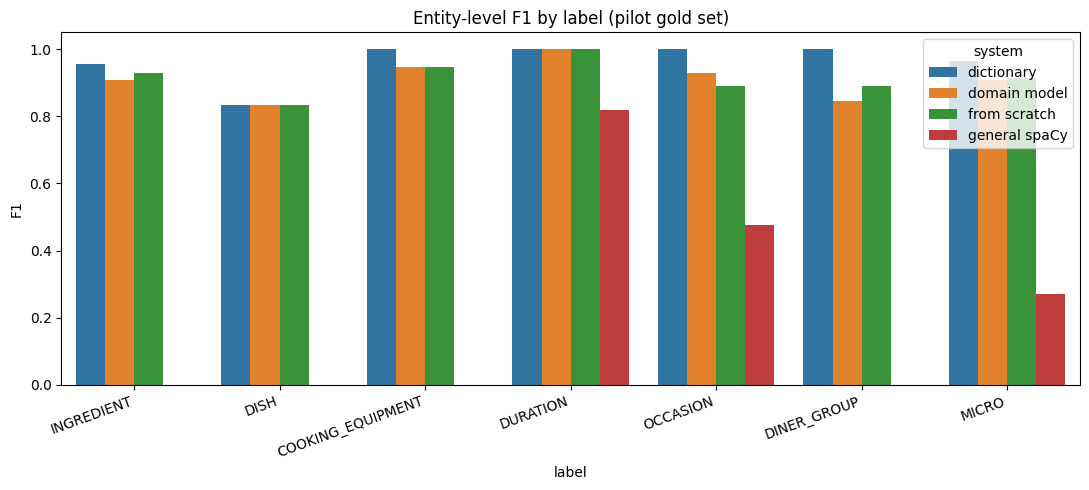


--- dictionary: sample errors ---
MISSED   INGREDIENT         'sumac'
MISSED   DISH               'pavlova'
MISSED   DISH               'tagine'
SPURIOUS DISH               'roast'
MISSED   INGREDIENT         'fenugreek'
MISSED   DISH               'panforte'

--- domain model: sample errors ---
MISSED   INGREDIENT         'sumac'
MISSED   OCCASION           'weekdays'
MISSED   COOKING_EQUIPMENT  'air fryer'
SPURIOUS INGREDIENT         'air fryer'
MISSED   DISH               'pavlova'
MISSED   DISH               'tagine'
MISSED   DINER_GROUP        'in-laws'
MISSED   OCCASION           'school nights'
MISSED   INGREDIENT         'tamarind paste'
MISSED   DINER_GROUP        'mother-in-law'
SPURIOUS DINER_GROUP        'mother-'
MISSED   DINER_GROUP        'teenagers'
SPURIOUS DISH               'roast'
MISSED   INGREDIENT         'fenugreek'
MISSED   DISH               'panforte'

--- Entity counts over 20000 clauses ---
                   dictionary  domain model
INGREDIENT            

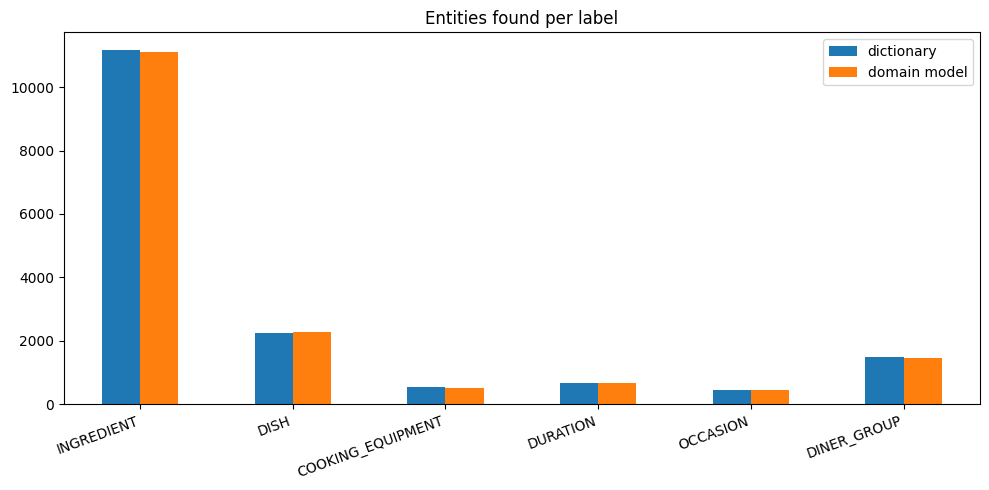


--- Most frequent entities per label (domain model) ---
INGREDIENT: {'chicken': 349, 'sugar': 247, 'butter': 231, 'cheese': 216, 'garlic': 206, 'water': 170, 'salt': 158, 'rice': 154, 'fat': 141, 'meat': 140, 'flour': 136, 'milk': 134}
DISH: {'soup': 196, 'cake': 192, 'bread': 187, 'salad': 139, 'cookies': 134, 'cookie': 79, 'pasta': 58, 'muffins': 52, 'pie': 50, 'chili': 45, 'roast': 42, 'sandwich': 33}
COOKING_EQUIPMENT: {'oven': 164, 'grill': 48, 'crockpot': 46, 'microwave': 36, 'blender': 32, 'skillet': 27, 'crock pot': 26, 'food processor': 23, 'broiler': 11, 'casserole dish': 10, 'cast iron': 7, 'mixer': 7}
DURATION: {'20 minutes': 38, '10 minutes': 34, 'an hour': 28, '5 minutes': 27, '15 minutes': 26, '30 minutes': 24, 'overnight': 22, 'a day': 18, '45 minutes': 16, '25 minutes': 14, '40 minutes': 13, '2 hours': 13}
OCCASION: {'party': 70, 'christmas': 57, 'holiday': 42, 'thanksgiving': 42, 'bbq': 36, 'birthday': 26, 'weekend': 26, 'potluck': 21, 'weeknight': 15, 'easter': 14, 

In [3]:
# Imports already made by task-1.py (same notebook): re, plt, nltk, pd, sns.
import ast
import json
import os
import random
from collections import Counter

import spacy
from spacy.matcher import PhraseMatcher
from spacy.training import Example
from spacy.util import compounding, minibatch

# Task 2: Named Entity Recognition for Food and Context
# Run load-dataset.py and task-1.py first (this needs df_recipes and df_clauses).
# Kaggle: spaCy is preinstalled; en_core_web_sm (pretrained, fine-tuned here) is downloaded if missing, so keep internet on.

for required in ("df_recipes", "df_clauses"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py in this session first.")

SEED = 42
N_LEXICON_RECIPES = 100_000  # recipes sampled to build the ingredient and dish lexicons
N_TRAIN_CLAUSES = 20_000     # dictionary-labelled clauses used to train the NER model
N_EPOCHS = 8
N_APPLY_CLAUSES = 20_000     # clauses used for the frequency analysis
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

random.seed(SEED)
spacy.util.fix_random_seed(SEED)

LABELS = ["INGREDIENT", "DISH", "COOKING_EQUIPMENT", "DURATION", "OCCASION", "DINER_GROUP"]
# Between overlapping matches of equal length, the label listed first wins.
PRIORITY = {l: i for i, l in enumerate(["DISH", "COOKING_EQUIPMENT", "OCCASION", "DINER_GROUP", "DURATION", "INGREDIENT"])}


def terms(csv):
    return {t.strip() for t in csv.replace("\n", " ").split(",") if t.strip()}


# ==========================================
# 1. LEXICONS
# ==========================================
SEED_INGREDIENTS = terms("""chicken, beef, pork, lamb, turkey, bacon, sausage, ham, shrimp, salmon, tuna, egg, eggs, butter,
milk, cream, cheese, parmesan, cheddar, mozzarella, yogurt, sour cream, flour, sugar, brown sugar, honey, salt, pepper, garlic,
onion, onions, shallot, ginger, tomato, tomatoes, potato, potatoes, carrot, carrots, celery, mushroom, mushrooms, spinach,
broccoli, cauliflower, zucchini, cabbage, cucumber, lettuce, corn, peas, beans, black beans, chickpeas, lentils, rice, pasta,
noodles, breadcrumbs, oats, olive oil, vegetable oil, vinegar, soy sauce, lemon, lime, orange, apple, banana, strawberries,
blueberries, cinnamon, vanilla, cumin, paprika, oregano, basil, parsley, cilantro, thyme, rosemary, chili powder, cayenne,
jalapeno, coconut milk, peanut butter, chocolate, cocoa, walnuts, almonds, pecans, cornstarch, baking powder, baking soda,
yeast, tofu, avocado, mayonnaise, mustard, ketchup, salsa, broth, stock, wine, egg whites, butternut squash""")

DISH_NOUNS = terms("""soup, stew, casserole, lasagna, pizza, curry, chili, cake, cookies, pie, pasta, salad, sandwich, burger,
burgers, tacos, enchiladas, quiche, pancakes, waffles, muffins, brownies, bread, meatloaf, meatballs, risotto, stir fry,
pot roast, mac and cheese, cheesecake, omelet, burritos, fajitas, gumbo, jambalaya, lo mein, dumplings, sushi, pudding,
cupcakes, scones, biscuits, fudge, smoothie, lemonade, chowder, roast, kebabs, fritters, frittata, pancake, cookie""")

EQUIPMENT = terms("""oven, slow cooker, crock pot, crockpot, instant pot, pressure cooker, skillet, frying pan, fry pan, dutch oven,
grill, microwave, blender, food processor, stand mixer, hand mixer, mixer, air fryer, rice cooker, baking sheet, cookie sheet,
saucepan, sauce pan, stockpot, stock pot, wok, casserole dish, baking dish, baking pan, cake pan, muffin tin, loaf pan,
pie plate, whisk, colander, cast iron, griddle, broiler, toaster oven, deep fryer, smoker, roasting pan, steamer, bundt pan,
springform pan, mandoline, rolling pin, thermometer, immersion blender""")

OCCASIONS = terms("""weeknight, weekday, weekend, school night, work night, special occasion, holiday, christmas, thanksgiving,
easter, birthday, anniversary, dinner party, party, potluck, bbq, barbecue, cookout, picnic, game day, super bowl, new year's eve,
valentine's day, halloween, hanukkah, lunchbox, tailgate, wedding, baby shower, cocktail party, sunday dinner, date night""")

DINER_GROUPS = terms("""children, child, kids, kid, kiddos, toddler, toddlers, baby, teenagers, teens, family, husband, wife, hubby,
partner, boyfriend, girlfriend, fiance, guests, guest, company, friends, grandkids, grandchildren, parents, mother, father,
mother-in-law, father-in-law, in-laws, picky eaters, picky eater, crowd, daughter, son, dh, dd, ds, boys, girls, roommates,
coworkers, neighbors""")


def plural_variants(term):
    if term.endswith("y") and not term.endswith(("ay", "ey", "oy", "uy")):
        return {term, term[:-1] + "ies"}
    if term.endswith(("s", "x", "ch", "sh")):
        return {term, term + "es"}
    return {term, term + "s"}


def parse_list(value):
    if isinstance(value, (list, tuple)):
        return list(value)
    try:
        parsed = ast.literal_eval(value)
        return list(parsed) if isinstance(parsed, (list, tuple)) else []
    except (ValueError, SyntaxError, TypeError):
        return []


WORD_OK = re.compile(r"^[a-z][a-z \-']{2,39}$")
recipes_sample = df_recipes.sample(min(N_LEXICON_RECIPES, len(df_recipes)), random_state=SEED)

# Ingredients: frequent FoodKG-normalised ingredient names from the recipe table.
ingredient_lexicon = set(SEED_INGREDIENTS)
if "ingredient_food_kg_names" in recipes_sample.columns:
    counts = Counter()
    for value in recipes_sample["ingredient_food_kg_names"].dropna():
        counts.update({str(n).lower().strip() for n in parse_list(value)})
    ingredient_lexicon |= {n for n, c in counts.items() if c >= 30 and WORD_OK.match(n) and len(n.split()) <= 3}

# Dishes: dish nouns plus the up-to-two-word phrase before them in recipe titles ("chicken soup").
TITLE_MODIFIERS = {"the", "a", "best", "easy", "quick", "simple", "super", "my", "our", "favorite", "perfect", "classic",
                   "ultimate", "great", "good", "homemade", "basic", "old", "fashioned", "style", "delicious", "awesome",
                   "amazing", "new", "fast", "healthy", "low", "fat", "free", "and", "with", "i", "mom's", "grandma's"}
dish_lexicon = set(DISH_NOUNS)
if "title" in recipes_sample.columns:
    single_nouns = {n for n in DISH_NOUNS if " " not in n}
    phrase_counts = Counter()
    for title in recipes_sample["title"].dropna().str.lower().str.replace(r"[^a-z' \-]", " ", regex=True):
        tokens = title.split()
        if len(tokens) >= 2 and tokens[-1] in single_nouns and tokens[-2] not in TITLE_MODIFIERS and len(tokens[-2]) > 2:
            phrase_counts[" ".join(tokens[-2:])] += 1
    dish_lexicon |= {p for p, c in phrase_counts.items() if c >= 5}

LEXICONS = {
    "INGREDIENT": {v for t in ingredient_lexicon for v in plural_variants(t)},
    "DISH": {v for t in dish_lexicon for v in plural_variants(t)},
    "COOKING_EQUIPMENT": {v for t in EQUIPMENT for v in plural_variants(t)},
    "OCCASION": {v for t in OCCASIONS for v in plural_variants(t)},
    "DINER_GROUP": {v for t in DINER_GROUPS for v in plural_variants(t)},
}
print({label: len(entries) for label, entries in LEXICONS.items()})

# ==========================================
# 2. DICTIONARY-BASED NER
# ==========================================
nlp_tok = spacy.blank("en")  # tokenizer only; the dictionary extractor needs no model
matcher = PhraseMatcher(nlp_tok.vocab, attr="LOWER")
for label, entries in LEXICONS.items():
    matcher.add(label, list(nlp_tok.tokenizer.pipe(sorted(entries))))

_NUM = r"(?:\d+\s+\d+/\d+|\d+/\d+|\d+(?:\.\d+)?|an?|one|two|three|four|five|six|seven|eight|nine|ten|twelve|couple of|few)"
_UNIT = r"(?:seconds?|secs?|minutes?|mins?|hours?|hrs?|days?|weeks?)"
DURATION_RE = re.compile(
    rf"\b(?:half an hour|overnight|{_NUM}(?:\s*(?:-|to|or)\s*{_NUM})?(?:\s+and\s+a\s+half)?\s*-?\s*{_UNIT})\b", re.IGNORECASE
)


def resolve_overlaps(candidates):
    """Greedy: longest span first, then label priority, then leftmost."""
    chosen = []
    for start, end, label in sorted(candidates, key=lambda c: (-(c[1] - c[0]), PRIORITY[c[2]], c[0])):
        if all(end <= s or start >= e for s, e, _ in chosen):
            chosen.append((start, end, label))
    return sorted(chosen)


def dictionary_ner(texts):
    results = []
    for doc in nlp_tok.pipe(texts, batch_size=1000):
        candidates = []
        for match_id, start, end in matcher(doc):
            candidates.append((doc[start].idx, doc[end - 1].idx + len(doc[end - 1]), nlp_tok.vocab.strings[match_id]))
        for m in DURATION_RE.finditer(doc.text):
            span = doc.char_span(m.start(), m.end(), alignment_mode="contract")
            if span is not None:
                candidates.append((span.start_char, span.end_char, "DURATION"))
        results.append(resolve_overlaps(candidates))
    return results


# ==========================================
# 3. EVALUATION SET (small, hand-written pilot gold)
# ==========================================
# Markup: [[span|LABEL]]. This pilot set is independent of the lexicons but small; extend it with the Task 10 annotations.
GOLD_MARKUP = [
    "Made this on a [[weeknight|OCCASION]] and it took only [[30 minutes|DURATION]].",
    "My [[kids|DINER_GROUP]] loved the [[chicken|INGREDIENT]] but it was too spicy for my [[husband|DINER_GROUP]].",
    "Perfect [[lasagna|DISH]] for [[Christmas|OCCASION]] [[guests|DINER_GROUP]]!",
    "Baked it in my [[Dutch oven|COOKING_EQUIPMENT]] for [[2 hours|DURATION]] and the [[beef|INGREDIENT]] was tender.",
    "I used [[coconut milk|INGREDIENT]] instead of [[cream|INGREDIENT]] and a pinch of [[sumac|INGREDIENT]].",
    "Great [[chili|DISH]] for a [[potluck|OCCASION]], the whole [[family|DINER_GROUP]] asked for seconds.",
    "Too time-consuming for [[weekdays|OCCASION]], but fine for the [[weekend|OCCASION]].",
    "Cooked the [[onions|INGREDIENT]] and [[garlic|INGREDIENT]] in a large [[skillet|COOKING_EQUIPMENT]] for [[5 minutes|DURATION]].",
    "My [[toddler|DINER_GROUP]] ate two helpings of this [[mac and cheese|DISH]].",
    "I made [[harissa|INGREDIENT]] [[chicken|INGREDIENT]] in the [[air fryer|COOKING_EQUIPMENT]].",
    "Served this [[pavlova|DISH]] at our [[anniversary|OCCASION]] dinner.",
    "Let the [[pork|INGREDIENT]] marinate [[overnight|DURATION]].",
    "My [[picky eaters|DINER_GROUP]] actually cleaned their plates.",
    "Used my [[stand mixer|COOKING_EQUIPMENT]] to whip the [[egg whites|INGREDIENT]].",
    "This [[tagine|DISH]] was a hit with my [[in-laws|DINER_GROUP]].",
    "Ready in [[20 minutes|DURATION]], which makes it ideal for a busy [[weeknight|OCCASION]].",
    "I baked these [[cookies|DISH]] for a [[birthday|OCCASION]].",
    "Cooked it in the [[crock pot|COOKING_EQUIPMENT]] on low for [[8 hours|DURATION]].",
    "My [[husband|DINER_GROUP]] and [[kids|DINER_GROUP]] devoured the [[pot roast|DISH]].",
    "Not enough [[salt|INGREDIENT]] for my taste, so I added extra [[cumin|INGREDIENT]].",
    "Easy [[stir fry|DISH]] for [[school nights|OCCASION]] when you only have [[15 minutes|DURATION]].",
    "I used a [[springform pan|COOKING_EQUIPMENT]] and the [[cheesecake|DISH]] came out perfect.",
    "Took [[1 1/2 hours|DURATION]] total, much longer than expected.",
    "Served it to [[guests|DINER_GROUP]] on [[Thanksgiving|OCCASION]] and everyone wanted the recipe.",
    "Added [[tamarind paste|INGREDIENT]] for a sour kick, delicious with [[rice|INGREDIENT]].",
    "Cooked [[30-45 minutes|DURATION]] on the [[grill|COOKING_EQUIPMENT]].",
    "I made [[chicken soup|DISH]] when my [[mother-in-law|DINER_GROUP]] was sick.",
    "This is going into my [[holiday|OCCASION]] rotation.",
    "No [[flour|INGREDIENT]] needed, just [[almond meal|INGREDIENT]] and [[eggs|INGREDIENT]].",
    "Four stars, I would make it again.",
    "Thanks for sharing!",
    "Next time I will use less [[sugar|INGREDIENT]].",
    "The [[mandoline|COOKING_EQUIPMENT]] made slicing the [[potatoes|INGREDIENT]] quick.",
    "Our [[teenagers|DINER_GROUP]] requested this [[pizza|DISH]] again for [[game day|OCCASION]].",
    "Simmer the [[tomatoes|INGREDIENT]] for [[10 minutes|DURATION]] in a [[saucepan|COOKING_EQUIPMENT]].",
    "Perfect for [[Easter|OCCASION]].",
    "I halved it for just the two of us.",
    "My [[grandkids|DINER_GROUP]] love these [[pancakes|DISH]].",
    "Cut the [[butternut squash|INGREDIENT]] into cubes and roast in the [[oven|COOKING_EQUIPMENT]] for [[25 minutes|DURATION]].",
    "The [[fenugreek|INGREDIENT]] gave it a bitter edge my [[wife|DINER_GROUP]] disliked.",
    "A [[panforte|DISH]] like this is perfect for a [[Christmas|OCCASION]] [[party|OCCASION]].",
]
MARKUP_RE = re.compile(r"\[\[(.+?)\|([A-Z_]+)\]\]")


def parse_markup(markup):
    text, entities, last = "", [], 0
    for m in MARKUP_RE.finditer(markup):
        text += markup[last:m.start()]
        entities.append((len(text), len(text) + len(m.group(1)), m.group(2)))
        text += m.group(1)
        last = m.end()
    return text + markup[last:], entities


gold = [parse_markup(m) for m in GOLD_MARKUP]
gold_texts = [t for t, _ in gold]
gold_sets = [set(e) for _, e in gold]


def entity_prf(gold_sets, pred_sets):
    """Entity-level exact-match precision, recall and F1 per label and micro-averaged."""
    rows = []
    for label in LABELS + ["MICRO"]:
        tp = fp = fn = 0
        for g, p in zip(gold_sets, pred_sets):
            g = {e for e in g if label in (e[2], "MICRO")}
            p = {e for e in p if label in (e[2], "MICRO")}
            tp, fp, fn = tp + len(g & p), fp + len(p - g), fn + len(g - p)
        prec = tp / (tp + fp) if tp + fp else 0.0
        rec = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
        rows.append({"label": label, "support": tp + fn, "precision": prec, "recall": rec, "f1": f1})
    return pd.DataFrame(rows).set_index("label")


dict_gold_preds = [set(p) for p in dictionary_ner(gold_texts)]

# ==========================================
# 4. DOMAIN-ADAPTED NER MODEL (weak supervision from the dictionary)
# ==========================================
# The pretrained en_core_web_sm NER, fine-tuned on dictionary-labelled review clauses with the six project labels, so it
# can generalise to unseen terms from context and word shape. A blank model trained on the same labels shows what the
# pretraining adds.
# The 200 pilot reviews (section 7) are held out so their corrected labels can later serve as unseen gold.
pilot_rows = sorted(df_clauses["review_row"].drop_duplicates().sample(200, random_state=SEED))
clause_texts = df_clauses.loc[~df_clauses["review_row"].isin(pilot_rows), "sentences"].astype(str)
clause_texts = clause_texts[clause_texts.str.split().str.len().between(3, 60)]
train_sample = clause_texts.sample(min(N_TRAIN_CLAUSES, len(clause_texts)), random_state=SEED)
train_texts = train_sample.tolist()
train_ents = dictionary_ner(train_texts)

def load_pretrained(**kwargs):
    """The pretrained general-purpose spaCy pipeline (downloaded when missing)."""
    try:
        return spacy.load("en_core_web_sm", **kwargs)
    except OSError:
        spacy.cli.download("en_core_web_sm")
        return spacy.load("en_core_web_sm", **kwargs)


def train_ner(texts, entity_lists, pretrained, epochs=N_EPOCHS):
    """A NER model with the six project labels trained on (start, end, label) spans. pretrained=True fine-tunes the
    pretrained en_core_web_sm NER (domain adaptation: it keeps what it knows of English and learns the new labels);
    False trains a blank model from scratch. Spans that do not fall on token boundaries are dropped."""
    random.seed(SEED)
    spacy.util.fix_random_seed(SEED)
    nlp = load_pretrained(exclude=["tok2vec", "tagger", "parser", "attribute_ruler", "lemmatizer"]) if pretrained else spacy.blank("en")
    ner = nlp.get_pipe("ner") if pretrained else nlp.add_pipe("ner")
    for label in LABELS:
        ner.add_label(label)
    examples = []
    for text, ents in zip(texts, entity_lists):
        doc = nlp.make_doc(text)
        examples.append(Example.from_dict(doc, {"entities": [(s, e, l) for s, e, l in ents if doc.char_span(s, e)]}))
    optimizer = nlp.resume_training() if pretrained else nlp.initialize(lambda: examples)
    for epoch in range(epochs):
        random.shuffle(examples)
        losses = {}
        for batch in minibatch(examples, size=compounding(4.0, 32.0, 1.001)):
            nlp.update(batch, sgd=optimizer, drop=0.2, losses=losses)
        print(f"  epoch {epoch + 1}/{epochs}  ner loss: {losses['ner']:.1f}")
    return nlp


print("Fine-tuning the pretrained en_core_web_sm NER on the dictionary labels:")
nlp_ner = train_ner(train_texts, train_ents, pretrained=True)
nlp_ner.to_disk(os.path.join(OUT_DIR, "hummus_ner_model"))
print("Training a blank NER model on the same labels, for comparison:")
nlp_scratch = train_ner(train_texts, train_ents, pretrained=False)


def model_ner(nlp, texts, label_map=None):
    """(start, end, label) per text. Without a label_map only the six project labels are kept: the pretrained model's
    own labels (PERSON, ORG, ...) are dropped."""
    out = []
    for doc in nlp.pipe(texts, batch_size=256):
        ents = set()
        for e in doc.ents:
            label = label_map.get(e.label_) if label_map else (e.label_ if e.label_ in LABELS else None)
            if label:
                ents.add((e.start_char, e.end_char, label))
        out.append(ents)
    return out


model_gold_preds = model_ner(nlp_ner, gold_texts)
scratch_gold_preds = model_ner(nlp_scratch, gold_texts)

# General-purpose baseline: the pretrained spaCy NER as it comes, mapped onto the project labels. Only TIME, DATE and
# EVENT have a rough counterpart; there is no label for ingredients, dishes, equipment or diner groups.
nlp_general = load_pretrained(exclude=["tok2vec", "tagger", "parser", "attribute_ruler", "lemmatizer"])
GENERAL_MAP = {"TIME": "DURATION", "DATE": "OCCASION", "EVENT": "OCCASION"}
general_preds = model_ner(nlp_general, gold_texts, GENERAL_MAP)

# ==========================================
# 5. COMPARISON
# ==========================================
results = {"dictionary": entity_prf(gold_sets, dict_gold_preds), "domain model": entity_prf(gold_sets, model_gold_preds),
           "from scratch": entity_prf(gold_sets, scratch_gold_preds), "general spaCy": entity_prf(gold_sets, general_preds)}

comparison = pd.concat(results, axis=1)
print(f"\n--- Entity-level P/R/F1 on {len(gold_texts)} hand-written gold sentences ---")
with pd.option_context("display.width", 250, "display.max_columns", None):
    print(comparison.round(3))

f1_table = pd.DataFrame({name: df["f1"] for name, df in results.items()}).reset_index().melt(
    id_vars="label", var_name="system", value_name="F1"
)
plt.figure(figsize=(11, 5))
sns.barplot(data=f1_table, x="label", y="F1", hue="system")
plt.title("Entity-level F1 by label (pilot gold set)")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Error inspection: what each system misses or invents on the gold set.
for name, preds in (("dictionary", dict_gold_preds), ("domain model", model_gold_preds)):
    print(f"\n--- {name}: sample errors ---")
    shown = 0
    for text, g, p in zip(gold_texts, gold_sets, preds):
        for s, e, l in sorted(g - p):
            print(f"MISSED   {l:<18} {text[s:e]!r}")
            shown += 1
        for s, e, l in sorted(p - g):
            print(f"SPURIOUS {l:<18} {text[s:e]!r}")
            shown += 1
        if shown >= 25:
            break

# ==========================================
# 6. ENTITY FREQUENCIES ON REVIEW CLAUSES
# ==========================================
# Clauses not used for training, so the model's counts reflect unseen text.
unseen_idx = clause_texts.index.difference(train_sample.index)
df_apply = df_clauses.loc[unseen_idx].sample(min(N_APPLY_CLAUSES, len(unseen_idx)), random_state=SEED)
apply_texts = df_apply["sentences"].astype(str).tolist()
dict_ents = dictionary_ner(apply_texts)
model_ents = model_ner(nlp_ner, apply_texts)

id_cols = [c for c in ("review_row", "clause_idx", "member_id", "recipe_id") if c in df_apply.columns]
rows = []
for (_, meta), text, ents in zip(df_apply[id_cols].iterrows(), apply_texts, model_ents):
    for s, e, label in sorted(ents):
        rows.append({**meta.to_dict(), "clause": text, "start": s, "end": e, "text": text[s:e], "label": label})
df_entities = pd.DataFrame(rows, columns=id_cols + ["clause", "start", "end", "text", "label"])  # reused by later tasks
df_entities.to_csv(os.path.join(OUT_DIR, "task2_entities.csv"), index=False)

freq = pd.DataFrame({
    "dictionary": Counter(l for ents in dict_ents for _, _, l in ents),
    "domain model": Counter(l for ents in model_ents for _, _, l in ents),
}).reindex(LABELS).fillna(0).astype(int)
print(f"\n--- Entity counts over {len(apply_texts)} clauses ---")
print(freq)
freq.plot(kind="bar", figsize=(10, 5), title="Entities found per label")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

print("\n--- Most frequent entities per label (domain model) ---")
for label in LABELS:
    top = df_entities.loc[df_entities["label"] == label, "text"].str.lower().value_counts().head(12)
    print(f"{label}: { {k: int(v) for k, v in top.items()} }")

# Terms the model tags that the dictionary does not contain: candidates for lexicon expansion.
print("\n--- Model-only entity candidates (not in any lexicon) ---")
known = {t.lower() for entries in LEXICONS.values() for t in entries}
novel = df_entities[~df_entities["text"].str.lower().isin(known) & (df_entities["label"] != "DURATION")]
for label, group in novel.groupby("label"):
    print(f"{label}: { {k: int(v) for k, v in group['text'].str.lower().value_counts().head(10).items()} }")

# ==========================================
# 7. PILOT ANNOTATION SHEET (200 reviews)
# ==========================================
pilot = df_clauses[df_clauses["review_row"].isin(pilot_rows)].copy()
pilot_ents = dictionary_ner(pilot["sentences"].astype(str).tolist())
pilot["predicted_entities"] = [json.dumps([[s, e, l] for s, e, l in ents]) for ents in pilot_ents]
pilot["corrected_entities"] = ""  # fill in by hand: [[start, end, LABEL], ...]
pilot.to_csv(os.path.join(OUT_DIR, "task2_pilot_annotation.csv"), index=False)
print(f"\nSaved {len(pilot)} clauses from 200 reviews for manual correction in {OUT_DIR}.")


# Task 3

In [4]:
!pip install -q bertopic gensim

# =====================================================================
# Task 3 - Topic modelling of cooking experiences: LDA vs NMF vs BERTopic
# Needs df_reviews and df_recipes loaded with kagglehub (see loading cell).
# Kaggle: Internet ON (pip + embedding model), GPU recommended for BERTopic.
# =====================================================================
import re, ast, html
from collections import Counter
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation, NMF
from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel
from bertopic import BERTopic
from bertopic.vectorizers import ClassTfidfTransformer
from sentence_transformers import SentenceTransformer
from umap import UMAP
from sklearn.cluster import KMeans

N_DOCS, K, SEED = 50_000, 15, 42      # same sample and same K for all three models
OUT_DIR = "/kaggle/working"
RUN = "experience_vocab"              # tag for output files, so the baseline run is not overwritten

# ---------------------------------------------------------------------
# 1. Corpus: one random sample of reviews, shared by all models
# ---------------------------------------------------------------------
def clean(text):
    t = html.unescape(str(text)).lower()
    t = re.sub(r"<[^>]+>|https?://\S+", " ", t)
    t = re.sub(r"(?<=\w)-(?=\w)", " ", t).replace("'", "")       # time-consuming -> time consuming, didn't -> didnt
    t = re.sub(r"\b(?:made|reviewed|tagged)\s+(?:this\s+|it\s+)?for\s+[^.!?]{0,40}?\b(?:tag|zwt|pac)\b[^.!?]*", " ", t)  # Food.com game tags
    return re.sub(r"\s+", " ", t).strip()

pool = df_reviews[df_reviews["text"].notna()].sample(min(2 * N_DOCS, df_reviews["text"].notna().sum()), random_state=SEED)
pool = pool.assign(clean=pool["text"].map(clean))
corpus = pool[pool["clean"].str.split().str.len() >= 8].head(N_DOCS).reset_index(drop=True)   # very short reviews carry no theme
docs = corpus["clean"].tolist()
print(f"{len(docs):,} reviews for topic modelling")

# ---------------------------------------------------------------------
# 2. Shared vocabulary + evaluation helpers
# ---------------------------------------------------------------------
# Praise and recipe boilerplate appear in every review and drown the themes
DOMAIN_STOP = {"recipe", "recipes", "make", "made", "making", "great", "good", "delicious", "yummy", "tasty",
               "wonderful", "excellent", "perfect", "nice", "love", "loved", "really", "just", "like", "liked",
               "will", "definitely", "thanks", "thank", "posting", "sharing", "stars", "star", "zwt", "tag",
               "dont", "didnt", "doesnt", "wasnt", "isnt", "wont", "cant", "wouldnt", "im", "ive", "id", "its"}
# Experience-focused vocabulary: drop ingredient, dish and unit words so topics describe
# the cooking experience rather than which dish was cooked
DOMAIN_STOP |= {"used", "use", "added", "add", "did", "does", "got", "came",
                "tsp", "tbsp", "teaspoon", "teaspoons", "tablespoon", "tablespoons", "cup", "cups",
                "oz", "ounce", "ounces", "lb", "lbs", "pound", "pounds", "inch", "can", "package"}
PROTECT = {  # context words that also occur in ingredient names - never remove these
    "quick", "fast", "minutes", "hour", "hours", "time", "weeknight", "weekend", "busy", "easy", "simple",
    "family", "kids", "kid", "children", "husband", "wife", "son", "daughter", "toddler", "picky", "mom", "grandma", "old",
    "prep", "ahead", "freeze", "freezer", "leftovers", "batch", "double", "half", "lunch", "lunches",
    "breakfast", "brunch", "dinner", "supper", "snack", "dessert", "appetizer",
    "party", "christmas", "thanksgiving", "easter", "holiday", "birthday", "guests", "potluck", "picnic", "company", "crowd",
    "special", "occasion", "summer", "winter", "spring", "fall", "new",
    "difficult", "hard", "complicated", "steps", "consuming", "work", "effort", "tricky",
    "crock", "pot", "slow", "cooker", "instant", "pressure", "grill", "oven", "microwave",
    "healthy", "light", "low", "fat", "free", "spicy", "hot", "mild", "sweet", "salty", "best", "favorite"}
DISHES = {"cake", "cakes", "cookie", "cookies", "pie", "pies", "bread", "muffin", "muffins", "soup", "salad", "casserole",
          "dip", "pasta", "pizza", "brownie", "brownies", "lasagna", "cheesecake", "pudding", "bars", "stew", "chili",
          "sandwich", "sandwiches", "burgers", "meatloaf", "meatballs", "pancakes", "waffles", "smoothie", "frosting",
          "icing", "crust", "dough", "loaf", "rolls", "biscuits", "quiche", "curry", "enchiladas", "tacos", "fudge"}
ing_tokens = Counter(w for s in df_recipes["ingredient_food_kg_names"].dropna().astype(str)
                     for w in set(re.findall(r"[a-z]{3,}", s.lower())) - {"nan"})
FOOD_STOP = ({w for w, _ in ing_tokens.most_common(1500)} | DISHES) - PROTECT
print(f"{len(FOOD_STOP):,} ingredient/dish words removed")

VEC_ARGS = dict(stop_words=sorted(ENGLISH_STOP_WORDS | DOMAIN_STOP | FOOD_STOP), ngram_range=(1, 2),
                min_df=20, max_df=0.5, token_pattern=r"(?u)\b[a-z][a-z]+\b")

count_vec = CountVectorizer(**VEC_ARGS)
X_counts = count_vec.fit_transform(docs)                  # LDA input (raw counts)
tfidf_vec = TfidfVectorizer(**VEC_ARGS, sublinear_tf=True)
X_tfidf = tfidf_vec.fit_transform(docs)                   # NMF input (tf-idf)
print("vocabulary:", X_counts.shape[1])

# Coherence is computed on the same tokens the models see (unigrams + bigrams)
analyzer = count_vec.build_analyzer()
tokenized = [analyzer(d) for d in docs]
dictionary = Dictionary(tokenized)

THEMES = {  # seed words used only to check whether the expected themes were found
    "quick meals":        {"quick", "fast", "minutes", "weeknight", "busy", "easy", "simple", "time"},
    "family cooking":     {"family", "kids", "children", "husband", "wife", "son", "daughter", "picky"},
    "meal preparation":   {"prep", "ahead", "freeze", "freezer", "leftovers", "batch", "lunch", "lunches"},
    "celebrations":       {"party", "christmas", "thanksgiving", "holiday", "birthday", "guests", "potluck", "company"},
    "cooking difficulty": {"difficult", "hard", "complicated", "steps", "consuming", "work", "effort", "tricky"},
}

def top_words(components, vocab, n=25):
    return {k: [vocab[i] for i in row.argsort()[::-1][:n]] for k, row in enumerate(components)}

def coherence(topics, measure, topn=10):
    tops = [[w for w in words if w in dictionary.token2id][:topn] for words in topics.values()]
    return CoherenceModel(topics=tops, texts=tokenized, dictionary=dictionary, coherence=measure, topn=topn).get_coherence()

def diversity(topics, n=25):                                # share of unique words among all topics' top-n (Dieng et al., 2020)
    return len({w for words in topics.values() for w in words[:n]}) / (len(topics) * n)

def theme_match(topics, n=25):
    rows = []
    for theme, seeds in THEMES.items():
        best = max(topics, key=lambda k: len(set(topics[k][:n]) & seeds))
        hits = sorted(set(topics[best][:n]) & seeds)
        rows.append({"theme": theme, "best_topic": best if hits else None, "matched_words": ", ".join(hits)})
    return pd.DataFrame(rows)

def show(topics, prevalence, n=8):
    for k, words in topics.items():
        print(f"{k:>3} ({prevalence.get(k, 0):5.1%}): {', '.join(words[:n])}")

def exemplars(doc_topic, n=3):                              # most representative original reviews per topic
    return {k: corpus.loc[np.argsort(doc_topic[:, k])[::-1][:n], "text"].map(html.unescape).str.replace(r"\s+", " ", regex=True).str.slice(0, 300).tolist()
            for k in range(doc_topic.shape[1])}

RESULTS = {}

# ---------------------------------------------------------------------
# 3. LDA
# ---------------------------------------------------------------------
lda = LatentDirichletAllocation(n_components=K, learning_method="online", batch_size=2048,
                                max_iter=10, random_state=SEED, n_jobs=-1)
W_lda = lda.fit_transform(X_counts)
RESULTS["LDA"] = {"topics": top_words(lda.components_, count_vec.get_feature_names_out()),
                  "prevalence": pd.Series(W_lda.argmax(1)).value_counts(normalize=True).to_dict(),
                  "examples": exemplars(W_lda)}
print("\n--- LDA ---"); show(RESULTS["LDA"]["topics"], RESULTS["LDA"]["prevalence"])

# ---------------------------------------------------------------------
# 4. NMF
# ---------------------------------------------------------------------
nmf = NMF(n_components=K, init="nndsvda", beta_loss="kullback-leibler", solver="mu",
          max_iter=400, random_state=SEED)
W_nmf = nmf.fit_transform(X_tfidf)
RESULTS["NMF"] = {"topics": top_words(nmf.components_, tfidf_vec.get_feature_names_out()),
                  "prevalence": pd.Series(W_nmf.argmax(1)).value_counts(normalize=True).to_dict(),
                  "examples": exemplars(W_nmf)}
print("\n--- NMF ---"); show(RESULTS["NMF"]["topics"], RESULTS["NMF"]["prevalence"])

# ---------------------------------------------------------------------
# 5. BERTopic
# ---------------------------------------------------------------------
embedder = SentenceTransformer("all-MiniLM-L6-v2")
embeddings = embedder.encode(corpus["text"].tolist(), batch_size=256, show_progress_bar=True)  # embed the original text

bertopic = BERTopic(
    embedding_model=embedder,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric="cosine", random_state=SEED),
    hdbscan_model=KMeans(n_clusters=K, n_init=10, random_state=SEED),   # exactly K topics, every review assigned (like LDA/NMF)
    vectorizer_model=CountVectorizer(**{k: v for k, v in VEC_ARGS.items() if k not in ("min_df", "max_df")}),  # same tokens; df limits don't apply to topic-level docs
    ctfidf_model=ClassTfidfTransformer(reduce_frequent_words=True),
    top_n_words=25,
    verbose=True,
)
bt_labels, _ = bertopic.fit_transform(docs, embeddings)
bt_ids = [t for t in bertopic.get_topic_info()["Topic"] if t != -1]
RESULTS["BERTopic"] = {"topics": {t: [w for w, _ in bertopic.get_topic(t)] for t in bt_ids},
                       "prevalence": pd.Series(bt_labels).value_counts(normalize=True).to_dict(),
                       "examples": {t: [d[:300] for d in bertopic.get_representative_docs(t)] for t in bt_ids}}
print("\n--- BERTopic ---")
show(RESULTS["BERTopic"]["topics"], RESULTS["BERTopic"]["prevalence"])

# ---------------------------------------------------------------------
# 6. Compare: coherence, diversity, expected themes
# ---------------------------------------------------------------------
scores = pd.DataFrame([{"model": name,
                        "topics": len(r["topics"]),
                        "coherence_c_v": coherence(r["topics"], "c_v"),
                        "coherence_npmi": coherence(r["topics"], "c_npmi"),
                        "diversity@25": diversity(r["topics"])} for name, r in RESULTS.items()]).round(3)
display(scores)
scores.to_csv(f"{OUT_DIR}/topic_scores_{RUN}.csv", index=False)

themes = pd.concat([theme_match(r["topics"]).assign(model=name) for name, r in RESULTS.items()])
display(themes.pivot(index="theme", columns="model", values="matched_words"))

# ---------------------------------------------------------------------
# 7. Inspect representative reviews (quick human check)
# ---------------------------------------------------------------------
def inspect(name, n_topics=None, n_docs=2, width=200):
    r = RESULTS[name]
    for k in list(r["topics"])[:n_topics]:
        print(f"\n[{name}] topic {k} ({r['prevalence'].get(k, 0):.1%}): {', '.join(r['topics'][k][:8])}")
        for ex in r["examples"][k][:n_docs]:
            print("   -", ex[:width])

for name in RESULTS:
    inspect(name)

# ---------------------------------------------------------------------
# 8. Export for human rating (two raters: label + interpretability 1-3)
# ---------------------------------------------------------------------
rows = [{"model": name, "topic": k, "share": round(r["prevalence"].get(k, 0), 4),
         "top_words": ", ".join(words[:10]), "example_reviews": " || ".join(r["examples"][k]),
         "label": "", "interpretable_1to3": ""}
        for name, r in RESULTS.items() for k, words in r["topics"].items()]
pd.DataFrame(rows).to_csv(f"{OUT_DIR}/topics_for_human_rating_{RUN}.csv", index=False)
print(f"\n{len(rows)} topics exported to {OUT_DIR}/topics_for_human_rating_{RUN}.csv")

# ---------------------------------------------------------------------
# 9. Contrast: topics of recipe directions (+ content features for Task 8)
# ---------------------------------------------------------------------
def directions_text(s):
    try:
        steps = ast.literal_eval(s)
    except (ValueError, SyntaxError):
        return ""
    return " ".join(x for x in steps if isinstance(x, str)).lower() if isinstance(steps, list) else ""

rec = df_recipes[["recipe_id", "directions"]].dropna().drop_duplicates("recipe_id")
rec = rec.sample(min(N_DOCS, len(rec)), random_state=SEED).reset_index(drop=True)
rec_vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=20, max_df=0.5,
                          token_pattern=r"(?u)\b[a-z][a-z]+\b", sublinear_tf=True)
X_rec = rec_vec.fit_transform(rec["directions"].map(directions_text))
rec_nmf = NMF(n_components=K, init="nndsvda", max_iter=400, random_state=SEED)
W_rec = rec_nmf.fit_transform(X_rec)
rec_topics = top_words(rec_nmf.components_, rec_vec.get_feature_names_out())

print("\n--- Recipe-direction topics (NMF) ---")
show(rec_topics, pd.Series(W_rec.argmax(1)).value_counts(normalize=True).to_dict())
display(theme_match(rec_topics))           # experience themes should be largely absent here

(pd.DataFrame(W_rec, columns=[f"rtopic_{k}" for k in range(K)])
   .assign(recipe_id=rec["recipe_id"].to_numpy())
   .to_parquet(f"{OUT_DIR}/recipe_direction_topics.parquet", index=False))
print(f"Per-recipe topic mix saved to {OUT_DIR}/recipe_direction_topics.parquet")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 6.7 MB/s eta 0:00:00
50,000 reviews for topic modelling
1,486 ingredient/dish words removed
vocabulary: 4198

--- LDA ---
  0 ( 4.6%): using, big, fan, taste, think, tried, different, place
  1 ( 7.1%): enjoyed, easy, yum, change, prepare, dh, simple, family
  2 ( 6.5%): easy, quick, quick easy, hand, chef, ingredients, simple, dinner
  3 ( 5.4%): instead, using, time, thing, christmas, holiday, reviewed, buy
  4 ( 7.9%): easy, half, super, kids, served, dinner, husband, tonight
  5 ( 8.3%): time, followed, ill, think, exactly, try, easy, little
  6 ( 5.2%): best, old, year, years, bought, store, year old, personal
  7 ( 8.3%): taste, thought, instead, know, lot, sure, sorry, adding
  8 ( 5.4%): time, moist, better, second, pretty, reviews, times, turned
  9 ( 9.3%): minutes, oven, time, turned, half, taste, bit, little
 10 ( 9.4%): little, bit, hot, sweet, spicy, think, served, instead
 11 ( 7.3%): try, different, loves, wait,


--- NMF ---
  0 ( 9.1%): lot, need, think, know, sure, makes, want, end
  1 ( 8.8%): easy, super, tastes, prepare, fast, super easy, easy prepare, follow
  2 ( 6.8%): instead, using, regular, fantastic, place, substituted, changes, omitted
  3 ( 8.0%): absolutely, hit, wow, kids, big, ate, dinner, home
  4 ( 7.4%): little, bit, sweet, hot, addition, needed, spicy, quite
  5 ( 6.8%): better, tasted, texture, ended, recommend, ok, sorry, beautiful
  6 ( 6.4%): served, half, fat, doubled, low, tonight, serve, free
  7 ( 4.9%): simple, ingredients, worked, lovely, hand, flavorful, perfectly, delish
  8 ( 7.5%): minutes, followed, yum, oven, exactly, tender, written, hours
  9 ( 6.8%): awesome, amazing, times, favorite, new, years, old, year
 10 ( 4.9%): family, turned, moist, pretty, gave, entire, family enjoyed, likes
 11 ( 5.6%): try, way, quick, light, quick easy, wait, night, store
 12 ( 3.9%): change, thing, looking, thought, plus, results, change thing, changed
 13 ( 6.6%): enjoyed,

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (13 outputs left out)

model,BERTopic,LDA,NMF
theme,,,
celebrations,"christmas, party","christmas, holiday","christmas, holiday"
cooking difficulty,"hard, work",work,work
family cooking,"family, husband, kids","family, husband, kids","husband, kids"
meal preparation,lunch,lunch,leftovers
quick meals,"easy, minutes, quick, simple, time","easy, simple, time","busy, easy, fast"



[LDA] topic 0 (4.6%): using, big, fan, taste, think, tried, different, place
   - This is a great idea. I am a great cook but never thought of putting these flavors all together. It's the right combination and I loved it.I bet this would be a great scalloped potato bake as well! YU
   - I would make again but I would substitute more mont. jack (or another CHEESE) in place of some of the velveeta. I'm not a huge fan of velveeta and think this recipe would taste better if it had less i

[LDA] topic 1 (7.1%): enjoyed, easy, yum, change, prepare, dh, simple, family
   - What a great basic recipe that lends itself so well to many, many variations! I luved the addition of the olive oil, which added a lovely earthy flavour and made the cream cheese very spreadable. I ad
   - I loved the method of cooking this corn, wrapped in foil, on the grill. It turned out great. No mess! It is an interesting and really good flavor combination. I enjoyed the change of pace from your re

[LDA] topic 2 (6.5

,theme,best_topic,matched_words
0,quick meals,None,
1,family cooking,None,
2,meal preparation,None,
3,celebrations,None,
4,cooking difficulty,None,


Per-recipe topic mix saved to /kaggle/working/recipe_direction_topics.parquet


# Task 4

config.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/372 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/18.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/156 [00:00<?, ?B/s]


--- Gold evaluation on 45 hand-written reviews ---
            aspect P  aspect R  aspect F1  aspect+sentiment P  aspect+sentiment R  aspect+sentiment F1  sentiment macro-F1  sentiment n
method                                                                                                                                 
lexicon          1.0     0.929      0.963               0.945               0.881                0.912               0.971           48
ABSA model       1.0     0.929      0.963               0.945               0.881                0.912               0.868           48

--- Aspect+sentiment F1 per aspect (gold) ---
                         lexicon  ABSA model
TASTE                      0.941       0.941
TEXTURE                    0.947       0.947
PREP_EFFORT                1.000       1.000
TIME                       0.750       0.875
INGREDIENT_AVAILABILITY    0.857       0.857
HEALTHINESS                0.857       0.857
SUITABILITY                1.000       0.7

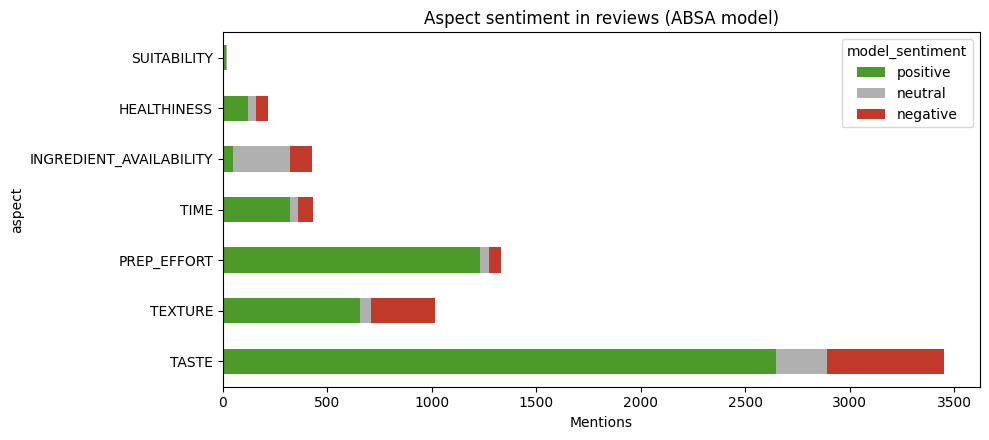


Reviews with at least one polar aspect: 3343 (66.9% of reviews)
... with both positive and negative aspects: 535 (16.0% of those)

--- Examples of mixed reviews ---
This recipe is great, it's also something you can serve for company. | Camzmom has made this for me many times. | This recipe sounds like a lot of steps | but it's not difficult it consistantly tastes great. | I've also made this recipe myself and it tastes just as great as when Camzmom made it for me. | Thanks for posting one of my favorite recipes!
     PREP_EFFORT              negative  evidence: 'steps' in 'This recipe sounds like a lot of steps'
     TASTE                    positive  evidence: 'tastes' in "but it's not difficult it consistantly tastes great."
     TASTE                    positive  evidence: 'tastes' in "I've also made this recipe myself and it tastes just as great as when Camzmom made it for me."
Pretty good. | I would add a little more spice because it seems a bit bland | but other than that, great

In [5]:
# Imports already made by task-1.py to task-3.py (same notebook): json, os, re, plt, nltk, np, pd, sns.
import torch
from nltk.sentiment import SentimentIntensityAnalyzer
from sklearn.metrics import cohen_kappa_score, f1_score
from transformers import pipeline

# Task 4: Aspect-Based Sentiment Analysis
# Run after load-dataset.py and task-1.py to task-3.py in the same notebook (this needs df_clauses,
# split_into_sentences, df_recipes, Task 2's LEXICONS and the earlier cells' imports).
# Kaggle: transformers is preinstalled; turn internet on so the ABSA model can be downloaded. A GPU is much faster.
# Sentiment is attached to an aspect in one clause, not to the whole review, so "delicious but difficult" gives
# positive TASTE and negative PREP_EFFORT. Rows keep clause offsets and ids so Task 5 (holder) and Task 6
# (negation, conditions) can attach to them, and Task 9 can cite the evidence span.

for required in ("df_clauses", "split_into_sentences", "df_recipes"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py in this session first.")

SEED = 42
N_REVIEWS = 5_000         # reviews whose clauses are analysed on the real data
ABSA_MODEL = "yangheng/deberta-v3-base-absa-v1.1"
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
nltk.download("vader_lexicon", quiet=True)

# SUITABILITY: how well the recipe fits an occasion the clause names ("great for weekend dinners").
ASPECTS = ["TASTE", "TEXTURE", "PREP_EFFORT", "TIME", "INGREDIENT_AVAILABILITY", "HEALTHINESS", "SUITABILITY"]
SENTIMENTS = ["positive", "neutral", "negative"]

# ==========================================
# 1. ASPECT CUES
# ==========================================
# cue -> prior polarity (+1, -1, or 0 when the cue names the aspect without judging it, e.g. "texture").
# Perceived healthiness comes only from the review text; nutrition scores are compared in section 6, never merged.
# Generic praise ("great", "loved it") names no aspect and produces no row, so it cannot be generalised to one.
ASPECT_CUES = {
    "TASTE": {
        "taste": 0, "tastes": 0, "tasted": 0, "flavor": 0, "flavour": 0, "flavors": 0, "flavours": 0, "seasoning": 0,
        "spicy": 0, "sweet": 0, "salty": 0, "flavorful": 1, "flavourful": 1, "delicious": 1, "tasty": 1, "yummy": 1,
        "scrumptious": 1, "savory": 1, "decadent": 1, "bland": -1, "flavorless": -1, "tasteless": -1, "boring": -1,
        "bitter": -1, "overpowering": -1, "too salty": -1, "too sweet": -1, "too spicy": -1, "too hot": -1,
        "too strong": -1, "lacked flavor": -1, "no flavor": -1, "not much flavor": -1,
    },
    "TEXTURE": {
        "texture": 0, "textures": 0, "consistency": 0, "chewy": 0, "soft": 0, "dense": 0, "moist": 1, "tender": 1,
        "crispy": 1, "crisp": 1, "crunchy": 1, "fluffy": 1, "creamy": 1, "juicy": 1, "flaky": 1, "smooth": 1,
        "gooey": 1, "mushy": -1, "soggy": -1, "dry": -1, "tough": -1, "rubbery": -1, "gummy": -1, "grainy": -1,
        "runny": -1, "watery": -1, "greasy": -1, "chalky": -1, "lumpy": -1, "too dense": -1, "too thick": -1,
        "too thin": -1,
    },
    "PREP_EFFORT": {
        "effort": 0, "prep": 0, "preparation": 0, "steps": 0, "easy": 1, "easier": 1, "simple": 1, "effortless": 1,
        "foolproof": 1, "fool proof": 1, "straightforward": 1, "no fuss": 1, "easy to make": 1, "easy to put together": 1,
        "difficult": -1, "hard to make": -1, "complicated": -1, "tricky": -1, "tedious": -1, "fussy": -1,
        "labor intensive": -1, "messy": -1, "a mess": -1, "a pain": -1, "challenging": -1, "too many steps": -1,
    },
    "TIME": {
        # "quickly" is left out: in reviews it is mostly an instruction ("work quickly"), not a judgement of time.
        "cooking time": 0, "prep time": 0, "baking time": 0, "quick": 1, "fast": 1, "in no time": 1,
        "time consuming": -1, "took forever": -1, "takes forever": -1, "too long": -1, "takes a while": -1,
        "took a while": -1, "all day": -1,
    },
    "INGREDIENT_AVAILABILITY": {
        "pantry": 0, "available": 0, "on hand": 1, "staples": 1, "common ingredients": 1, "simple ingredients": 1,
        "basic ingredients": 1, "easy to find": 1, "readily available": 1, "hard to find": -1, "couldn't find": -1,
        "could not find": -1, "can't find": -1, "cannot find": -1, "didn't have": -1, "did not have": -1,
        "don't have": -1, "ran out of": -1, "not available": -1, "unavailable": -1, "specialty store": -1,
    },
    "HEALTHINESS": {
        "calories": 0, "calorie": 0, "healthy": 1, "healthier": 1, "nutritious": 1, "wholesome": 1, "guilt free": 1,
        "lighter": 1, "low fat": 1, "low calorie": 1, "low cal": 1, "good for you": 1, "unhealthy": -1,
        "fattening": -1, "heavy": -1, "too rich": -1,
    },
}


def normalise(cue):
    return re.sub(r"[\s-]+", " ", cue.lower().replace("'", "").replace("’", ""))


CUE_INDEX = {normalise(cue): (aspect, prior) for aspect, cues in ASPECT_CUES.items() for cue, prior in cues.items()}
# Longest cue first so "easy to find" (availability) wins over "easy" (effort) and "too salty" over "salty".
_cue_patterns = [
    re.escape(cue).replace(r"\ ", r"[\s-]+").replace("'", "['’]?")
    for cue in sorted({c for cues in ASPECT_CUES.values() for c in cues}, key=len, reverse=True)
]
CUE_RE = re.compile(r"\b(?:" + "|".join(_cue_patterns) + r")\b", re.IGNORECASE)


# Cues that are often part of a product name: before an ingredient they describe what was bought, not how the dish
# turned out ("heavy cream", "low fat cheese", "dry white wine", "sweet potatoes", "creamy peanut butter"). Ingredient
# words come from the Task 2 lexicon in the same notebook. Other cues are kept before ingredients ("juicy chicken").
PRODUCT_CUES = {"heavy", "low fat", "low calorie", "low cal", "lighter", "dry", "sweet", "salty", "spicy", "smooth",
                "crunchy", "creamy", "soft"}
INGREDIENT_WORDS = set(LEXICONS["INGREDIENT"]) if "LEXICONS" in globals() else set()
INGREDIENT_WORDS |= {"cream", "cheese", "milk", "mayo", "mayonnaise", "yogurt", "yoghurt", "wine", "ingredients", "rub"}
NEXT_WORDS_RE = re.compile(r"[\s-]*([a-z']+)(?:\s+([a-z']+))?")


def is_product_or_idiom(clause, m, aspect):
    following = NEXT_WORDS_RE.match(clause[m.end():].lower())
    w1, w2 = (following.group(1), following.group(2) or "") if following else ("", "")
    if aspect == "INGREDIENT_AVAILABILITY" and w1 == "to":  # "don't have to", "didn't have to"
        return True
    return normalise(m.group(0)) in PRODUCT_CUES and (w1 in INGREDIENT_WORDS or f"{w1} {w2}" in INGREDIENT_WORDS)


# Occasion fit: a judgement word followed, within a few words, by an occasion from Task 2's lexicon ("great for
# weekend dinners", "perfect for a potluck", "a hit at our Christmas party"). Praise without an occasion ("great
# recipe") and an occasion without a judgement ("made it for Christmas") are not fits. Task 5 reads the occasion as the
# context, and Task 6's negation scope turns "not good for a weeknight" negative.
OCCASION_WORDS = sorted(LEXICONS["OCCASION"] if "LEXICONS" in globals() else
                        {"weeknight", "weeknights", "weekend", "weekends", "party", "potluck", "holiday", "holidays",
                         "christmas", "thanksgiving"}, key=len, reverse=True)
FIT_RE = re.compile(r"\b(?:great|perfect|good|ideal|nice|wonderful|excellent|fantastic|awesome|terrific|suitable|"
                    r"a (?:big |huge )?hit)(?:\s+[a-z']+){0,2}?\s+(?:for|at|on)\s+(?:[a-z'-]+\s+){0,3}?"
                    r"(?:" + "|".join(map(re.escape, OCCASION_WORDS)) + r")\b", re.IGNORECASE)


def find_mentions(clause):
    """One mention per aspect per clause: a polar cue is preferred over a neutral one, then the longer cue."""
    best = {}
    for m in CUE_RE.finditer(clause):
        aspect, prior = CUE_INDEX[normalise(m.group(0))]
        if is_product_or_idiom(clause, m, aspect):
            continue
        rank = (prior != 0, m.end() - m.start(), -m.start())
        if aspect not in best or rank > best[aspect][0]:
            best[aspect] = (rank, {"aspect": aspect, "cue": m.group(0), "start": m.start(), "end": m.end(), "prior": prior})
    fit = FIT_RE.search(clause)
    if fit:
        best["SUITABILITY"] = (None, {"aspect": "SUITABILITY", "cue": fit.group(0), "start": fit.start(),
                                      "end": fit.end(), "prior": 1})
    return [mention for _, mention in best.values()]


# ==========================================
# 2. SENTIMENT: LEXICON BASELINE AND PRETRAINED ABSA MODEL
# ==========================================
NEGATORS = {"not", "no", "never", "hardly", "without", "nothing", "isnt", "wasnt", "arent", "werent", "dont",
            "doesnt", "didnt", "cant", "cannot", "couldnt", "wouldnt", "wont", "aint"}
vader = SentimentIntensityAnalyzer()


def lexicon_sentiment(clause, mention):
    """The cue's prior, flipped by a negator in the three words before it ("not too difficult" -> positive).
    Cues without a prior ("texture") take the VADER score of the clause; "too" before them is negative."""
    before = [w.replace("'", "").replace("’", "") for w in re.findall(r"[\w'’]+", clause[:mention["start"]].lower())[-3:]]
    if mention["prior"]:
        polarity = -mention["prior"] if any(w in NEGATORS for w in before) else mention["prior"]
    elif before[-1:] == ["too"]:
        polarity = -1
    else:
        compound = vader.polarity_scores(clause)["compound"]
        polarity = 1 if compound >= 0.05 else -1 if compound <= -0.05 else 0
    return {1: "positive", 0: "neutral", -1: "negative"}[polarity]


device = 0 if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else -1)
absa = pipeline("text-classification", model=ABSA_MODEL, device=device)


def model_sentiment(pairs, batch_size=64):
    """pairs: [(clause, cue)]. The model scores sentiment toward the cue inside the clause."""
    if not pairs:
        return []
    out = absa([{"text": c, "text_pair": a} for c, a in pairs], batch_size=batch_size, truncation=True)
    return [(o["label"].lower(), o["score"]) for o in out]


def analyse(clause_texts):
    """Aspect mentions with both sentiments for a list of clauses. Returns one dict per mention."""
    mentions = [dict(m, clause_pos=i) for i, text in enumerate(clause_texts) for m in find_mentions(text)]
    predictions = model_sentiment([(clause_texts[m["clause_pos"]], m["cue"]) for m in mentions])
    for m, (label, score) in zip(mentions, predictions):
        m["lexicon_sentiment"] = lexicon_sentiment(clause_texts[m["clause_pos"]], m)
        m["model_sentiment"], m["model_score"] = label, score
    return mentions


# ==========================================
# 3. EVALUATION SET (small, hand-written pilot gold)
# ==========================================
# Whole reviews, split into clauses exactly as in Task 1. Gold is a set of (aspect, sentiment) per review; an aspect
# can appear with two sentiments ("too spicy" for one diner, "loved the heat" for another). Some items are
# deliberately beyond the lexicon ("took me all afternoon", "melted in your mouth"). Extend with Task 10 annotations.
P, N, O = "positive", "negative", "neutral"
GOLD = [
    ("This was delicious but difficult to make.", {("TASTE", P), ("PREP_EFFORT", N)}),
    ("Quick and easy weeknight dinner, and the kids loved the flavor.", {("TIME", P), ("PREP_EFFORT", P), ("TASTE", P)}),
    ("The texture was mushy and it was way too salty.", {("TEXTURE", N), ("TASTE", N)}),
    ("Not too difficult, but it took forever.", {("PREP_EFFORT", P), ("TIME", N)}),
    ("I had everything on hand, which is always a plus.", {("INGREDIENT_AVAILABILITY", P)}),
    ("I couldn't find tamarind paste anywhere, so I used lime juice.", {("INGREDIENT_AVAILABILITY", N)}),
    ("A nice healthy dinner that doesn't taste like diet food.", {("HEALTHINESS", P), ("TASTE", P)}),
    ("Way too heavy and greasy for us.", {("HEALTHINESS", N), ("TEXTURE", N)}),
    ("Great recipe, thanks for posting!", set()),
    ("The chicken was moist and tender.", {("TEXTURE", P)}),
    ("Bland. Needed a lot more seasoning.", {("TASTE", N)}),
    ("Very time-consuming, but worth it for the flavor.", {("TIME", N), ("TASTE", P)}),
    ("Ready in 20 minutes, which is perfect for busy nights.", {("TIME", P)}),
    ("Too many steps and too many dishes to wash.", {("PREP_EFFORT", N)}),
    ("Crispy on the outside and fluffy inside.", {("TEXTURE", P)}),
    ("My husband said it was too spicy, but I loved the heat.", {("TASTE", N), ("TASTE", P)}),
    ("Uses simple ingredients that I always keep in my pantry.", {("INGREDIENT_AVAILABILITY", P)}),
    ("I would not call this healthy with all that butter.", {("HEALTHINESS", N)}),
    ("It was a bit dry.", {("TEXTURE", N)}),
    ("The flavor was ok, nothing special.", {("TASTE", O)}),
    ("Easy to put together the night before.", {("PREP_EFFORT", P)}),
    ("Lighter than most versions and still very satisfying.", {("HEALTHINESS", P)}),
    ("Rich, decadent and totally worth the calories.", {("TASTE", P), ("HEALTHINESS", N)}),
    ("The sauce was watery and lacked flavor.", {("TEXTURE", N), ("TASTE", N)}),
    ("It took me all afternoon.", {("TIME", N)}),
    ("I had to go to three stores to find sumac.", {("INGREDIENT_AVAILABILITY", N)}),
    ("Melted in your mouth.", {("TEXTURE", P)}),
    ("Perfect for a potluck.", {("SUITABILITY", P)}),
    ("I halved the recipe and it worked fine.", set()),
    ("So simple, even my teenager can make it.", {("PREP_EFFORT", P)}),
    ("Way too sweet for my taste.", {("TASTE", N)}),
    ("The crust was soggy but the filling tasted amazing.", {("TEXTURE", N), ("TASTE", P)}),
    ("Low fat and you would never know it.", {("HEALTHINESS", P)}),
    ("Not something I'd call quick.", {("TIME", N)}),
    ("The prep was a pain, but the result was delicious.", {("PREP_EFFORT", N), ("TASTE", P)}),
    ("Chewy, gooey and just sweet enough.", {("TEXTURE", P), ("TASTE", P)}),
    ("We'll make it again.", set()),
    ("It's a guilt-free treat my whole family enjoys.", {("HEALTHINESS", P)}),
    ("The meat came out tough.", {("TEXTURE", N)}),
    ("Pretty fast once the vegetables are chopped, though the chopping takes a while.", {("TIME", P), ("TIME", N)}),
    ("I love spicy food, but this was too hot for my children.", {("TASTE", P), ("TASTE", N)}),
    ("Great for weekend dinners, but too time-consuming for weekdays.", {("SUITABILITY", P), ("TIME", N)}),
    ("It was a big hit at our Christmas party.", {("SUITABILITY", P)}),
    ("Not good for a weeknight, too many steps.", {("SUITABILITY", N), ("PREP_EFFORT", N)}),
    ("I made it for Christmas.", set()),
]


def predict_reviews(texts):
    """Per review: {(aspect, sentiment)} for both methods, from its Task 1 clauses."""
    clauses, owner = [], []
    for i, text in enumerate(texts):
        for clause in split_into_sentences(text):
            clauses.append(clause)
            owner.append(i)
    mentions = analyse(clauses)
    preds = {"lexicon": [set() for _ in texts], "ABSA model": [set() for _ in texts]}
    for m in mentions:
        review = owner[m["clause_pos"]]
        preds["lexicon"][review].add((m["aspect"], m["lexicon_sentiment"]))
        preds["ABSA model"][review].add((m["aspect"], m["model_sentiment"]))
    return preds


def prf(gold_sets, pred_sets):
    tp = sum(len(g & p) for g, p in zip(gold_sets, pred_sets))
    fp = sum(len(p - g) for g, p in zip(gold_sets, pred_sets))
    fn = sum(len(g - p) for g, p in zip(gold_sets, pred_sets))
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    return prec, rec, (2 * prec * rec / (prec + rec) if prec + rec else 0.0)


gold_texts = [t for t, _ in GOLD]
gold_sets = [g for _, g in GOLD]
gold_preds = predict_reviews(gold_texts)

rows = []
for method, preds in gold_preds.items():
    aspect_only = prf([{a for a, _ in g} for g in gold_sets], [{a for a, _ in p} for p in preds])
    pairs = prf(gold_sets, preds)
    # Sentiment on aspects both gold and prediction have with a single sentiment (macro-F1 over the three classes).
    y_true, y_pred = [], []
    for g, p in zip(gold_sets, preds):
        g_by, p_by = {}, {}
        for a, s in g:
            g_by.setdefault(a, set()).add(s)
        for a, s in p:
            p_by.setdefault(a, set()).add(s)
        for a in g_by.keys() & p_by.keys():
            if len(g_by[a]) == 1 and len(p_by[a]) == 1:
                y_true.append(next(iter(g_by[a])))
                y_pred.append(next(iter(p_by[a])))
    rows.append({
        "method": method, "aspect P": aspect_only[0], "aspect R": aspect_only[1], "aspect F1": aspect_only[2],
        "aspect+sentiment P": pairs[0], "aspect+sentiment R": pairs[1], "aspect+sentiment F1": pairs[2],
        "sentiment macro-F1": f1_score(y_true, y_pred, labels=SENTIMENTS, average="macro", zero_division=0),
        "sentiment n": len(y_true),
    })
gold_results = pd.DataFrame(rows).set_index("method")
print(f"\n--- Gold evaluation on {len(GOLD)} hand-written reviews ---")
with pd.option_context("display.width", 250, "display.max_columns", None):
    print(gold_results.round(3))

per_aspect = pd.DataFrame({
    method: {a: prf([{x for x in g if x[0] == a} for g in gold_sets], [{x for x in p if x[0] == a} for p in preds])[2]
             for a in ASPECTS}
    for method, preds in gold_preds.items()
})
print("\n--- Aspect+sentiment F1 per aspect (gold) ---")
print(per_aspect.round(3))

print("\n--- Gold errors ---")
for text, g, lex, mod in zip(gold_texts, gold_sets, gold_preds["lexicon"], gold_preds["ABSA model"]):
    if g != lex or g != mod:
        print(f"{text}\n   gold   {sorted(g)}\n   lexicon {sorted(lex)}\n   model  {sorted(mod)}")

# ==========================================
# 4. REAL REVIEWS
# ==========================================
review_rows = df_clauses["review_row"].drop_duplicates().sample(min(N_REVIEWS, df_clauses["review_row"].nunique()),
                                                                 random_state=SEED)
df_apply = df_clauses[df_clauses["review_row"].isin(review_rows)].reset_index(drop=True)
apply_texts = df_apply["sentences"].astype(str).tolist()
mentions = analyse(apply_texts)

id_cols = [c for c in ("review_row", "review_id", "member_id", "recipe_id", "rating", "clause_idx") if c in df_apply.columns]
df_aspects = pd.DataFrame([
    {**df_apply.loc[m["clause_pos"], id_cols].to_dict(), "clause": apply_texts[m["clause_pos"]], "aspect": m["aspect"],
     "cue": m["cue"], "start": m["start"], "end": m["end"], "lexicon_sentiment": m["lexicon_sentiment"],
     "model_sentiment": m["model_sentiment"], "model_score": round(m["model_score"], 4)}
    for m in mentions
], columns=id_cols + ["clause", "aspect", "cue", "start", "end", "lexicon_sentiment", "model_sentiment", "model_score"])

n_reviews = df_apply["review_row"].nunique()
print(f"\n--- {len(df_aspects)} aspect mentions in {len(df_apply)} clauses from {n_reviews} reviews ---")
dist = pd.crosstab(df_aspects["aspect"], df_aspects["model_sentiment"]).reindex(index=ASPECTS, columns=SENTIMENTS).fillna(0).astype(int)
dist["reviews with aspect (%)"] = (df_aspects.groupby("aspect")["review_row"].nunique().reindex(ASPECTS).fillna(0) / n_reviews * 100).round(1)
print(dist)

dist[SENTIMENTS].plot(kind="barh", stacked=True, figsize=(10, 4.5), color=["#4c9a2a", "#b0b0b0", "#c0392b"],
                      title="Aspect sentiment in reviews (ABSA model)")
plt.xlabel("Mentions")
plt.tight_layout()
plt.show()

# Several sentiments in one review: the reason sentiment is kept per aspect instead of per review.
polar = df_aspects[df_aspects["model_sentiment"] != "neutral"]
per_review = polar.groupby("review_row")["model_sentiment"].agg(set)
mixed = per_review[per_review.map(len) == 2]
print(f"\nReviews with at least one polar aspect: {len(per_review)} ({len(per_review) / n_reviews:.1%} of reviews)")
print(f"... with both positive and negative aspects: {len(mixed)} ({len(mixed) / max(len(per_review), 1):.1%} of those)")
print("\n--- Examples of mixed reviews ---")
for review_row in mixed.index[:5]:
    print(" | ".join(df_apply.loc[df_apply["review_row"] == review_row, "sentences"]))
    for r in polar[polar["review_row"] == review_row].itertuples():
        print(f"     {r.aspect:<24} {r.model_sentiment:<9} evidence: {r.clause[r.start:r.end]!r} in {r.clause!r}")

# Agreement between the two methods on the same mentions.
print("\n--- Lexicon vs ABSA model agreement per aspect ---")
agree = df_aspects.groupby("aspect").apply(lambda g: pd.Series({
    "mentions": len(g), "agreement": (g["lexicon_sentiment"] == g["model_sentiment"]).mean(),
    "kappa": cohen_kappa_score(g["lexicon_sentiment"], g["model_sentiment"]) if g["lexicon_sentiment"].nunique() > 1 else np.nan,
}), include_groups=False).reindex(ASPECTS)
print(agree.round(3))

# Sanity check against star ratings (explicit 1-5 only): positive aspects should come from higher-rated reviews.
if "rating" in df_aspects.columns:
    rated = df_aspects[df_aspects["rating"].isin([1, 2, 3, 4, 5])]
    rating_table = rated.pivot_table(index="aspect", columns="model_sentiment", values="rating", aggfunc="mean")
    print("\n--- Mean star rating by aspect sentiment (ABSA model) ---")
    print(rating_table.reindex(index=ASPECTS, columns=SENTIMENTS).round(2))

# ==========================================
# 5. PERCEIVED HEALTHINESS VS NUTRITION (kept separate)
# ==========================================
# HUMMUS scores are 0-1, higher = healthier. Perceived healthiness is what the reviewer says; the scores are measured
# on the recipe. They are compared here and stored in separate columns, never combined.
health_cols = [c for c in ("who_score", "fsa_score", "nutri_score") if c in df_recipes.columns]
health = df_aspects[df_aspects["aspect"] == "HEALTHINESS"]
if health_cols and len(health):
    health = health.merge(df_recipes[["recipe_id"] + health_cols].drop_duplicates("recipe_id"), on="recipe_id", how="left")
    print("\n--- Recipe nutrition scores by perceived healthiness (separate signals) ---")
    print(health.groupby("model_sentiment")[health_cols].agg(["mean", "count"]).reindex(SENTIMENTS).round(3))
    polarity = health["model_sentiment"].map({"positive": 1, "neutral": 0, "negative": -1})
    for col in health_cols:
        print(f"Spearman(perceived healthiness, {col}) = {polarity.corr(health[col], method='spearman'):.3f}")

# ==========================================
# 6. OUTPUTS
# ==========================================
df_aspects.to_csv(os.path.join(OUT_DIR, "task4_aspect_sentiments.csv"), index=False)

# Same 200 pilot reviews as the Task 2 annotation sheet, so one annotation pass covers entities and aspects.
pilot_rows = sorted(df_clauses["review_row"].drop_duplicates().sample(200, random_state=SEED))
pilot = df_clauses[df_clauses["review_row"].isin(pilot_rows)].reset_index(drop=True)
pilot_mentions = analyse(pilot["sentences"].astype(str).tolist())
pilot["predicted_aspects"] = [
    json.dumps([[m["start"], m["end"], m["aspect"], m["model_sentiment"]] for m in pilot_mentions if m["clause_pos"] == i])
    for i in range(len(pilot))
]
pilot["corrected_aspects"] = ""  # fill in by hand: [[start, end, ASPECT, sentiment], ...]
pilot.to_csv(os.path.join(OUT_DIR, "task4_pilot_annotation.csv"), index=False)
print(f"\nSaved {len(df_aspects)} aspect mentions and a {len(pilot)}-clause pilot sheet in {OUT_DIR}.")


# Task 5

In [6]:
# Imports already made by task-1.py to task-4.py (same notebook): json, os, re, np, pd, spacy, torch, cohen_kappa_score,
# f1_score.
from transformers import AutoModelForCausalLM, AutoTokenizer

# Task 5: Preference-Holder and Relation Extraction
# Run after task-4.py in the same notebook (uses df_aspects and analyse from Task 4, df_clauses and
# split_into_sentences from Task 1, OCCASIONS and plural_variants from Task 2).
# Each Task 4 aspect mention becomes a tuple (holder, aspect, sentiment, context, evidence span). Aspect, sentiment and
# evidence come from Task 4; this task adds:
#   holder:  reviewer, children, partner, family, guests, or unknown when it cannot be told who holds the opinion
#   context: the occasion the opinion is tied to (weekday, weekend, holiday, gathering, special occasion),
#            general when none is named, unknown when the clause names two different ones
# Two extractors are compared: dependency-parsing rules (spaCy) and a free, open LLM (Qwen3-4B-Instruct, run locally
# with transformers, no account or key) that must answer in a fixed JSON schema. The model is downloaded once (8 GB,
# internet on); a GPU (Kaggle: Settings > Accelerator) makes it fast. Without it the rules alone produce the tuples.

for required in ("df_aspects", "analyse", "df_clauses", "split_into_sentences", "OCCASIONS", "plural_variants"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-4.py in this session first.")

SEED = 42
N_LLM_REVIEWS = 40        # real reviews also labelled by the LLM, to measure agreement with the rules
LLM_MODEL = "Qwen/Qwen3-4B-Instruct-2507"  # Apache-2.0; "Qwen/Qwen2.5-1.5B-Instruct" is smaller and faster on CPU
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# ==========================================
# 1. LABELS
# ==========================================
HOLDERS = ["reviewer", "children", "partner", "family", "guests", "unknown"]
HOLDER_WORDS = {
    "reviewer": "i me my myself",
    # No "baby", "boy" or "girl": in reviews they are mostly food ("baby carrots") or "oh boy".
    "children": "kid kids kiddo kiddos child children toddler toddlers son sons daughter daughters boys girls teen "
                "teens teenager teenagers grandkids grandchildren ds dd",
    "partner": "husband wife hubby partner boyfriend girlfriend fiance fiancee spouse dh dw bf",
    "family": "we us our ourselves family parents mom mother dad father sister brother grandma grandpa laws",  # in-laws
    "guests": "guest guests company friend friends crowd coworkers neighbors visitors",
    # Pronouns whose referent is outside the clause. "they"/"it" are left out: in reviews they are mostly the food.
    "unknown": "he she him her everyone everybody",
}
HOLDER_OF = {word: holder for holder, words in HOLDER_WORDS.items() for word in words.split()}
FIRST_PERSON = {"i", "me", "my", "myself", "we", "us", "our", "ourselves"}
COOK_ASPECTS = {"PREP_EFFORT", "TIME", "INGREDIENT_AVAILABILITY"}  # judged by whoever cooked: the reviewer

# Task 2's occasions, grouped into the contexts a profile is kept under.
CONTEXT_GROUPS = {
    "weekday": ["weeknight", "weekday", "school night", "work night", "lunchbox"],
    "weekend": ["weekend", "sunday dinner"],
    "holiday": ["holiday", "christmas", "thanksgiving", "easter", "new year's eve", "valentine's day", "halloween",
                "hanukkah"],
    "gathering": ["party", "dinner party", "cocktail party", "potluck", "bbq", "barbecue", "cookout", "picnic",
                  "game day", "super bowl", "tailgate", "baby shower", "wedding"],
    "special occasion": ["special occasion", "birthday", "anniversary", "date night"],
}
CONTEXTS = list(CONTEXT_GROUPS) + ["general", "unknown"]
CONTEXT_OF = {occasion: context for context, occasions in CONTEXT_GROUPS.items() for occasion in occasions}
OCCASION_FORMS = {form: base for base in OCCASIONS for form in plural_variants(base)}
OCCASION_RE = re.compile(r"\b(?:" + "|".join(map(re.escape, sorted(OCCASION_FORMS, key=len, reverse=True))) + r")\b",
                         re.IGNORECASE)

# ==========================================
# 2. DEPENDENCY-PARSING RULES
# ==========================================
try:
    nlp_dep = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])
except OSError:  # not installed: download it (needs internet)
    spacy.cli.download("en_core_web_sm")
    nlp_dep = spacy.load("en_core_web_sm", disable=["ner", "lemmatizer"])

CLIMB_DEPS = {"ccomp", "xcomp", "pcomp", "advcl", "prep", "pobj"}  # "my husband said [it was too salty]"


def person(token):
    """Holder class of a word naming people, else None. 'for my taste' is the reviewer."""
    if token.lower_ in ("taste", "liking"):
        token = next((c for c in token.children if c.dep_ == "poss"), token)
    return HOLDER_OF.get(token.lower_)


def experiencer(token):
    """Person the opinion word is judged for: 'too hot for my children', 'spicy enough for my husband', 'dry for my
    taste', 'easy enough for my teen to make'. A plain 'great for company' says who the dish suits, so it is ignored."""
    graded = any(c.lower_ in ("too", "enough") for c in token.children)
    for f in [*token.children, *token.head.children]:  # 'for' on the opinion word or on its verb
        if f.lower_ == "for" and f.dep_ == "prep":
            for target in f.children:
                if target.dep_ == "pobj" and (graded or target.lower_ in ("taste", "liking")) and person(target):
                    return person(target)
    for clause in token.children:  # 'for my teen to make'
        if clause.dep_ in ("advcl", "xcomp") and any(c.lower_ == "for" and c.dep_ == "mark" for c in clause.children):
            subject = next((c for c in clause.children if c.dep_ == "nsubj"), None)
            if subject is not None and person(subject):
                return person(subject)
    return None


def subject_holder(subject):
    """Holder named by a subject; two people ('my husband and I', 'my husband and daughter') are the family."""
    holders = {person(t) for t in [subject, *subject.conjuncts]} - {None}
    return holders.pop() if len(holders) == 1 else "family" if holders else None


def rule_holder(doc, start, end, aspect):
    """An experiencer phrase on the opinion word, else the subject of the first verb above it. A non-person subject
    ("it was too salty") ends the walk unless that clause is the complement of a verb with a person subject
    ("my husband said ...", "the kids thought ..."). Coordinated verbs are not crossed."""
    token = doc.char_span(start, end, alignment_mode="expand").root
    holder = experiencer(token)
    if holder or aspect in COOK_ASPECTS:  # effort, time and availability are judged by whoever cooked: the reviewer
        return holder or "reviewer"
    while True:
        subject = next((c for c in token.children if c.dep_ in ("nsubj", "nsubjpass")), None)
        if subject is not None:
            holder = subject_holder(subject)
            if holder:
                return holder
            if token.dep_ not in CLIMB_DEPS:
                break
        if token.dep_ == "ROOT" or (token.dep_ == "conj" and token.pos_ in ("VERB", "AUX")):
            break
        token = token.head
    # No holder in the syntax: for taste, texture and healthiness, a person named elsewhere in the clause
    # ("made it for my kids and it was too spicy") makes the holder unclear. People named with an occasion fit are its
    # audience ("great for a party with friends"), so the fit is the reviewer's.
    others = [t for t in doc if t.lower_ in HOLDER_OF and t.lower_ not in FIRST_PERSON
              and t.dep_ not in ("compound", "poss")]
    return "unknown" if others and aspect != "SUITABILITY" else "reviewer"


def rule_context(clause):
    """Context of the occasion named in the clause. Adjacent occasion words are one phrase, named by its last word
    ("Christmas party" -> gathering)."""
    spans = []
    for m in OCCASION_RE.finditer(clause):
        base = OCCASION_FORMS[m.group(0).lower()]
        context = CONTEXT_OF.get(base, base)
        if spans and not clause[spans[-1][1]:m.start()].strip():
            spans[-1] = (spans[-1][0], m.end(), context)
        else:
            spans.append((m.start(), m.end(), context))
    contexts = {c for _, _, c in spans}
    return "general" if not contexts else contexts.pop() if len(contexts) == 1 else "unknown"


def rules_label(mentions):
    """mentions: DataFrame with clause, start, end, aspect -> lists of holders and contexts."""
    docs = dict(zip(mentions["clause"].unique(), nlp_dep.pipe(mentions["clause"].unique(), batch_size=256)))
    holders = [rule_holder(docs[c], s, e, a) for c, s, e, a in mentions[["clause", "start", "end", "aspect"]].itertuples(index=False)]
    return holders, [rule_context(c) for c in mentions["clause"]]


# ==========================================
# 3. LLM WITH A FIXED OUTPUT SCHEMA (free, open model run locally)
# ==========================================
# One prompt per mention. The answer must be a JSON object using only the labels above; anything else is a schema
# violation and becomes "unknown".
ANSWER_FORMAT = '{"holder": "<' + "|".join(HOLDERS) + '>", "context": "<' + "|".join(CONTEXTS) + '>"}'
LLM_INSTRUCTIONS = """You label opinions in recipe reviews from Food.com. You get a review, one clause from it, and a \
word in that clause that carries an opinion about an aspect of the recipe. Decide:
- holder: whose opinion it is. "reviewer" is the person who wrote the review, also when nobody else is named. \
"children" are the reviewer's kids or grandkids, "partner" is a husband, wife, boyfriend or girlfriend, "family" is the \
household as a group ("we", "the whole family") or other relatives, and "guests" are friends, company or people at a \
party. Use "unknown" when the review does not make clear whose opinion it is.
- context: the occasion the opinion is tied to. "weekday" (weeknights, school nights, packed lunches), "weekend", \
"holiday" (Christmas, Thanksgiving, Easter and other holidays), "gathering" (parties, potlucks, barbecues, game day), \
"special occasion" (birthdays, anniversaries, date night), "general" when no occasion is named for that opinion, or \
"unknown" when it is unclear which named occasion applies.
Use only what the review says. Answer with one JSON object and nothing else: """ + ANSWER_FORMAT

llm_device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
try:
    llm_tokenizer = AutoTokenizer.from_pretrained(LLM_MODEL, padding_side="left")
    llm = AutoModelForCausalLM.from_pretrained(LLM_MODEL, dtype=torch.float32 if llm_device == "cpu" else torch.float16)
    llm = llm.to(llm_device).eval()
except OSError as e:  # the model could not be downloaded (internet off)
    llm = None
    print(f"LLM comparison skipped: could not load {LLM_MODEL} ({type(e).__name__}). Turn internet on to download it.")


def parse_answer(text):
    """(holder, context, valid) from the model's answer; labels outside the schema become 'unknown'."""
    match = re.search(r"\{.*?\}", text, re.DOTALL)
    try:
        answer = json.loads(match.group(0)) if match else {}
    except json.JSONDecodeError:
        answer = {}
    holder, context = answer.get("holder"), answer.get("context")
    valid = holder in HOLDERS and context in CONTEXTS
    return (holder if holder in HOLDERS else "unknown"), (context if context in CONTEXTS else "unknown"), valid


def llm_label(mentions, review_texts, batch_size=8):
    """mentions: DataFrame with review, aspect, cue, clause; review_texts: {review: text}. Greedy decoding."""
    prompts = [llm_tokenizer.apply_chat_template(
        [{"role": "system", "content": LLM_INSTRUCTIONS},
         {"role": "user", "content": f'Review: {review_texts[review]}\nClause: {clause}\nOpinion word: "{cue}" ({aspect})'}],
        tokenize=False, add_generation_prompt=True)
        for review, aspect, cue, clause in mentions[["review", "aspect", "cue", "clause"]].itertuples(index=False)]
    answers = []
    for i in range(0, len(prompts), batch_size):
        batch = llm_tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(llm_device)
        with torch.no_grad():
            output = llm.generate(**batch, max_new_tokens=40, do_sample=False)
        answers += llm_tokenizer.batch_decode(output[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
    labels = [parse_answer(a) for a in answers]
    print(f"LLM answers outside the schema: {sum(not valid for _, _, valid in labels)} of {len(labels)}")
    return [h for h, _, _ in labels], [c for _, c, _ in labels]


# ==========================================
# 4. EVALUATION SET (small, hand-written pilot gold)
# ==========================================
# Whole reviews, split into clauses and aspects exactly as in Tasks 1 and 4. Gold: {cue: (holder, context)}. Some items
# need information the rules cannot use: "they" referring to the kids, "everyone" at a party. Extend with Task 10.
GOLD = [
    ("I love spicy food, but this was too hot for my children.",
     {"spicy": ("reviewer", "general"), "too hot": ("children", "general")}),
    ("My husband said it was too salty.", {"too salty": ("partner", "general")}),
    ("The kids loved the flavor.", {"flavor": ("children", "general")}),
    ("Too time-consuming for weeknights, but perfect for the weekend.",
     {"time-consuming": ("reviewer", "weekday"), "perfect for the weekend": ("reviewer", "weekend")}),
    ("Quick and easy for a busy weeknight.", {"quick": ("reviewer", "weekday"), "easy": ("reviewer", "weekday")}),
    ("My guests raved about how moist it was.", {"moist": ("guests", "general")}),
    ("It was a bit dry for my taste.", {"dry": ("reviewer", "general"), "taste": ("reviewer", "general")}),
    ("We served it at our Christmas party and the texture was perfect.", {"texture": ("reviewer", "gathering")}),
    ("My son thought it was bland.", {"bland": ("children", "general")}),
    ("My wife found the sauce too sweet.", {"too sweet": ("partner", "general")}),
    ("Made this for my kids and it was too spicy.", {"too spicy": ("unknown", "general")}),
    ("Easy to make, and my husband loved the flavor.",
     {"easy to make": ("reviewer", "general"), "flavor": ("partner", "general")}),
    ("The whole family thought it was delicious.", {"delicious": ("family", "general")}),
    ("Everyone at the potluck said it was delicious.", {"delicious": ("guests", "gathering")}),
    ("Too heavy for a weeknight dinner.", {"heavy": ("reviewer", "weekday")}),
    ("Our guests found it a little dry.", {"dry": ("guests", "general")}),
    ("Perfect texture.", {"texture": ("reviewer", "general")}),
    ("My toddler wouldn't eat it because it was too spicy.", {"too spicy": ("children", "general")}),
    ("I thought it was great but my husband found it bland.", {"bland": ("partner", "general")}),
    ("We had it for Thanksgiving and it was a little bland.", {"bland": ("reviewer", "holiday")}),
    ("We loved how crispy it was.", {"crispy": ("family", "general")}),
    ("Great for a quick weeknight dinner.",
     {"quick": ("reviewer", "weekday"), "great for a quick weeknight": ("reviewer", "weekday")}),
    ("Took forever, so it's only for special occasions.", {"took forever": ("reviewer", "special occasion")}),
    ("My mother-in-law said the crust was soggy.", {"soggy": ("family", "general")}),
    ("Our friends couldn't stop talking about how tender the meat was.", {"tender": ("guests", "general")}),
    ("It was easy enough for my teenager to make.", {"easy": ("children", "general")}),
    ("I couldn't find tahini, so I used peanut butter.", {"couldn't find": ("reviewer", "general")}),
    ("Healthy and filling.", {"healthy": ("reviewer", "general")}),
    ("Too salty for us.", {"too salty": ("family", "general")}),
    ("The texture was too mushy for my boyfriend.", {"mushy": ("partner", "general")}),
    ("Made it for a birthday party and the frosting was too sweet.", {"too sweet": ("reviewer", "gathering")}),
    ("The guests loved it, though it was a bit dry.", {"dry": ("reviewer", "general")}),
    ("I'd make it for company because it is easy.", {"easy": ("reviewer", "general")}),
    ("He said it was too dry.", {"dry": ("unknown", "general")}),
    ("My family and I thought it was delicious.", {"delicious": ("family", "general")}),
    ("Our dinner guests at Easter said the lamb was tender.", {"tender": ("guests", "holiday")}),
    ("My kids are picky, but they loved the flavor.", {"flavor": ("children", "general")}),
    ("For a school night this was quick, and the kids thought it was yummy.",
     {"quick": ("reviewer", "weekday"), "yummy": ("children", "weekday")}),
    ("Spicy enough for my husband.", {"spicy": ("partner", "general")}),
    ("We made it for a Super Bowl party and everyone said it was too salty.", {"too salty": ("guests", "gathering")}),
]


def mentions_for(texts):
    """Task 4 aspect mentions (with sentiment) for whole reviews, from their Task 1 clauses."""
    clauses, owner = [], []
    for i, text in enumerate(texts):
        for clause in split_into_sentences(text):
            clauses.append(clause)
            owner.append(i)
    return pd.DataFrame([dict(m, review=owner[m["clause_pos"]], clause=clauses[m["clause_pos"]]) for m in analyse(clauses)])


gold_texts = [text for text, _ in GOLD]
gold_mentions = mentions_for(gold_texts)
gold_mentions["gold"] = [GOLD[r][1].get(cue.lower()) for r, cue in zip(gold_mentions["review"], gold_mentions["cue"])]
unlabelled = gold_mentions["gold"].isna()
if unlabelled.any():
    print("Mentions without a gold label (not scored):", gold_mentions.loc[unlabelled, ["review", "cue"]].values.tolist())
gold_mentions = gold_mentions[~unlabelled].reset_index(drop=True)
missed = sum(len(g) for _, g in GOLD) - len(gold_mentions)
if missed:
    print(f"{missed} gold cues were not found as Task 4 mentions (not scored).")

methods = {"dependency rules": rules_label(gold_mentions)}
if llm is not None:
    methods["LLM (fixed schema)"] = llm_label(gold_mentions, dict(enumerate(gold_texts)))


def score(holders, contexts, gold):
    gold_h, gold_c = [g[0] for g in gold], [g[1] for g in gold]
    return {
        "holder accuracy": np.mean([h == g for h, g in zip(holders, gold_h)]),
        "holder macro-F1": f1_score(gold_h, holders, labels=sorted(set(gold_h)), average="macro", zero_division=0),
        "context accuracy": np.mean([c == g for c, g in zip(contexts, gold_c)]),
        "tuple accuracy": np.mean([(h, c) == g for h, c, g in zip(holders, contexts, gold)]),
        "unknown holders": int(sum(h == "unknown" for h in holders)),
    }


print(f"\n--- Gold evaluation: {len(gold_mentions)} aspect mentions in {len(GOLD)} hand-written reviews "
      f"(gold unknown holders: {sum(g[0] == 'unknown' for g in gold_mentions['gold'])}) ---")
with pd.option_context("display.width", 250, "display.max_columns", None):
    print(pd.DataFrame({name: score(h, c, gold_mentions["gold"]) for name, (h, c) in methods.items()}).T.round(3))

print("\n--- Gold errors ---")
for i, row in gold_mentions.iterrows():
    predicted = {name: (h[i], c[i]) for name, (h, c) in methods.items()}
    if any(p != row["gold"] for p in predicted.values()):
        print(f"{gold_texts[row['review']]}  [{row['cue']}]\n   gold {row['gold']}  " +
              "  ".join(f"{name} {p}" for name, p in predicted.items()))

# ==========================================
# 5. PREFERENCE TUPLES FOR THE REAL REVIEWS
# ==========================================
df_tuples = df_aspects.rename(columns={"model_sentiment": "sentiment"}).copy()
df_tuples["holder"], df_tuples["context"] = rules_label(df_tuples)
df_tuples["evidence"] = df_tuples["clause"]  # the clause the sentiment was read from; cue offsets are start/end

n_reviews = df_tuples["review_row"].nunique()
print(f"\n--- Rule-based tuples: {len(df_tuples)} from {n_reviews} reviews ---")
print(pd.crosstab(df_tuples["holder"], df_tuples["sentiment"], margins=True).reindex(HOLDERS + ["All"]).fillna(0).astype(int))
print("\nContexts:", df_tuples["context"].value_counts().to_dict())
others = df_tuples[~df_tuples["holder"].isin(["reviewer", "unknown"])]
print(f"Opinions held by someone other than the reviewer: {len(others)} ({len(others) / len(df_tuples):.1%}); "
      f"a profile without holders would credit all of them to the reviewer.")
print("\n--- Examples of tuples not held by the reviewer ---")
for r in others.sample(min(8, len(others)), random_state=SEED).itertuples():
    print(f"({r.holder}, {r.aspect}, {r.sentiment}, {r.context}, {r.evidence!r})")

# LLM on a sample of real reviews: agreement with the rules on the same mentions.
if llm is not None:
    sample_rows = df_tuples["review_row"].drop_duplicates().sample(min(N_LLM_REVIEWS, n_reviews), random_state=SEED)
    sample = df_tuples[df_tuples["review_row"].isin(sample_rows)].rename(columns={"review_row": "review"})
    review_texts = df_clauses[df_clauses["review_row"].isin(sample_rows)].groupby("review_row")["sentences"].agg(" ".join)
    sample["llm_holder"], sample["llm_context"] = llm_label(sample, review_texts.to_dict())
    df_tuples.loc[sample.index, "llm_holder"] = sample["llm_holder"]
    df_tuples.loc[sample.index, "llm_context"] = sample["llm_context"]
    print(f"\n--- Rules vs LLM on {len(sample)} mentions from {len(sample_rows)} real reviews ---")
    print(f"holder agreement {(sample['holder'] == sample['llm_holder']).mean():.3f} "
          f"(kappa {cohen_kappa_score(sample['holder'], sample['llm_holder']):.3f}), "
          f"context agreement {(sample['context'] == sample['llm_context']).mean():.3f}")
    print(pd.crosstab(sample["holder"], sample["llm_holder"], rownames=["rules"], colnames=["LLM"]))

# The project's motivating example, end to end.
EXAMPLE = ("I love spicy food, but this was too hot for my children. "
           "Great for weekend dinners, but too time-consuming for weekdays.")
example = mentions_for([EXAMPLE])
example["holder"], example["context"] = rules_label(example)
print("\n--- Motivating example (dependency rules) ---")
for r in example.itertuples():
    print(f"({r.holder}, {r.aspect}, {r.model_sentiment}, {r.context}, {r.clause!r})")

# ==========================================
# 6. OUTPUT
# ==========================================
cols = [c for c in ("review_row", "review_id", "member_id", "recipe_id", "clause_idx", "holder", "aspect", "sentiment",
                    "context", "evidence", "cue", "start", "end", "llm_holder", "llm_context") if c in df_tuples.columns]
df_tuples[cols].to_csv(os.path.join(OUT_DIR, "task5_preference_tuples.csv"), index=False)
print(f"\nSaved {len(df_tuples)} preference tuples in {OUT_DIR}.")


config.json:   0%|          | 0.00/727 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.38k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

LLM answers outside the schema: 0 of 47

--- Gold evaluation: 47 aspect mentions in 40 hand-written reviews (gold unknown holders: 2) ---
                    holder accuracy  holder macro-F1  context accuracy  tuple accuracy  unknown holders
dependency rules              0.936            0.894             1.000           0.936              4.0
LLM (fixed schema)            0.787            0.656             0.809           0.681              0.0

--- Gold errors ---
I love spicy food, but this was too hot for my children.  [too hot]
   gold ('children', 'general')  dependency rules ('children', 'general')  LLM (fixed schema) ('children', 'weekday')
My guests raved about how moist it was.  [moist]
   gold ('guests', 'general')  dependency rules ('guests', 'general')  LLM (fixed schema) ('guests', 'gathering')
We served it at our Christmas party and the texture was perfect.  [texture]
   gold ('reviewer', 'gathering')  dependency rules ('reviewer', 'gathering')  LLM (fixed schema) ('gues

# Task 6

In [7]:
# Imports already made by task-1.py to task-5.py (same notebook): os, re, np, pd.

# Task 6: Negation and Conditional Preference Detection
# Run after task-5.py in the same notebook (uses df_tuples, mentions_for and nlp_dep from Task 5, CUE_INDEX and
# normalise from Task 4, and df_clauses and split_into_sentences from Task 1).
# Adds to each preference tuple:
#   negated, negator: the opinion word is inside a negation ("not too spicy", "I don't like spicy food",
#                     "I don't think it was bland"), and the word that negates it
#   contrast:         its clause starts with a contrast word ("..., but difficult"); Task 1 splits clauses there
#   condition:        the preference holds only under a condition ("quick if you use canned beans")
#   exception:        an exception reverses it in one situation ("I enjoy spicy food, except at breakfast"); it becomes
#                     an extra tuple with the opposite sentiment and that situation as its condition
# Sentiment: Task 4's model sentiment, except that a cue with its own polarity takes the opposite polarity when a
# negation reverses it ("not too spicy", "never bland"), and keeps its own polarity when the model is unsure. A cue
# without one ("spicy", "texture") keeps the model's reading of the verb ("I don't like spicy food").
# Task 4's model alone misses negated polar cues ("not too spicy"), see the challenge set. The negation flag also lets a
# profile tell "not too spicy" (fine at this level) from "likes spicy food".

for required in ("df_tuples", "mentions_for", "nlp_dep", "CUE_INDEX", "normalise", "df_clauses", "split_into_sentences"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-5.py in this session first.")

SEED = 42
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# ==========================================
# 1. NEGATION SCOPE
# ==========================================
NEGATION_WORDS = {"not", "n't", "never", "no", "hardly", "nothing", "neither", "nor"}
# Not "believe": "can't believe how easy" is an exclamation, not a negated belief.
THINKING_VERBS = {"think", "thought", "feel", "felt", "find", "found", "expect", "expected"}
COMPARATIVE_CUES = {"easier", "healthier", "lighter"}  # negated comparatives are praise: "couldn't have been easier"
MODAL_RE = re.compile(r"\b(?:could|can|would)\b|\b(?:couldn|can|wouldn)['’]?t\b", re.IGNORECASE)
UNSURE_SCORE = 0.5  # below this probability the model's reading of a cue with its own polarity is not trusted
# Verbs that pass a negation on to the opinion word ("didn't get soggy", "doesn't have a greasy taste").
LINKING_VERBS = {"seem", "seems", "seemed", "get", "gets", "got", "turn", "turns", "turned", "come", "comes", "came",
                 "stay", "stays", "stayed", "taste", "tastes", "tasted", "have", "has", "had", "having", "make", "makes",
                 "made", "find", "found"}


def negation_of(span):
    """(negator, reverses) for the opinion word (a spaCy span); ("", False) when it is not negated. In scope: the word
    itself and its degree modifier ("not too spicy"), the words up to its verb ("wasn't bland", "don't like spicy
    food"), and a verb of thinking above that clause ("I don't think it was bland", but not the surprise in "I never
    thought I could get it this crispy"). Out of scope: coordinated words and clauses ("not too sweet, and fluffy"; "I
    didn't add salt and it was bland"), subordinate clauses, a negator after the word ("flavorful, not too spicy"),
    compounds ("no-fuss"), and a negation inside the cue ("no flavor"), which Task 4's polarity already includes.
    The negation reverses the word's polarity when it is on the word, a noun it describes ("no soggy cookies"), a
    copula or linking verb, or a verb of thinking; on another verb ("I don't like things too sweet") it does not."""
    token = span.root
    candidates = [(token, True), *[(c, True) for c in token.children if c.dep_ == "advmod"]]
    while token.pos_ not in ("VERB", "AUX") and token.dep_ not in ("ROOT", "conj"):
        token = token.head
        candidates.append((token, token.pos_ != "VERB" or token.lower_ in LINKING_VERBS))
    if (token.dep_ in ("ccomp", "xcomp") and token.head.lower_ in THINKING_VERBS
            and not any(c.lower_ in ("would", "could", "'d") for c in token.children)):
        candidates.append((token.head, True))
    doc = span.doc
    for t, reverses in candidates:
        for c in t.children:
            compound = c.i + 1 < len(doc) and doc[c.i + 1].text == "-"
            if c.i < span.start and not compound and (
                    c.dep_ == "neg" or (c.lower_ in NEGATION_WORDS and c.dep_ in ("advmod", "det"))):
                return c.text, reverses
    return "", False


# ==========================================
# 2. CONTRASTS, CONDITIONS AND EXCEPTIONS
# ==========================================
CONTRAST_RE = re.compile(r"^(?:but|although|however|yet|though|even though)\b", re.IGNORECASE)
EXCEPTION_RE = re.compile(r"\b(?:except(?: for| when)?|unless|other than|apart from)\s+(.*)", re.IGNORECASE)
# "but not" names an exception only before a situation ("but not at breakfast"), not a degree ("but not overly so").
BUT_NOT_RE = re.compile(r"^but not\s+((?:at|for|on|in|with|when|if|during)\b.*)", re.IGNORECASE)
STATEMENT_RE = re.compile(r"^(?:i|we|you|he|she|they|that)\b", re.IGNORECASE)  # "except I left out the onions"
OPPOSITE = {"positive": "negative", "negative": "positive", "neutral": "neutral"}


def phrase(text):
    """A condition up to the end of its phrase, without a leading 'if'/'when': 'if you add cream.' -> 'you add cream'."""
    return re.sub(r"^(?:if|when)\s+", "", re.split(r"[(),;.!?]", text.strip())[0].strip().lower())


QUESTION_VERBS = {"ask", "asked", "asks", "know", "knew", "wonder", "wondered", "see", "sure", "decide", "decided",
                  "check", "tell", "told"}  # "asked if it had pumpkin" is an indirect question, not a condition


def condition_of(span):
    """An 'if' clause attached to the opinion word, the words above it in its clause, or an infinitive under them
    ('quick to make if you use canned beans'). Indirect questions and 'even if' are not conditions."""
    token = span.root
    while True:
        for head in [token, *[c for c in token.children if c.dep_ == "xcomp"]]:
            for clause in head.children:
                marks = {c.lower_ for c in clause.children if c.dep_ == "mark"}
                if (clause.dep_ in ("advcl", "ccomp") and "if" in marks and head.lower_ not in QUESTION_VERBS
                        and not any(c.lower_ == "even" for c in clause.children)):
                    return phrase(span.doc[clause.left_edge.i:clause.right_edge.i + 1].text)
        if token.dep_ in ("ROOT", "conj"):
            return ""
        token = token.head


def exception_text(m):
    """The situation an exception names; '' for no match or when 'except' starts a statement ('except I left out the
    onions' reports a change, not an exception)."""
    if m is None or (m.group(0).lower().startswith(("except", "other", "apart")) and STATEMENT_RE.match(m.group(1))):
        return ""
    return phrase(m.group(1))


def exception_of(clause, cue_end, next_clause):
    """An exception after the opinion word ('except at breakfast'), or one that the next clause starts when that clause
    has no opinion of its own ('..., but not at breakfast'). next_clause is None when there is no such clause."""
    found = exception_text(EXCEPTION_RE.search(clause, cue_end))
    if not found and next_clause:
        found = exception_text(BUT_NOT_RE.match(next_clause) or EXCEPTION_RE.match(next_clause))
    return found


def rule_sentiment(prior, negator, reverses, comparative_praise, model, model_score):
    """Task 4's model sentiment, except: a negated comparative after "could"/"can" is praise ("it could not have been
    easier"); a cue with its own polarity takes the opposite one when the negation reverses it; and it keeps its own
    polarity when it is not negated and the model is unsure ("Difficult" alone)."""
    if comparative_praise:
        return "positive"
    if prior and reverses:
        return "negative" if prior > 0 else "positive"
    if prior and not negator and model_score < UNSURE_SCORE:
        return "positive" if prior > 0 else "negative"
    return model


def add_flags(rows, next_clauses):
    """rows: tuples with clause, start, end and sentiment columns. Adds the flags and one extra row per exception."""
    docs = dict(zip(rows["clause"].unique(), nlp_dep.pipe(rows["clause"].unique(), batch_size=256)))
    spans = [docs[c].char_span(s, e, alignment_mode="expand") for c, s, e in rows[["clause", "start", "end"]].itertuples(index=False)]
    rows = rows.copy()
    negations = [negation_of(span) for span in spans]
    rows["negator"] = [negator for negator, _ in negations]
    rows["negated"] = rows["negator"] != ""
    # An occasion fit ("great for weeknights") is positive, so "not great for weeknights" is negative.
    priors = [1 if aspect == "SUITABILITY" else 0 if normalise(cue) in COMPARATIVE_CUES else CUE_INDEX[normalise(cue)][1]
              for cue, aspect in zip(rows["cue"], rows["aspect"])]
    praise = [normalise(cue) in COMPARATIVE_CUES and negator != "" and bool(MODAL_RE.search(clause[:start]))
              for cue, (negator, _), clause, start in zip(rows["cue"], negations, rows["clause"], rows["start"])]
    rows["model_sentiment"] = rows["sentiment"]
    rows["sentiment"] = [rule_sentiment(p, negator, reverses, comparative_praise, model, score)
                         for p, (negator, reverses), comparative_praise, model, score in
                         zip(priors, negations, praise, rows["model_sentiment"], rows["model_score"])]
    rows["contrast"] = [bool(CONTRAST_RE.match(c)) for c in rows["clause"]]
    rows["condition"] = [condition_of(span) for span in spans]
    rows["condition_type"] = np.where(rows["condition"] != "", "condition", "")
    exceptions = [exception_of(c, e, n) for c, e, n in zip(rows["clause"], rows["end"], next_clauses)]
    extra = rows[[x != "" for x in exceptions]].copy()
    extra["condition"] = [x for x in exceptions if x]
    extra["condition_type"] = "exception"
    for col in ("sentiment", "model_sentiment", "lexicon_sentiment"):
        extra[col] = extra[col].map(OPPOSITE)
    return pd.concat([rows, extra]).sort_index(kind="stable")


# ==========================================
# 3. CHALLENGE SET (minimal pairs, manually checked)
# ==========================================
# Each group changes one thing at a time. Expected preferences were written and checked by hand, one tuple per
# preference: (aspect, sentiment, condition, negated); condition "" means the preference holds in general.
P, N = "positive", "negative"
CHALLENGE = [
    ("negation", "I like spicy food.", [("TASTE", P, "", False)]),
    ("negation", "I dislike spicy food.", [("TASTE", N, "", False)]),
    ("negation", "I don't like spicy food.", [("TASTE", N, "", True)]),
    ("negation", "It was too spicy.", [("TASTE", N, "", False)]),
    ("negation", "It was not too spicy.", [("TASTE", P, "", True)]),
    ("negation", "I don't like things too spicy.", [("TASTE", N, "", True)]),
    ("negation", "It was easy to make.", [("PREP_EFFORT", P, "", False)]),
    ("negation", "It was not easy to make.", [("PREP_EFFORT", N, "", True)]),
    ("negation", "It was not difficult to make.", [("PREP_EFFORT", P, "", True)]),
    ("negation", "The sauce was bland.", [("TASTE", N, "", False)]),
    ("negation", "The sauce was never bland.", [("TASTE", P, "", True)]),
    ("negation", "I don't think it was bland.", [("TASTE", P, "", True)]),
    ("negation", "It could not have been easier.", [("PREP_EFFORT", P, "", True)]),
    ("negation", "It was great for a weeknight.", [("SUITABILITY", P, "", False)]),
    ("negation", "It was not great for a weeknight.", [("SUITABILITY", N, "", True)]),
    ("negation scope", "I didn't add salt and it was bland.", [("TASTE", N, "", False)]),
    ("negation scope", "It was bland because I didn't add salt.", [("TASTE", N, "", False)]),
    ("negation scope", "The kids didn't eat much because it was too spicy.", [("TASTE", N, "", False)]),
    # Patterns found in real reviews: negation does not spread over a list, and surprise is not a negated belief.
    ("negation scope", "Not too sweet, and fluffy.", [("TASTE", P, "", True), ("TEXTURE", P, "", False)]),
    ("negation scope", "I never thought I could get the bacon this crispy.", [("TEXTURE", P, "", False)]),
    ("exception", "I enjoy spicy food, except at breakfast.", [("TASTE", P, "", False), ("TASTE", N, "at breakfast", False)]),
    ("exception", "I enjoy spicy food, especially at breakfast.", [("TASTE", P, "", False)]),
    ("exception", "I enjoy spicy food, but not at breakfast.", [("TASTE", P, "", False), ("TASTE", N, "at breakfast", False)]),
    ("exception", "Quick to make, unless you make the sauce from scratch.",
     [("TIME", P, "", False), ("TIME", N, "you make the sauce from scratch", False)]),
    ("condition", "Quick to make if you use canned beans.", [("TIME", P, "you use canned beans", False)]),
    ("condition", "Healthy if you skip the cream.", [("HEALTHINESS", P, "you skip the cream", False)]),
    ("condition", "Healthy, but not if you add the cream.",
     [("HEALTHINESS", P, "", False), ("HEALTHINESS", N, "you add the cream", False)]),
    ("contrast", "Delicious but difficult.", [("TASTE", P, "", False), ("PREP_EFFORT", N, "", False)]),
    ("contrast", "Difficult but delicious.", [("PREP_EFFORT", N, "", False), ("TASTE", P, "", False)]),
    ("contrast", "Delicious and easy.", [("TASTE", P, "", False), ("PREP_EFFORT", P, "", False)]),
    ("contrast", "Delicious, although not easy.", [("TASTE", P, "", False), ("PREP_EFFORT", N, "", True)]),
    ("contrast", "Not delicious, but easy.", [("TASTE", N, "", True), ("PREP_EFFORT", P, "", False)]),
]


def preferences_for(texts):
    """Task 4 mentions with the Task 6 flags for whole texts, split into clauses as in Task 1 (also used by Task 7)."""
    clauses = [(i, c) for i, text in enumerate(texts) for c in split_into_sentences(text)]
    rows = mentions_for(texts).rename(columns={"model_sentiment": "sentiment"})
    with_mention = set(rows["clause_pos"])
    next_clauses = [clauses[p + 1][1] if p + 1 < len(clauses) and clauses[p + 1][0] == clauses[p][0]
                    and p + 1 not in with_mention else None for p in rows["clause_pos"]]
    return add_flags(rows, next_clauses)


# Sentiment sources compared: Task 6 (negation scope) and Task 4's two methods, each with Task 6's flags.
SENTIMENT_SOURCES = {"Task 6": "sentiment", "ABSA model": "model_sentiment", "lexicon": "lexicon_sentiment"}
challenge = preferences_for([text for _, text, _ in CHALLENGE])
results = []
for i, (group, text, expected) in enumerate(CHALLENGE):
    rows = challenge[challenge["review"] == i]
    row = {"group": group, "sentence": text, "expected": sorted(expected),
           "negation flags": sorted(zip(rows["aspect"], rows["negated"])) == sorted((a, n) for a, _, _, n in expected)}
    for method, col in SENTIMENT_SOURCES.items():
        row[method] = sorted(zip(rows["aspect"], rows[col], rows["condition"], rows["negated"]))
        row[f"{method} correct"] = row[method] == row["expected"]
    results.append(row)
results = pd.DataFrame(results)

print(f"--- Challenge set: {len(results)} sentences in minimal pairs (correct = every extracted preference matches) ---")
summary = results.groupby("group", sort=False)[["negation flags"] + [f"{m} correct" for m in SENTIMENT_SOURCES]].sum()
summary.insert(0, "sentences", results.groupby("group", sort=False).size())
summary.loc["all"] = summary.sum()
print(summary)
for method in SENTIMENT_SOURCES:
    wrong = results[~results[f"{method} correct"]]
    print(f"\n{method} errors: {len(wrong)}")
    for _, r in wrong.iterrows():
        print(f"   {r['sentence']}  expected {r['expected']}  extracted {r[method]}")

# ==========================================
# 4. REAL REVIEWS
# ==========================================
# The next clause of each tuple's review, unless it has an aspect mention of its own.
reviews = set(df_tuples["review_row"])
clause_text = df_clauses[df_clauses["review_row"].isin(reviews)].set_index(["review_row", "clause_idx"])["sentences"]
with_mention = set(zip(df_tuples["review_row"], df_tuples["clause_idx"]))
next_clauses = [None if (r, k + 1) in with_mention else clause_text.get((r, k + 1))
                for r, k in zip(df_tuples["review_row"], df_tuples["clause_idx"])]
df_preferences = add_flags(df_tuples, next_clauses)

n = len(df_tuples)
print(f"\n--- Task 6 flags on {n} real preference tuples ---")
flags = {
    "negated": df_preferences["negated"] & (df_preferences["condition_type"] != "exception"),
    "in a contrast clause": df_preferences["contrast"] & (df_preferences["condition_type"] != "exception"),
    "with a condition": df_preferences["condition_type"] == "condition",
    "with an exception (one extra tuple each)": df_preferences["condition_type"] == "exception",
}
for name, mask in flags.items():
    print(f"{name}: {int(mask.sum())} ({mask.sum() / n:.1%})")
print("\nSentiment of negated and other tuples (share of each row):")
base = df_preferences[df_preferences["condition_type"] != "exception"]
print(pd.crosstab(base["negated"], base["sentiment"], normalize="index").round(2))
changed = base[base["sentiment"] != base["model_sentiment"]]
flags["sentiment changed from Task 4's model"] = df_preferences.index.isin(changed.index) & \
    (df_preferences["condition_type"] != "exception")
print(f"Sentiment changed from Task 4's model by the rules above: {len(changed)} tuples "
      f"({int(changed['negated'].sum())} negated)")
for name, mask in flags.items():
    shown = df_preferences[mask].sample(min(4, int(mask.sum())), random_state=SEED)
    print(f"\n{name}, e.g.:")
    for r in shown.itertuples():
        extra = f", condition={r.condition!r}" if r.condition else ""
        model = f" (Task 4 model: {r.model_sentiment})" if r.model_sentiment != r.sentiment else ""
        print(f"   ({r.holder}, {r.aspect}, {r.sentiment}, {r.context}{extra}){model} negator={r.negator!r} "
              f"{r.clause[:110]!r}")

# ==========================================
# 5. OUTPUT
# ==========================================
df_preferences.to_csv(os.path.join(OUT_DIR, "task6_preference_tuples.csv"), index=False)
print(f"\nSaved {len(df_preferences)} preference tuples ({len(df_preferences) - n} from exceptions) in {OUT_DIR}.")


--- Challenge set: 32 sentences in minimal pairs (correct = every extracted preference matches) ---
                sentences  negation flags  Task 6 correct  ABSA model correct  \
group                                                                           
negation               15              15              15                  12   
negation scope          5               5               5                   4   
exception               4               4               4                   4   
condition               3               3               3                   3   
contrast                5               5               5                   4   
all                    32              32              32                  27   

                lexicon correct  
group                            
negation                     12  
negation scope                5  
exception                     4  
condition                     3  
contrast                      5  
all          

# Task 7

In [8]:
# Imports already made by task-1.py to task-6.py (same notebook): json, os, np, pd.

# Task 7: Contextual User Profile Construction
# Run after task-6.py in the same notebook (uses df_reviews and DATE_COL from Task 1, rules_label from Task 5 and
# preferences_for from Task 6).
# Profiles per member, built from the preference tuples of Tasks 4-6:
#   general profile:  the reviewer's own opinions, with no occasion or condition
#   context profiles: opinions held by someone else (children, partner, family, guests), or tied to an occasion
#                     (weekday, weekend, holiday, gathering, special occasion) or to a condition ("if ...",
#                     "except ..."). They are never merged into the general profile.
# Opinions whose holder is unknown are left out. A preference is "stable" only when it holds across at least two
# recipes; otherwise it stays "tentative", since a single comment ("too salty") is usually about that one recipe.
# Every profile entry keeps its evidence spans and an extraction confidence.
# Task 4 sampled random reviews, so most members appear only once; this task runs the same extraction on the reviews
# of members with a longer history.

for required in ("df_reviews", "DATE_COL", "rules_label", "preferences_for"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-6.py in this session first.")

SEED = 42
N_MEMBERS = 200                  # members profiled
MIN_MEMBER_REVIEWS = 10          # members with at least this many reviews with text
MAX_REVIEWS_PER_MEMBER = 30      # their most recent reviews
MIN_RECIPES_STABLE = 2           # a preference is stable when it holds across at least this many recipes
NEGATION_RULE_CONFIDENCE = 0.9   # sentiments set by Task 6's negation rule (about 19 of 20 sampled reversals were right)
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# ==========================================
# 1. PREFERENCE TUPLES FOR MEMBERS WITH A HISTORY
# ==========================================
review_counts = df_reviews["member_id"].value_counts()
eligible = review_counts[review_counts >= MIN_MEMBER_REVIEWS]
members = eligible.sample(min(N_MEMBERS, len(eligible)), random_state=SEED).index
member_reviews = (df_reviews[df_reviews["member_id"].isin(members)]
                  .sort_values(DATE_COL, ascending=False).groupby("member_id").head(MAX_REVIEWS_PER_MEMBER)
                  .reset_index(drop=True))


def extract(reviews):
    """Preference tuples (Tasks 4-6) for a DataFrame of reviews with text, member_id, recipe_id and review_id (and the
    date, kept for chronological splits)."""
    prefs = preferences_for(reviews["text"].tolist())
    prefs["holder"], prefs["context"] = rules_label(prefs)
    prefs = prefs.join(reviews[[c for c in ("member_id", "recipe_id", "review_id", DATE_COL) if c in reviews]], on="review")
    # Extraction confidence: the negation rule's precision where Task 6's negation rule set the sentiment, else Task 4's
    # model probability (low where Task 6 overrode an unsure model).
    prefs["confidence"] = np.where((prefs["sentiment"] != prefs["model_sentiment"]) & prefs["negated"],
                                   NEGATION_RULE_CONFIDENCE, prefs["model_score"])
    prefs["scope"] = np.where(prefs["condition_type"] != "", "conditional", prefs["context"])
    return prefs


prefs = extract(member_reviews)
print(f"{len(prefs)} preference tuples from {len(member_reviews)} reviews of {len(members)} members")

# ==========================================
# 2. PROFILES
# ==========================================
SENTIMENT_OF = {"likes": "positive", "dislikes": "negative"}


def build_profiles(prefs):
    """One entry per member, holder, scope and aspect; tuples with an unknown holder are left out. Rebuild it from any
    subset of tuples, e.g. only reviews before a cut-off date for a chronological evaluation (Task 8)."""
    entries = []
    known = prefs[prefs["holder"] != "unknown"]
    for (member, holder, scope, aspect), g in known.groupby(["member_id", "holder", "scope", "aspect"]):
        pos, neg = int((g["sentiment"] == "positive").sum()), int((g["sentiment"] == "negative").sum())
        preference = "likes" if pos > neg else "dislikes" if neg > pos else "mixed" if pos else "neutral"
        support = g[g["sentiment"] == SENTIMENT_OF[preference]] if preference in SENTIMENT_OF else g
        recipes = support["recipe_id"].nunique()
        consistency = max(pos, neg) / (pos + neg) if pos + neg else 0.0
        stable = preference in SENTIMENT_OF and recipes >= MIN_RECIPES_STABLE and consistency >= 2 / 3
        evidence = [{"review_id": None if pd.isna(r.review_id) else int(r.review_id), "clause": r.clause,
                     "start": int(r.start), "end": int(r.end), "sentiment": r.sentiment, "condition": r.condition,
                     "confidence": round(float(r.confidence), 3)}
                    for r in support.nlargest(3, "confidence").itertuples()]
        entries.append({
            "member_id": member, "profile": "general" if (holder, scope) == ("reviewer", "general") else "context",
            "holder": holder, "scope": scope, "aspect": aspect, "preference": preference,
            "status": "stable" if stable else "tentative", "positive": pos, "negative": neg, "mentions": len(g),
            "recipes": recipes, "consistency": round(consistency, 2), "confidence": round(support["confidence"].mean(), 3),
            "cues": ", ".join(support["cue"].str.lower().value_counts().index[:5]), "evidence": json.dumps(evidence),
        })
    return pd.DataFrame(entries)


def show(entries):
    for e in entries.itertuples():
        first = json.loads(e.evidence)[0]
        print(f"   {e.holder:<9} {e.scope:<17} {e.aspect:<24} {e.preference:<8} {e.status:<9} recipes={e.recipes} "
              f"conf={e.confidence:.2f}  e.g. {first['clause'][:70]!r}")


profiles = build_profiles(prefs)
general = profiles[profiles["profile"] == "general"]
context = profiles[profiles["profile"] == "context"]
print(f"\n--- {len(profiles)} profile entries for {profiles['member_id'].nunique()} members ---")
print(pd.crosstab([profiles["profile"], profiles["holder"]], profiles["status"], margins=True))
print("\nContext profiles by scope:", context["scope"].value_counts().to_dict())

# ==========================================
# 3. CHECKS
# ==========================================
# What a profile that ignores holders and contexts would claim about the reviewer.
naive = build_profiles(prefs.assign(holder="reviewer", scope="general"))
compared = naive.merge(general, on=["member_id", "aspect"], how="left", suffixes=("_naive", ""))
claimed = compared[(compared["status_naive"] == "stable") &
                   ((compared["status"] != "stable") | (compared["preference"] != compared["preference_naive"]))]
kept_out = prefs[(prefs["holder"] != "reviewer") | (prefs["scope"] != "general")]
print(f"\nTuples kept out of the general profiles: {len(kept_out)} of {len(prefs)} "
      f"(holders: {kept_out.loc[kept_out['holder'] != 'reviewer', 'holder'].value_counts().to_dict()}; "
      f"scopes: {kept_out.loc[kept_out['scope'] != 'general', 'scope'].value_counts().to_dict()})")
print(f"A holder- and context-blind profile would claim {len(claimed)} stable general preferences "
      f"that the members' own general opinions do not support, e.g.:")
for c in claimed.head(3).itertuples():
    others = prefs[(prefs["member_id"] == c.member_id) & (prefs["aspect"] == c.aspect) &
                   ((prefs["holder"] != "reviewer") | (prefs["scope"] != "general"))]
    r = others.iloc[0]
    print(f"   member {c.member_id}: blind profile '{c.preference_naive} {c.aspect}' (stable), own general profile "
          f"'{c.preference if isinstance(c.preference, str) else 'none'}'; from ({r.holder}, {r.scope}): {r.clause[:70]!r}")

stable_share = (general["status"] == "stable").mean()
print(f"\nGeneral entries that are stable (hold across >= {MIN_RECIPES_STABLE} recipes): {stable_share:.1%}; "
      f"the rest come from a single recipe and stay tentative.")

richest = general.assign(stable=general["status"] == "stable").groupby("member_id")["stable"].sum().idxmax()
print(f"\n--- Profile of member {richest} ---")
print(" general:")
show(general[general["member_id"] == richest].sort_values(["status", "recipes"], ascending=[True, False]))
print(" context:")
show(context[context["member_id"] == richest])

# The project's motivating example as a one-review member.
EXAMPLE = ("I love spicy food, but this was too hot for my children. "
           "Great for weekend dinners, but too time-consuming for weekdays.")
example_profile = build_profiles(extract(pd.DataFrame({"text": [EXAMPLE], "member_id": ["example"], "recipe_id": [0],
                                                       "review_id": [0]})))
print("\n--- Motivating example ---")
show(example_profile)

# ==========================================
# 4. OUTPUT
# ==========================================
profiles.to_csv(os.path.join(OUT_DIR, "task7_profiles.csv"), index=False)
tuple_cols = ["member_id", "recipe_id", "review_id", DATE_COL, "holder", "aspect", "sentiment", "scope", "condition",
              "negated", "confidence", "clause", "cue", "start", "end"]
prefs[tuple_cols].to_csv(os.path.join(OUT_DIR, "task7_profile_tuples.csv"), index=False)
print(f"\nSaved {len(profiles)} profile entries and {len(prefs)} tuples with evidence in {OUT_DIR}.")


6006 preference tuples from 4366 reviews of 200 members

--- 1172 profile entries for 200 members ---
status            stable  tentative   All
profile holder                           
context children       0          7     7
        family        12         62    74
        guests         0          1     1
        partner        1         15    16
        reviewer       7        130   137
general reviewer     581        356   937
All                  601        571  1172

Context profiles by scope: {'general': 96, 'conditional': 55, 'gathering': 32, 'holiday': 30, 'weekday': 12, 'weekend': 5, 'special occasion': 3, 'unknown': 2}

Tuples kept out of the general profiles: 385 of 6006 (holders: {'family': 104, 'unknown': 100, 'partner': 21, 'children': 7, 'guests': 1}; scopes: {'conditional': 59, 'gathering': 36, 'holiday': 32, 'weekday': 19, 'weekend': 6, 'special occasion': 4, 'unknown': 2})
A holder- and context-blind profile would claim 13 stable general preferences that the membe

# Task 8

In [9]:
# Imports already made by task-1.py to task-7.py (same notebook): os, re, np, pd, TfidfVectorizer, SentenceTransformer.
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

# Task 8: Context-Aware Recipe Retrieval and Recommendation
# Run after task-7.py in the same notebook (uses df_reviews and DATE_COL from Task 1, df_recipes, HOLDER_OF,
# FIRST_PERSON and rule_context from Task 5, and extract from Task 7).
# A request such as "Recommend a quick dinner for my children." is parsed into a holder (children), an occasion, and
# checkable constraints on structured recipe attributes ("quick": duration <= 30 minutes; "dinner": tagged main-dish).
# Recipes that pass the constraints are ranked by the sum of three standardised scores:
#   content: TF-IDF similarity between the request and the recipe's title and tags
#   CF:      collaborative filtering (truncated SVD of which members liked which recipes)
#   profile: similarity to recipes the relevant contextual profile liked, minus those it disliked (Task 7 facts)
# Evaluation is chronological: everything is built from reviews before a cut-off date, and each evaluated member's
# first liked recipe after it is ranked among recipes they never reviewed, sampled uniformly and in proportion to
# popularity (NDCG@10, Recall@10). Nothing from the held-out review is used, so the request is context-free; contextual
# matching is evaluated in Task 10. Baselines: popularity, CF, review embeddings, and the same profile built without
# holders and contexts.
# A GPU makes the sentiment model and the embeddings fast; on CPU, lower N_EVAL_MEMBERS.

for required in ("df_reviews", "DATE_COL", "df_recipes", "HOLDER_OF", "FIRST_PERSON", "rule_context", "extract"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-7.py in this session first.")

SEED = 42
TRAIN_SHARE = 0.9          # reviews before the 90th-percentile date are history; later ones are the test period
MIN_RECIPE_REVIEWS = 5     # catalog: recipes with at least this many reviews before the cut-off
N_EVAL_MEMBERS = 300
MIN_TRAIN_REVIEWS = 5      # evaluated members need this many reviews before the cut-off
MAX_TRAIN_REVIEWS = 30     # the most recent of them feed the member's profile, as in Task 7
N_NEGATIVES = 49           # the held-out recipe is ranked among this many recipes the member never reviewed
K = 10
QUICK_MINUTES = 30
REVIEW_EMBEDDING_MODEL = "all-MiniLM-L6-v2"
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
rng = np.random.default_rng(SEED)

# ==========================================
# 1. RECIPES: STRUCTURED ATTRIBUTES AND CONTENT
# ==========================================
recipes = df_recipes[["recipe_id", "title", "tags", "duration", "direction_size"]].drop_duplicates("recipe_id")
recipes = recipes.set_index("recipe_id")
# Food.com's tag-category headers, carried by every tagged recipe; they say nothing about the recipe itself.
META_TAGS = {"time-to-make", "course", "main-ingredient", "preparation", "occasion", "cuisine", "dietary", "equipment",
             "number-of-servings", "taste-mood", "technique"}
recipes["tag_list"] = recipes["tags"].map(
    lambda t: [x for x in t.strip("[]").replace("'", "").split(", ") if x not in META_TAGS] if isinstance(t, str) else [])
tfidf = TfidfVectorizer(stop_words="english", min_df=5, sublinear_tf=True)
recipe_tfidf = tfidf.fit_transform(recipes["title"].fillna("") + " " + recipes["tag_list"].str.join(" "))
row_of = pd.Series(np.arange(len(recipes)), index=recipes.index)

# ==========================================
# 2. CHRONOLOGICAL SPLIT, POPULARITY AND COLLABORATIVE FILTERING
# ==========================================
cutoff = df_reviews[DATE_COL].quantile(TRAIN_SHARE)
train = df_reviews[df_reviews[DATE_COL] < cutoff]
test = df_reviews[df_reviews[DATE_COL] >= cutoff]
review_counts = train["recipe_id"].value_counts()
catalog = review_counts[(review_counts >= MIN_RECIPE_REVIEWS) & review_counts.index.isin(recipes.index)].index
liked = train[(train["rating"] >= 4) & train["recipe_id"].isin(catalog)]  # explicit 4-5 stars (2.5 means no rating)
popularity = liked["recipe_id"].value_counts().reindex(catalog, fill_value=0)

member_codes, item_codes = pd.Index(liked["member_id"].unique()), pd.Index(catalog)
cf_matrix = csr_matrix((np.ones(len(liked)), (member_codes.get_indexer(liked["member_id"]),
                                              item_codes.get_indexer(liked["recipe_id"]))),
                       shape=(len(member_codes), len(item_codes)))
svd = TruncatedSVD(n_components=64, random_state=SEED)
member_factors, item_factors = svd.fit_transform(cf_matrix), svd.components_.T
print(f"Cut-off {cutoff.date()}: {len(train)} history reviews, {len(test)} test reviews; catalog of {len(catalog)} "
      f"recipes; CF on {len(liked)} likes by {len(member_codes)} members")


def cf_scores(member, recipe_ids):
    m, items = member_codes.get_indexer([member])[0], item_codes.get_indexer(recipe_ids)
    if m < 0:
        return np.zeros(len(items))
    return np.where(items >= 0, item_factors[np.maximum(items, 0)] @ member_factors[m], 0.0)


# ==========================================
# 3. PROFILES FROM THE EXTRACTED FACTS
# ==========================================
def profile_vector(tuples):
    """Recipes the profile liked add, disliked ones subtract (weighted by extraction confidence), in TF-IDF space."""
    tuples = tuples[tuples["recipe_id"].isin(row_of.index)]
    weights = (tuples["sentiment"].map({"positive": 1.0, "negative": -1.0}).fillna(0.0) * tuples["confidence"]).to_numpy()
    if not weights.any():
        return None
    return normalize(csr_matrix(weights) @ recipe_tfidf[row_of[tuples["recipe_id"]].to_numpy()])


def contextual_tuples(tuples, holder, scope):
    """The profile relevant to a request (that holder and occasion), or the reviewer's general profile when it is empty.
    Opinions with an unknown holder are never used."""
    own = tuples[(tuples["holder"] == holder) & (tuples["scope"] == scope)]
    return own if len(own) else tuples[(tuples["holder"] == "reviewer") & (tuples["scope"] == "general")]


# ==========================================
# 4. REQUESTS AND SCORING
# ==========================================
CONTEXT_TERMS = {"children": "kid friendly", "guests": "party crowd", "weekday": "weeknight", "gathering": "party crowd",
                 "holiday": "holiday event christmas thanksgiving", "special occasion": "dinner party"}
MEAL_TAGS = {"dinner": "main-dish", "supper": "main-dish", "lunch": "lunch", "breakfast": "breakfast",
             "dessert": "desserts"}


def parse_request(text):
    """Holder, occasion, checkable constraints and content terms of a request."""
    lower = text.lower()
    words = re.findall(r"[a-z']+", lower)
    holder = next((HOLDER_OF[w] for w in words if w in HOLDER_OF and w not in FIRST_PERSON
                   and HOLDER_OF[w] != "unknown"), "reviewer")
    scope = rule_context(text)
    minutes = re.search(r"(?:under|in|less than)\s+(\d+)\s*min", lower)
    max_minutes = int(minutes.group(1)) if minutes else QUICK_MINUTES if re.search(r"\b(?:quick|fast|hurry)\b", lower) else None
    return {"holder": holder, "scope": "general" if scope == "unknown" else scope, "max_minutes": max_minutes,
            "meal_tag": next((MEAL_TAGS[w] for w in words if w in MEAL_TAGS), None),
            "terms": " ".join([text, CONTEXT_TERMS.get(holder, ""), CONTEXT_TERMS.get(scope, "")])}


def satisfies(recipe_ids, request):
    """Checkable constraints on structured attributes: duration in minutes and the meal tag."""
    r = recipes.loc[recipe_ids]
    ok = np.ones(len(r), dtype=bool)
    if request["max_minutes"]:
        ok &= r["duration"].fillna(np.inf).to_numpy() <= request["max_minutes"]
    if request["meal_tag"]:
        ok &= r["tag_list"].map(lambda tags: request["meal_tag"] in tags).to_numpy()
    return ok


def zscore(x):
    return (x - x.mean()) / x.std() if x.std() > 0 else np.zeros_like(x)


def score_candidates(member, recipe_ids, request, tuples, contextual=True):
    """Content, CF and profile scores for candidate recipes, and their standardised sum."""
    rows = row_of[recipe_ids].to_numpy()
    content = (recipe_tfidf[rows] @ tfidf.transform([request["terms"]]).T).toarray().ravel()
    vec = profile_vector(contextual_tuples(tuples, request["holder"], request["scope"]) if contextual else tuples)
    profile = (recipe_tfidf[rows] @ vec.T).toarray().ravel() if vec is not None else np.zeros(len(rows))
    cf = cf_scores(member, recipe_ids)
    return {"content": content, "CF": cf, "profile": profile, "total": zscore(content) + zscore(cf) + zscore(profile)}


# ==========================================
# 5. EVALUATION (chronological)
# ==========================================
history_counts = train["member_id"].value_counts()
first_liked = (test[(test["rating"] >= 4) & test["recipe_id"].isin(catalog)].sort_values(DATE_COL)
               .drop_duplicates("member_id"))
first_liked = first_liked[first_liked["member_id"].isin(history_counts[history_counts >= MIN_TRAIN_REVIEWS].index)]
seen_before = set(zip(train["member_id"], train["recipe_id"]))
first_liked = first_liked[[(m, r) not in seen_before for m, r in zip(first_liked["member_id"], first_liked["recipe_id"])]]
# Members are drawn at random: nothing about the held-out review (its text or context) is used before ranking.
targets = first_liked.sample(min(N_EVAL_MEMBERS, len(first_liked)), random_state=SEED).reset_index(drop=True)
history = (train[train["member_id"].isin(targets["member_id"])].sort_values(DATE_COL, ascending=False)
           .groupby("member_id").head(MAX_TRAIN_REVIEWS).reset_index(drop=True))
facts = extract(history)  # Tasks 4-6 on the history only

reviewed = df_reviews[df_reviews["member_id"].isin(targets["member_id"])].groupby("member_id")["recipe_id"].agg(set)
# Uniform negatives favour popularity (the held-out recipes are mostly popular ones); popularity-matched negatives
# test whether a method picks the right recipe among similarly popular ones.
SCHEMES = {"uniform": None, "popularity-matched": (popularity / popularity.sum()).to_numpy()}
candidates = {scheme: {} for scheme in SCHEMES}
for t in targets.itertuples():
    for scheme, p in SCHEMES.items():
        pool = rng.choice(catalog.to_numpy(), size=N_NEGATIVES * 3, replace=False, p=p)
        negatives = [r for r in pool if r not in reviewed[t.member_id] and r != t.recipe_id][:N_NEGATIVES]
        candidates[scheme][t.member_id] = [t.recipe_id] + negatives

# Review embeddings: a member is the mean of their history reviews; a recipe is up to three history reviews by others.
encoder = SentenceTransformer(REVIEW_EMBEDDING_MODEL)
history_emb = encoder.encode(history["text"].tolist(), batch_size=128, normalize_embeddings=True)
member_emb = {m: normalize(history_emb[idx].mean(axis=0, keepdims=True))[0]
              for m, idx in history.groupby("member_id").indices.items()}
needed = {r for by_member in candidates.values() for c in by_member.values() for r in c}
recipe_texts = (train[train["recipe_id"].isin(needed)].sort_values(DATE_COL).groupby("recipe_id")["text"]
                .apply(lambda texts: " ".join(texts.head(3))))
recipe_emb = dict(zip(recipe_texts.index, encoder.encode(recipe_texts.tolist(), batch_size=128,
                                                         normalize_embeddings=True)))

# Food.com does not record the request behind a review, so every held-out case gets the same context-free request;
# contextual matching is evaluated separately in Task 10 with authored requests and judged relevance.
GENERAL_REQUEST = {"holder": "reviewer", "scope": "general", "max_minutes": None, "meal_tag": None, "terms": ""}
rows = []
for t in targets.itertuples():
    member, request = t.member_id, GENERAL_REQUEST
    tuples = facts[facts["member_id"] == member]
    for scheme in SCHEMES:
        cands = candidates[scheme][member]
        aware = score_candidates(member, cands, request, tuples, contextual=True)
        blind = score_candidates(member, cands, request, tuples, contextual=False)
        scores = {
            "popularity": popularity[cands].to_numpy(dtype=float),
            "CF": aware["CF"],
            "review embeddings": np.array([recipe_emb[r] @ member_emb[member] if r in recipe_emb else 0.0 for r in cands]),
            "profile, context-independent": blind["profile"],
            "profile, contextual": aware["profile"],
            "combined, context-independent profile": blind["total"],
            "combined, contextual profile": aware["total"],
        }
        for method, s in scores.items():
            rank = 1 + (s[1:] > s[0]).sum() + 0.5 * (s[1:] == s[0]).sum()  # the held-out recipe is first; ties split
            rows.append({"member_id": member, "scheme": scheme, "method": method, "rank": rank,
                         "NDCG@10": 1 / np.log2(rank + 1) if rank <= K else 0.0, "Recall@10": float(rank <= K)})
evaluation = pd.DataFrame(rows)
print(f"\n--- Held-out liked recipe ranked among {N_NEGATIVES + 1} candidates, {len(targets)} members "
      f"(random Recall@10 = {K / (N_NEGATIVES + 1):.2f}) ---")
with pd.option_context("display.width", 200):
    print(evaluation.pivot_table(index="method", columns="scheme", values=["NDCG@10", "Recall@10"], aggfunc="mean")
          .reindex(evaluation["method"].unique()).round(3))

# ==========================================
# 6. A REQUEST
# ==========================================
REQUEST = "Recommend a quick dinner for my children."
with_kids = facts.loc[facts["holder"] == "children", "member_id"]
member = with_kids.value_counts().index[0] if len(with_kids) else targets["member_id"].iloc[0]
tuples = facts[facts["member_id"] == member]
request = parse_request(REQUEST)
pool = catalog[satisfies(catalog, request)]
pool = pool[~pool.isin(reviewed.get(member, set()))]
s = score_candidates(member, pool, request, tuples)
used = contextual_tuples(tuples, request["holder"], request["scope"])
print(f"\n--- {REQUEST!r} for member {member} ---")
print({k: v for k, v in request.items() if k != "terms"}, f"-> {len(pool)} recipes pass the constraints")
print(f"Profile used: {used['holder'].iloc[0]}/{used['scope'].iloc[0]} with {len(used)} opinions" if len(used)
      else "Profile used: none")
for o in used.head(5).itertuples():
    print(f"   ({o.sentiment} {o.aspect}) {recipes.loc[o.recipe_id, 'title'] if o.recipe_id in recipes.index else '?'}: "
          f"{o.clause[:70]!r}")
print("Top recommendations:")
for i in np.argsort(-s["total"])[:5]:
    r = recipes.loc[pool[i]]
    print(f"   {r['title'][:45]:<45} {r['duration']:>5.0f} min  content={s['content'][i]:.2f} CF={s['CF'][i]:.2f} "
          f"profile={s['profile'][i]:.2f}  kid-friendly={'kid-friendly' in r['tag_list']}")

evaluation.to_csv(os.path.join(OUT_DIR, "task8_evaluation.csv"), index=False)
print(f"\nSaved per-member ranks in {OUT_DIR}.")


Cut-off 2014-10-03: 1268691 history reviews, 141012 test reviews; catalog of 59912 recipes; CF on 819678 likes by 126792 members


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


--- Held-out liked recipe ranked among 50 candidates, 300 members (random Recall@10 = 0.20) ---
                                                 NDCG@10                  Recall@10        
scheme                                popularity-matched uniform popularity-matched uniform
method                                                                                     
popularity                                         0.142   0.461              0.283   0.683
CF                                                 0.168   0.340              0.327   0.483
review embeddings                                  0.128   0.121              0.267   0.250
profile, context-independent                       0.159   0.173              0.303   0.317
profile, contextual                                0.164   0.172              0.323   0.327
combined, context-independent profile              0.182   0.327              0.337   0.500
combined, contextual profile                       0.182   0.325           

# Task 9

In [10]:
# Imports already made by task-1.py to task-8.py (same notebook): json, os, re, np, pd, torch, sent_tokenize.

# Task 9: Evidence-Grounded Summarization and Explanations
# Run after task-8.py in the same notebook (uses facts, recipes, catalog, reviewed, parse_request, satisfies and
# score_candidates from Task 8, build_profiles from Task 7, and the local LLM from Task 5).
# Every sentence cites its source: [E#] for an opinion from the member's earlier reviews (a quote, with its holder and
# occasion or condition) or [R] for the recipe's structured record (time, steps, tags). The facts come from reviews
# before Task 8's cut-off, so every personalised claim traces back to historical evidence.
#   profile summaries:           extractive (labelled quotes) vs generated (the Task 5 LLM, same facts)
#   recommendation explanations: template (sentences built from the facts) vs generated (the LLM, same facts), and a
#                                context-blind template that cites a profile built without holders and contexts, to
#                                measure what keeping them gains
# Automatic checks: each sentence cites a source that exists (factual support); a cited opinion of someone else names
# that person, and the reviewer's own opinion names no one else (attribution); a cited occasion or condition is kept
# (conditions); every number matches the record or the quote.

for required in ("facts", "recipes", "catalog", "reviewed", "parse_request", "satisfies", "score_candidates",
                 "build_profiles", "llm"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-8.py in this session first.")

N_MEMBERS = 15     # members summarised and given a recommendation explanation
MAX_FACTS = 4
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."

# ==========================================
# 1. CITABLE FACTS
# ==========================================
profiles9 = build_profiles(facts)
# The same facts with holders and contexts ignored, as in Task 7's check: what a context-blind system would cite. Its
# explanations are checked against the holder, occasion and condition each quoted opinion really has.
blind_profiles9 = build_profiles(facts.assign(holder="reviewer", scope="general"))
TRUE_LABELS = {(None if pd.isna(r.review_id) else int(r.review_id), r.clause, int(r.start), r.sentiment):
               (r.holder, r.scope, r.condition) for r in facts.itertuples()}
HOLDER_PHRASE = {"reviewer": "You", "children": "Your children", "partner": "Your partner", "family": "Your household",
                 "guests": "Your guests"}
SCOPE_PHRASE = {"weekday": " on weekdays", "weekend": " at weekends", "holiday": " for holidays",
                "gathering": " for gatherings", "special occasion": " for special occasions"}
ASPECT_PHRASE = {  # (likes, dislikes)
    "TASTE": ("enjoyed the taste", "disliked the taste"),
    "TEXTURE": ("enjoyed the texture", "disliked the texture"),
    "PREP_EFFORT": ("valued easy recipes", "found demanding preparation a problem"),
    "TIME": ("valued quick recipes", "found lengthy preparation a problem"),
    "INGREDIENT_AVAILABILITY": ("liked using ingredients on hand", "had trouble getting ingredients"),
    "HEALTHINESS": ("valued healthy recipes", "found heavy recipes a problem"),
    "SUITABILITY": ("found recipes a good fit", "found recipes a poor fit"),
}


def member_facts(member, holder=None, scope=None, profiles=None):
    """Up to MAX_FACTS profile entries (likes or dislikes) as facts E1, E2, ...: the requested holder and occasion first
    (or, with none requested, the entries outside the general profile), then stable general entries."""
    profiles = profiles9 if profiles is None else profiles
    e = profiles[(profiles["member_id"] == member) & profiles["preference"].isin(["likes", "dislikes"])].copy()
    if holder:
        e["first"] = (e["holder"] == holder) & (e["scope"] == scope)
    else:
        e["first"] = e["profile"] == "context"
    e = e.sort_values(["first", "status", "recipes"], ascending=[False, True, False]).head(MAX_FACTS)  # "stable" first
    out = []
    for i, r in enumerate(e.itertuples(), 1):
        evidence = json.loads(r.evidence)[0]
        quote = re.sub(r"\s*[.!?]+\s*", ", ", evidence["clause"]).strip(", ")  # one quoted clause, no sentence breaks
        out.append({"id": f"E{i}", "holder": r.holder, "scope": r.scope, "aspect": r.aspect, "preference": r.preference,
                    "status": r.status, "recipes": int(r.recipes), "quote": quote, "condition": evidence["condition"],
                    "review_id": evidence["review_id"],
                    "key": [evidence["review_id"], evidence["clause"], evidence["start"], evidence["sentiment"]]})
    return out


def true_labels(fs):
    """Facts with the holder, occasion and condition their quoted opinion really has."""
    return [{**f, **dict(zip(("holder", "scope", "condition"), TRUE_LABELS[tuple(f["key"])]))} for f in fs]


def occasion(f):
    return f" when {f['condition']}" if f["scope"] == "conditional" and f["condition"] else SCOPE_PHRASE.get(f["scope"], "")


def fact_line(f):
    """One fact as given to the LLM."""
    return (f"[{f['id']}] holder: {f['holder']}; occasion or condition: {occasion(f).strip() or 'none'}; "
            f"aspect: {f['aspect']}; opinion: {f['preference']} ({'in ' + str(f['recipes']) + ' recipes' if f['status'] == 'stable' else 'once'}); "
            f"quote: \"{f['quote']}\"")


# ==========================================
# 2. SUMMARIES AND EXPLANATIONS
# ==========================================
def extractive_summary(fs):
    """Quoted evidence, each labelled with its holder and occasion."""
    return " ".join(f"[{f['holder']}{', ' + occasion(f).strip() if occasion(f) else ''}] \"{f['quote']}\" [{f['id']}]."
                    for f in fs)


def claim(f):
    how_often = f"across {f['recipes']} recipes" if f["status"] == "stable" else "for one recipe"
    phrase = ASPECT_PHRASE[f["aspect"]][f["preference"] == "dislikes"]
    quote = f["quote"] if len(f["quote"]) <= 80 else f["quote"][:80].rsplit(" ", 1)[0] + "..."
    return f"{HOLDER_PHRASE[f['holder']]} {phrase}{occasion(f)} {how_often} (\"{quote}\") [{f['id']}]."


def minutes(recipe):
    return f"{recipe['duration']:.0f} minutes" if pd.notna(recipe["duration"]) else "no listed time"


def recipe_record(recipe):
    tags = [t for t in recipe["tag_list"] if t in ("kid-friendly", "main-dish", "30-minutes-or-less", "easy", "healthy", "weeknight")]
    return f"\"{recipe['title']}\": {minutes(recipe)}, {recipe['direction_size']:.0f} steps, tags: {', '.join(tags) or 'none'}"


def template_explanation(recipe, fs):
    """Claims built from the facts, then the checkable recipe record."""
    return " ".join([claim(f) for f in fs[:2]] +
                    [f"This recipe takes {minutes(recipe)} and has {recipe['direction_size']:.0f} steps [R]."])


def generate(prompt):
    """Greedy generation with the Task 5 LLM."""
    text = llm_tokenizer.apply_chat_template([{"role": "user", "content": prompt}], tokenize=False, add_generation_prompt=True)
    batch = llm_tokenizer([text], return_tensors="pt").to(llm_device)
    with torch.no_grad():
        output = llm.generate(**batch, max_new_tokens=160, do_sample=False)
    return llm_tokenizer.decode(output[0, batch["input_ids"].shape[1]:], skip_special_tokens=True).strip()


RULES = ("Address the member as \"you\". For each claim, say whose preference it is (you, your children, your partner, "
         "your household or your guests) and keep its occasion or condition. Use only the facts given; do not add "
         "details or numbers that are not in them. End every sentence with the ids of the facts it uses in square "
         "brackets, like [E1]")


def generated_summary(fs):
    return generate("Facts about a Food.com member, from their earlier reviews:\n" + "\n".join(map(fact_line, fs)) +
                    f"\n\nSummarise this member's food preferences in 2 or 3 short sentences. {RULES}.")


def generated_explanation(request_text, recipe, fs):
    return generate(f"Request: \"{request_text}\"\nRecipe record [R]: {recipe_record(recipe)}\n"
                    "Facts about the member, from their earlier reviews of other recipes:\n" + "\n".join(map(fact_line, fs)) +
                    f"\n\nExplain in 2 short sentences why this recipe suits the request. {RULES}, or [R] for the recipe "
                    "record. The facts are about other recipes: do not say how this recipe tastes or that anyone will "
                    "like it; only connect the member's past opinions to what the recipe record shows.")


# ==========================================
# 3. CHECKS
# ==========================================
HOLDER_RE = {"children": r"\b(?:child|children|kids?|kiddos?|sons?|daughters?|toddlers?|teens?|grandkids)\b",
             "partner": r"\b(?:partner|husband|wife|hubby|boyfriend|girlfriend|spouse)\b",
             "family": r"\b(?:family|household)\b", "guests": r"\b(?:guests?|friends|company)\b"}
SCOPE_RE = {"weekday": r"week ?days?|week ?nights?|school nights?|work nights?", "weekend": r"weekends?",
            "holiday": r"holidays?|christmas|thanksgiving|easter|halloween|valentine",
            "gathering": r"gatherings?|part(?:y|ies)|potlucks?|barbecues?|bbq|picnics?|cookouts?|game day",
            "special occasion": r"special occasions?|birthdays?|anniversar(?:y|ies)|date night"}


def check(text, fs, recipe=None, request_holder=None):
    """Per-sentence checks of one output against its facts (and recipe record). A person named in a sentence must be
    the holder of a fact it cites, or the person the request is for; a cited opinion of someone else must name them;
    and a sentence about "you" must not rest only on someone else's opinions."""
    by_id = {f["id"]: f for f in fs}
    allowed = {n for f in fs for n in re.findall(r"\d+", f["quote"]) + [str(f["recipes"])]}
    if recipe is not None:
        allowed |= set(re.findall(r"\d+", f"{minutes(recipe)} {recipe['direction_size']:.0f} {recipe['title']}"))
    result = {"sentences": 0, "cited": 0, "attribution": [], "conditions": [], "unsupported numbers": 0,
              "words": len(text.split())}
    for s in sent_tokenize(text):
        result["sentences"] += 1
        ids = [i for group in re.findall(r"\[([^\]]+)\]", s) for i in re.findall(r"E\d+|\bR\b", group)]
        valid = [i for i in ids if i in by_id or (i == "R" and recipe is not None)]
        result["cited"] += bool(valid) and len(valid) == len(ids)
        plain = re.sub(r"[\"“][^\"”]*[\"”]", "", s).lower()  # the sentence without its quotes
        cited = [by_id[i] for i in valid if i != "R"]
        supported = {f["holder"] for f in cited} | {request_holder}
        result["attribution"] += [False for h in HOLDER_RE if h not in supported and re.search(HOLDER_RE[h], plain)]
        if cited and all(f["holder"] != "reviewer" for f in cited) and re.match(r"you\b", plain.strip()):
            result["attribution"].append(False)  # "You dislike ..." citing only the children's opinion
        for f in cited:  # an opinion of an unknown person cannot be credited to anyone named or to "you"
            result["attribution"].append(f["holder"] == "reviewer" or
                                         (f["holder"] in HOLDER_RE and bool(re.search(HOLDER_RE[f["holder"]], plain))))
            if f["scope"] == "conditional":
                result["conditions"].append(any(w in plain for w in re.findall(r"[a-z]{4,}", f["condition"])))
            elif f["scope"] in SCOPE_RE:
                result["conditions"].append(bool(re.search(SCOPE_RE[f["scope"]], plain)))
        result["unsupported numbers"] += sum(n not in allowed for n in re.findall(r"\b\d+\b", plain))
    return result


# ==========================================
# 4. RUN AND EVALUATE
# ==========================================
REQUEST_FOR = {"children": "Recommend a quick dinner for my children.", "partner": "Recommend a quick dinner for my partner.",
               "family": "Recommend a quick dinner for my family.", "guests": "Recommend a dish for guests.",
               "weekday": "Recommend a quick weeknight dinner.", "weekend": "Recommend a weekend dinner.",
               "holiday": "Recommend a dish for Christmas.", "gathering": "Recommend a dish for a party.",
               "special occasion": "Recommend a dish for a birthday."}


def request_for(fs):
    """A request matching the member's first fact outside the general profile."""
    for f in fs:
        key = f["holder"] if f["holder"] != "reviewer" else f["scope"]
        if key in REQUEST_FOR:
            return REQUEST_FOR[key]
    return "Recommend a quick dinner."


# Members with the most entries outside their general profile, so that attribution and conditions are tested.
counts = profiles9[profiles9["preference"].isin(["likes", "dislikes"])].groupby("member_id")["profile"].agg(
    lambda p: (p == "context").sum() * 100 + len(p))
members9 = counts.sort_values(ascending=False).index[:N_MEMBERS]
if llm is None:
    print("The Task 5 LLM is not loaded: generated summaries and explanations are skipped.")

outputs = []
for member in members9:
    fs = member_facts(member)
    texts = {"extractive summary": extractive_summary(fs)}
    request_text = request_for(fs)
    request = parse_request(request_text)
    pool = catalog[satisfies(catalog, request)]
    pool = pool[~pool.isin(list(reviewed.get(member, set())))]
    scores = score_candidates(member, pool, request, facts[facts["member_id"] == member])
    recipe = recipes.loc[pool[int(np.argmax(scores["total"]))]]
    efs = member_facts(member, request["holder"], request["scope"])
    texts["template explanation"] = template_explanation(recipe, efs)
    bfs = member_facts(member, request["holder"], request["scope"], profiles=blind_profiles9)
    texts["template explanation, context-blind"] = template_explanation(recipe, bfs)
    if llm is not None:
        texts["generated summary"] = generated_summary(fs)
        texts["generated explanation"] = generated_explanation(request_text, recipe, efs)
    for kind, text in texts.items():
        is_explanation = "explanation" in kind
        used = true_labels(bfs) if kind.endswith("context-blind") else efs if is_explanation else fs
        outputs.append({"member_id": member, "output": kind, "request": request_text if is_explanation else "",
                        "recipe": recipe["title"] if is_explanation else "", "text": text, "facts": json.dumps(used),
                        **check(text, used, recipe if is_explanation else None,
                                request["holder"] if is_explanation else None)})
df_out = pd.DataFrame(outputs)

summary = df_out.groupby("output", sort=False).agg(
    outputs=("text", "size"), words=("words", "mean"),
    cited=("cited", "sum"), sentences=("sentences", "sum"),
    attribution=("attribution", lambda x: np.mean([v for l in x for v in l]) if any(len(l) for l in x) else np.nan),
    attribution_n=("attribution", lambda x: sum(len(l) for l in x)),
    conditions=("conditions", lambda x: np.mean([v for l in x for v in l]) if any(len(l) for l in x) else np.nan),
    conditions_n=("conditions", lambda x: sum(len(l) for l in x)),
    unsupported_numbers=("unsupported numbers", "sum"))
summary.insert(2, "sentences citing a source", (summary.pop("cited") / summary.pop("sentences")).round(3))
print(f"--- Checks on {len(members9)} members (attribution and conditions over cited opinions; n = cited opinions) ---")
with pd.option_context("display.width", 200, "display.max_columns", None):
    print(summary.round(3))

example = df_out[df_out["member_id"] == members9[0]]
print(f"\n--- Member {members9[0]} ---")
for r in example.itertuples():
    print(f"{r.output}{' for ' + repr(r.request) + ' -> ' + r.recipe if r.request else ''}:\n   {r.text}\n")

df_out.drop(columns=["attribution", "conditions"]).to_csv(os.path.join(OUT_DIR, "task9_outputs.csv"), index=False)
print(f"Saved {len(df_out)} summaries and explanations with their checks in {OUT_DIR}.")


--- Checks on 15 members (attribution and conditions over cited opinions; n = cited opinions) ---
                                     outputs   words  sentences citing a source  attribution  attribution_n  conditions  conditions_n  unsupported_numbers
output                                                                                                                                                    
extractive summary                        15  93.533                        1.0        1.000             60         1.0            36                    0
template explanation                      15  52.333                        1.0        1.000             30         1.0             5                    0
template explanation, context-blind       15  48.133                        1.0        0.875             32         1.0             1                    0
generated summary                         15  65.000                        1.0        0.596             89         1.0        

# Task 10

In [11]:
# Imports already made by task-1.py to task-9.py (same notebook): json, os, re, np, pd, torch, AutoModelForCausalLM,
# AutoTokenizer, cohen_kappa_score, f1_score.
from transformers import BitsAndBytesConfig

# Task 10: Annotation and Evaluation Protocol
# Run after task-9.py in the same notebook. Guidelines: ANNOTATION.md. Kaggle: attach the dataset with
# annotation_checked.csv and topic_ratings_A.csv, turn internet on and use the "GPU T4 x2" accelerator.
#   1. Annotation sheet: the 200-review pilot of Tasks 2 and 4 and 1,000 further reviews, pre-annotated by LLM and
#      checked and corrected by the project author (annotation_checked.csv); only rows marked checked = y are gold.
#   2. The system scored on the author's checked labels (NER precision/recall/F1; sentiment, condition and negation
#      macro-F1; tuple-level F1), and NER models fine-tuned on the checked main-set clauses, tested on the pilot.
#   3. Contextual matching: requests written in advance, candidates pooled from each method, and relevance judged by
#      an LLM (Qwen3-14B in 4-bit) blind to the method, scored with NDCG@10 and Recall@10. Task 8's chronological split cannot
#      test context: Food.com does not record the request behind a review, and the held-out review is not known in
#      advance.
#   4. Topic ratings (Task 3's sheet), by one rater or two.
#   5. A status table: every metric of the protocol, what has been measured so far, and what is still missing.

for required in ("df_clauses", "df_reviews", "pilot_rows", "dictionary_ner", "model_ner", "nlp_ner", "preferences_for",
                 "rules_label", "split_into_sentences", "facts", "recipes", "catalog", "popularity", "reviewed",
                 "parse_request", "satisfies", "score_candidates", "member_facts", "extractive_summary", "minutes",
                 "df_out", "llm", "LLM_MODEL", "train_ner", "nlp_general", "GENERAL_MAP"):
    if required not in globals():
        raise NameError(f"{required} is missing: run load-dataset.py and task-1.py to task-9.py in this session first.")

SEED = 42
N_MAIN = 1_000                       # further reviews after the 200-review pilot
POOL_DEPTH = 10                      # candidates per method and request in the relevance pool
N_NER_EPOCHS = 10                    # training the NER model on the checked labels
JUDGE_MODEL = "Qwen/Qwen3-14B"       # relevance judge (Apache-2.0), 4-bit on a GPU; Task 5's model without one
OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
# The author's files (annotation_checked.csv, topic_ratings_A.csv): the attached Kaggle dataset that has them.
ANNOTATION_DIR = next((root for root, _, files in os.walk("/kaggle/input") if "annotation_checked.csv" in files),
                      OUT_DIR)


def filled(name):
    path = os.path.join(ANNOTATION_DIR, name)
    return pd.read_csv(path) if os.path.exists(path) else None


# ==========================================
# 1. ANNOTATION SHEET
# ==========================================
pilot = set(pilot_rows)  # the 200 reviews of the Task 2 and Task 4 pilot sheets
others = pd.Series(df_clauses["review_row"].unique())
others = others[~others.isin(pilot)].sample(N_MAIN, random_state=SEED).tolist()
sheet = df_clauses[df_clauses["review_row"].isin(pilot | set(others))][["review_row", "review_id", "clause_idx", "sentences"]]
sheet = sheet.rename(columns={"sentences": "clause"})
sheet.insert(0, "stage", np.where(sheet["review_row"].isin(pilot), "pilot", "main"))
sheet["review"] = df_reviews.loc[sheet["review_row"], "text"].to_numpy()
sheet[["entities", "opinions", "notes"]] = ""
sheet = sheet.sort_values(["stage", "review_row", "clause_idx"], ascending=[False, True, True])
sheet.to_csv(os.path.join(OUT_DIR, "annotation_sheet.csv"), index=False)
print(f"annotation_sheet.csv: {sheet['review_row'].nunique()} reviews, {len(sheet)} clauses")

# ==========================================
# 2. SYSTEM EVALUATION ON THE AUTHOR'S CHECKED LABELS
# ==========================================
def read_checked(name):
    """The rows marked checked = y: entities as {(span, LABEL)} and opinions as {(span, ASPECT, sentiment, holder,
    context, condition, negated)} per clause, spans lower-cased; indexed by (review_row, clause_idx)."""
    sheet = filled(name)
    if sheet is None:
        return None
    sheet = sheet[sheet["checked"].astype(str).str.strip().str.lower().str.startswith("y")].copy()
    parse = lambda v: json.loads(v) if isinstance(v, str) and v.strip() else []
    sheet["entities"] = sheet["entities"].map(lambda v: {(s.lower(), label) for s, label in parse(v)})
    sheet["opinions"] = sheet["opinions"].map(
        lambda v: {(o[0].lower(), *o[1:6], str(o[6]).lower() in ("true", "1", "yes")) for o in parse(v)})
    return sheet.set_index(["review_row", "clause_idx"])


def set_f1(gold, pred):
    """Micro precision, recall and F1 of predicted sets against gold sets (aligned lists); NaN when both are empty."""
    tp, n_pred, n_gold = sum(len(g & p) for g, p in zip(gold, pred)), sum(map(len, pred)), sum(map(len, gold))
    if n_pred == n_gold == 0:
        return np.nan, np.nan, np.nan
    prec, rec = (tp / n_pred if n_pred else 0.0), (tp / n_gold if n_gold else 0.0)
    return round(prec, 3), round(rec, 3), round(2 * prec * rec / (prec + rec) if prec + rec else 0.0, 3)


def system_opinions(gold):
    """System opinions (Tasks 4-6, holders and contexts from Task 5) for the gold clauses, as sets like the gold. An
    exception (Task 6 adds it as an extra tuple) is marked on the opinion it qualifies, as the annotators do."""
    review_rows = gold.index.get_level_values("review_row").unique()
    texts = df_reviews.loc[review_rows, "text"].tolist()
    prefs = preferences_for(texts)
    prefs["holder"], prefs["context"] = rules_label(prefs)
    first_clause = np.cumsum([0] + [len(split_into_sentences(t)) for t in texts])[:-1]
    prefs["key"] = [(review_rows[r], c - first_clause[r]) for r, c in zip(prefs["review"], prefs["clause_pos"])]
    excepted = set(zip(prefs.loc[prefs["condition_type"] == "exception", "clause_pos"],
                       prefs.loc[prefs["condition_type"] == "exception", "start"]))
    pred = {k: set() for k in gold.index}
    for r in prefs[prefs["condition_type"] != "exception"].itertuples():
        condition = "exception" if (r.clause_pos, r.start) in excepted else r.condition_type
        if r.key in pred:
            pred[r.key].add((r.cue.lower(), r.aspect, r.sentiment, r.holder, r.context, condition, bool(r.negated)))
    return [pred[k] for k in gold.index]


def evaluate_system(gold):
    texts = gold["clause"].astype(str).tolist()
    out = {}
    for name, preds in (("dictionary", dictionary_ner(texts)), ("domain model", model_ner(nlp_ner, texts))):
        out[f"NER {name} P/R/F1"] = set_f1(gold["entities"].tolist(),
                                           [{(t[s:e].lower(), label) for s, e, label in p} for t, p in zip(texts, preds)])
    predicted = system_opinions(gold)
    pairs = []  # same aspect, spans overlapping
    for g, p in zip(gold["opinions"], predicted):
        free = set(p)
        for go in g:
            match = next((po for po in free if po[1] == go[1] and (po[0] in go[0] or go[0] in po[0])), None)
            if match:
                pairs.append((go, match))
                free.discard(match)
    n_gold, n_pred = sum(map(len, gold["opinions"])), sum(map(len, predicted))
    prec, rec = len(pairs) / n_pred if n_pred else 0.0, len(pairs) / n_gold if n_gold else 0.0
    out["aspect detection P/R/F1"] = (round(prec, 3), round(rec, 3), round(2 * prec * rec / (prec + rec), 3) if prec + rec else 0.0)
    for i, field in ((2, "sentiment"), (5, "condition"), (6, "negation")):
        out[f"{field} macro-F1"] = round(f1_score([str(g[i]) for g, _ in pairs], [str(p[i]) for _, p in pairs],
                                                  average="macro"), 3) if pairs else np.nan
    span_free = lambda sets: [{o[1:6] for o in s} for s in sets]  # (aspect, sentiment, holder, context, condition)
    out["tuple-level P/R/F1"] = set_f1(span_free(gold["opinions"]), span_free(predicted))
    return out


author_labels = read_checked("annotation_checked.csv")
annotation_results = None
if author_labels is not None and len(author_labels):
    n_reviews = author_labels.index.get_level_values("review_row").nunique()
    annotation_results = evaluate_system(author_labels)
    print(f"\n--- System on the author's checked labels ({len(author_labels)} clauses from {n_reviews} reviews) ---")
    for metric, value in annotation_results.items():
        print(f"   {metric}: {value}")
else:
    print("\nannotation_checked.csv (the author's checked labels, rows marked checked = y) is not in ANNOTATION_DIR "
          "yet: the system scores on the annotations are skipped.")


def entity_offsets(text, entities):
    """Character offsets of checked entity spans in their clause: the first free occurrence, longest span first."""
    taken = []
    for span, label in sorted(entities, key=lambda e: -len(e[0])):
        for m in re.finditer(re.escape(span), text.lower()):
            if all(m.end() <= s or m.start() >= e for s, e, _ in taken):
                taken.append((m.start(), m.end(), label))
                break
    return sorted(taken)


def ner_on_checked_labels(labels):
    """NER models trained on the checked main-set clauses (the pretrained en_core_web_sm fine-tuned, and a blank model
    for comparison), and P/R/F1 on the checked pilot clauses (held out of Task 2's training) for them, the dictionary,
    Task 2's model (fine-tuned on dictionary labels) and the unadapted pretrained model."""
    train_rows, test_rows = labels[labels["stage"] == "main"], labels[labels["stage"] == "pilot"]
    if not len(train_rows) or not len(test_rows):
        return None
    train_texts = train_rows["clause"].astype(str).tolist()
    train_ents = [entity_offsets(t, e) for t, e in zip(train_texts, train_rows["entities"])]
    print("Fine-tuning the pretrained NER on the checked labels:")
    nlp_checked = train_ner(train_texts, train_ents, pretrained=True, epochs=N_NER_EPOCHS)
    print("Training a blank NER on the checked labels:")
    nlp_checked_scratch = train_ner(train_texts, train_ents, pretrained=False, epochs=N_NER_EPOCHS)
    texts = test_rows["clause"].astype(str).tolist()
    as_sets = lambda preds: [{(t[s:e].lower(), label) for s, e, label in p} for t, p in zip(texts, preds)]
    return {name: set_f1(test_rows["entities"].tolist(), as_sets(preds)) for name, preds in (
        ("general spaCy (unadapted)", model_ner(nlp_general, texts, GENERAL_MAP)),
        ("dictionary", dictionary_ner(texts)),
        ("Task 2 model (fine-tuned on dictionary labels)", model_ner(nlp_ner, texts)),
        ("blank model trained on checked labels", model_ner(nlp_checked_scratch, texts)),
        ("pretrained model fine-tuned on checked labels", model_ner(nlp_checked, texts)))}


checked_ner_results = ner_on_checked_labels(author_labels) if annotation_results else None
if checked_ner_results:
    n_train, n_test = (author_labels["stage"] == "main").sum(), (author_labels["stage"] == "pilot").sum()
    print(f"\n--- NER on the checked pilot ({n_test} clauses), models trained on {n_train} checked main-set clauses ---")
    for name, value in checked_ner_results.items():
        print(f"   {name} P/R/F1: {value}")
elif annotation_results:
    print("\nThe NER model on checked labels needs checked clauses from both the pilot and the main set: skipped.")

# ==========================================
# 3. CONTEXTUAL MATCHING: AUTHORED REQUESTS AND JUDGED RELEVANCE
# ==========================================
# Written before any candidate was seen, by the LLM that helped write this code (not by the author). Each request goes
# to a member whose history (before Task 8's cut-off) has opinions of that holder, so the contextual profile has
# something to use.
AUTHORED_REQUESTS = [
    ("children", "Recommend a quick dinner for my children."),
    ("children", "A lunch my kids will like that takes less than 20 minutes."),
    ("family", "An easy weeknight dinner for the family."),
    ("family", "A family breakfast for the weekend."),
    ("partner", "A quick dinner for my husband."),
    ("guests", "Something to bring to a potluck with friends."),
    ("guests", "A dessert for my guests."),
    ("reviewer", "A quick weeknight dinner."),
    ("reviewer", "A healthy breakfast in under 15 minutes."),
    ("reviewer", "A dessert for Christmas."),
]
used_members = set()


def member_for(holder):
    """The unused member with the most opinions of that holder (any member when none is left)."""
    for counts in (facts.loc[facts["holder"] == holder, "member_id"].value_counts(), facts["member_id"].value_counts()):
        unused = [m for m in counts.index if m not in used_members]
        if unused:
            return unused[0]


def ranked_by_method(member, text):
    """Top POOL_DEPTH recipes per method, all within the request's checkable constraints."""
    request = parse_request(text)
    pool = catalog[satisfies(catalog, request)]
    pool = pool[~pool.isin(list(reviewed.get(member, set())))]
    tuples = facts[facts["member_id"] == member]
    aware = score_candidates(member, pool, request, tuples, contextual=True)
    blind = score_candidates(member, pool, request, tuples, contextual=False)
    scores = {"combined, contextual profile": aware["total"], "combined, context-independent profile": blind["total"],
              "content only": aware["content"], "CF": aware["CF"], "popularity": popularity[pool].to_numpy(dtype=float)}
    return {m: pool[np.argsort(-s, kind="stable")[:POOL_DEPTH]].tolist() for m, s in scores.items()}


key_rows, sheet_rows = [], []
for i, (holder, text) in enumerate(AUTHORED_REQUESTS):
    member = member_for(holder)
    used_members.add(member)
    rankings = ranked_by_method(member, text)
    key_rows += [{"request_id": i, "method": m, "rank": k + 1, "recipe_id": r}
                 for m, ranked in rankings.items() for k, r in enumerate(ranked)]
    history_note = extractive_summary(member_facts(member))  # Task 9: earlier opinions, quoted, with their holders
    for r in dict.fromkeys(r for ranked in rankings.values() for r in ranked):  # pooled, first-seen order
        rec = recipes.loc[r]
        sheet_rows.append({"request_id": i, "member_id": member, "request": text, "member_history": history_note,
                           "recipe_id": r, "title": rec["title"], "minutes": rec["duration"],
                           "steps": rec["direction_size"], "tags": ", ".join(rec["tag_list"][:12])})
relevance_key = pd.DataFrame(key_rows)
relevance_sheet = pd.DataFrame(sheet_rows).sample(frac=1, random_state=SEED)  # shuffled, so the method is hidden
relevance_key.to_csv(os.path.join(OUT_DIR, "relevance_key.csv"), index=False)
print(f"\nrelevance_sheet.csv: {len(AUTHORED_REQUESTS)} requests, {len(relevance_sheet)} candidates "
      f"(top {POOL_DEPTH} of {relevance_key['method'].nunique()} methods, pooled)")

# Relevance is judged by the Task 5 LLM, blind to the method (the pool is shuffled and names no method), in a fixed
# schema; an answer outside it counts as not relevant. These are LLM judgments, not human ones. Every candidate already
# meets the request's checkable constraints, so the rubric asks whether the recipe suits the person or occasion named
# (a first, lenient rubric rated 79% of candidates fully relevant and could not separate the methods).
RELEVANCE_INSTRUCTIONS = (
    "You judge recipe recommendations for a Food.com member. You get a request, the member's earlier opinions (quoted "
    "from their reviews, with whose opinion each was) and one candidate recipe's record (title, time, steps, tags). "
    "Every candidate already meets the request's time and meal constraints, so meeting them is not enough. Answer 2 "
    "only if the recipe clearly suits the person or occasion the request names (for example kid-friendly food for "
    "children, a dish to share for a potluck, a dessert when a dessert is asked for) and nothing in the member's "
    "earlier opinions argues against it. Answer 1 if it fits the request but is not specially suited to that person or "
    "occasion, or partly conflicts with the earlier opinions. Answer 0 if it does not suit the request, or clearly "
    "conflicts with the earlier opinions (for example a spicy dish when the children disliked spicy food). Judge only "
    "from what is given. Answer with one JSON object and nothing else: "
    '{"relevance": <0|1|2>}')


def load_judge():
    """(name, tokenizer, model) of the relevance judge: JUDGE_MODEL in 4-bit on a GPU, else Task 5's LLM, else Nones."""
    if torch.cuda.is_available():
        try:
            tokenizer = AutoTokenizer.from_pretrained(JUDGE_MODEL, padding_side="left")
            model = AutoModelForCausalLM.from_pretrained(
                JUDGE_MODEL, device_map="auto",
                quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16))
            return JUDGE_MODEL, tokenizer, model.eval()
        except (OSError, ImportError, ValueError, RuntimeError) as e:  # no internet, no bitsandbytes, or no GPU memory
            torch.cuda.empty_cache()
            print(f"Could not load {JUDGE_MODEL} ({type(e).__name__}): Task 5's LLM judges instead.")
    return (LLM_MODEL, llm_tokenizer, llm) if llm is not None else (None, None, None)


def llm_relevance(sheet, tokenizer, model, batch_size=8):
    """0, 1 or 2 per candidate, NaN for an answer outside the schema. Greedy decoding, without a thinking step."""
    prompts = [tokenizer.apply_chat_template(
        [{"role": "system", "content": RELEVANCE_INSTRUCTIONS},
         {"role": "user", "content": f"Request: {r.request}\nMember's earlier opinions: {r.member_history or 'none'}\n"
                                     f"Recipe: {r.title}; {minutes(recipes.loc[r.recipe_id])}; {r.steps:.0f} steps; "
                                     f"tags: {r.tags or 'none'}"}],
        tokenize=False, add_generation_prompt=True, enable_thinking=False) for r in sheet.itertuples()]
    answers = []
    for i in range(0, len(prompts), batch_size):
        batch = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(model.device)
        with torch.no_grad():
            output = model.generate(**batch, max_new_tokens=12, do_sample=False)
        answers += tokenizer.batch_decode(output[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
    found = [re.search(r'"relevance"\s*:\s*"?([012])\b', a) for a in answers]
    return [int(m.group(1)) if m else np.nan for m in found]


judge_name, judge_tokenizer, judge = load_judge()
matching_results = None
if judge is not None:
    relevance_sheet["relevance_llm"] = llm_relevance(relevance_sheet, judge_tokenizer, judge)
    relevance_sheet["judge"] = judge_name
    print(f"Relevance judged by {judge_name}: {relevance_sheet['relevance_llm'].value_counts().sort_index().to_dict()} "
          f"({int(relevance_sheet['relevance_llm'].isna().sum())} answers outside the schema, counted as 0)")
    relevance = relevance_sheet.set_index(["request_id", "recipe_id"])["relevance_llm"].fillna(0.0)
    rows = []
    for (request_id, method), ranked in relevance_key.sort_values("rank").groupby(["request_id", "method"])["recipe_id"]:
        gains = np.array([relevance.get((request_id, r), 0.0) for r in ranked])
        ideal = np.sort(relevance.loc[request_id].to_numpy())[::-1][:POOL_DEPTH]
        discount = 1 / np.log2(np.arange(2, POOL_DEPTH + 2))
        dcg, idcg = ((2 ** gains - 1) * discount[:len(gains)]).sum(), ((2 ** ideal - 1) * discount[:len(ideal)]).sum()
        n_relevant = (relevance.loc[request_id] >= 1).sum()
        rows.append({"method": method, "NDCG@10": dcg / idcg if idcg else 0.0,
                     "Recall@10": (gains >= 1).sum() / n_relevant if n_relevant else 0.0})
    matching_results = pd.DataFrame(rows).groupby("method")[["NDCG@10", "Recall@10"]].mean().round(3)
    print(f"\n--- Contextual matching on {len(AUTHORED_REQUESTS)} requests (relevance judged by {judge_name}) ---")
    print(matching_results)
else:
    print("No LLM could be loaded: relevance is not judged, so contextual matching is not scored.")
relevance_sheet.to_csv(os.path.join(OUT_DIR, "relevance_sheet.csv"), index=False)

# ==========================================
# 4. TOPIC RATINGS
# ==========================================
topic_sheets = [s for s in (filled("topic_ratings_A.csv"), filled("topic_ratings_B.csv")) if s is not None]
topic_results = None
if topic_sheets:
    ratings = pd.concat([s[["model", "topic", "interpretable_1to3"]].assign(rater=i) for i, s in enumerate(topic_sheets)])
    ratings = ratings.dropna()
    topic_results = ratings.groupby("model")["interpretable_1to3"].mean().round(2)
    note = f"{len(topic_sheets)} rater(s)"
    if len(topic_sheets) == 2:
        paired = ratings.pivot_table(index=["model", "topic"], columns="rater", values="interpretable_1to3").dropna()
        note += f", weighted kappa {cohen_kappa_score(paired[0].astype(int), paired[1].astype(int), weights='quadratic'):.3f}"
    print(f"\nTopic interpretability (1-3, {note}):", topic_results.to_dict())

# ==========================================
# 5. STATUS OF THE PROTOCOL
# ==========================================
def value(name, compute):
    return compute() if name in globals() else "not run in this session"


# Task 3 writes its scores to a file (its `scores` name is reused by later tasks).
topic_files = sorted(f for f in os.listdir(OUT_DIR) if f.startswith("topic_scores_") and f.endswith(".csv"))
topic_scores = pd.read_csv(os.path.join(OUT_DIR, topic_files[-1])) if topic_files else None


def source(pilot_source):
    return f"the author's checked labels ({len(author_labels)} clauses)" if annotation_results else pilot_source


status = [
    ("Annotation", "clauses checked and corrected by the author",
     f"{len(author_labels)} clauses from {n_reviews} reviews" if annotation_results else "pending: annotation_checked.csv",
     "LLM's pre-annotation of 1,200 reviews, checked by the author"),
    ("NER", "entity-level P/R/F1",
     (f"dictionary {annotation_results['NER dictionary P/R/F1']}, Task 2 model "
      f"{annotation_results['NER domain model P/R/F1']}" + (
          f"; pilot: pretrained model fine-tuned on checked labels "
          f"{checked_ner_results['pretrained model fine-tuned on checked labels']}, blank model "
          f"{checked_ner_results['blank model trained on checked labels']}, dictionary "
          f"{checked_ner_results['dictionary']}, unadapted pretrained "
          f"{checked_ner_results['general spaCy (unadapted)']}" if checked_ner_results else ""))
     if annotation_results else value("comparison", lambda: (
         f"pilot gold, micro F1: dictionary {comparison.loc['MICRO', ('dictionary', 'f1')]:.2f}, "
         f"domain model {comparison.loc['MICRO', ('domain model', 'f1')]:.2f}")), source("Task 2 (41 hand-written sentences)")),
    ("Sentiment", "macro-F1",
     annotation_results["sentiment macro-F1"] if annotation_results else value("gold_results", lambda: (
         f"pilot gold: ABSA model {gold_results.loc['ABSA model', 'sentiment macro-F1']:.2f}, "
         f"lexicon {gold_results.loc['lexicon', 'sentiment macro-F1']:.2f}")), source("Task 4 (45 hand-written reviews)")),
    ("Conditions", "macro-F1 (condition, negation)",
     f"{annotation_results['condition macro-F1']}, {annotation_results['negation macro-F1']}" if annotation_results
     else value("results", lambda: f"challenge set: {int(results['Task 6 correct'].sum())}/{len(results)} sentences, "
                                    f"negation flags {int(results['negation flags'].sum())}/{len(results)}"),
     source("Task 6 (challenge set of minimal pairs)")),
    ("Relation extraction", "tuple-level F1",
     str(annotation_results["tuple-level P/R/F1"]) if annotation_results else value("gold_mentions", lambda: (
         "pilot gold, tuple accuracy: " + ", ".join(f"{name} {score(h, c, gold_mentions['gold'])['tuple accuracy']:.2f}"
                                                   for name, (h, c) in methods.items()))), source("Task 5 (47 gold mentions)")),
    ("Topic modelling", "coherence, diversity, human ratings",
     ("; ".join(f"{m}: NPMI {n}, diversity {d}" for m, n, d in
                zip(topic_scores["model"], topic_scores["coherence_npmi"], topic_scores["diversity@25"]))
      if topic_scores is not None else "Task 3 scores file not found")
     + ("" if topic_results is not None else "; human ratings pending"), "Task 3"),
    ("Recommendation", "NDCG@10, Recall@10 (chronological, history only)",
     value("evaluation", lambda: "; ".join(
         f"{m}: {evaluation[(evaluation['scheme'] == 'popularity-matched') & (evaluation['method'] == m)]['NDCG@10'].mean():.3f}"
         for m in ("combined, contextual profile", "CF", "popularity"))) + " (NDCG@10, popularity-matched negatives)",
     "Task 8 (300 members)"),
    ("Contextual matching", "NDCG@10, Recall@10 (requests written in advance, LLM-judged relevance)",
     "; ".join(f"{m}: {v:.3f}" for m, v in matching_results["NDCG@10"].items()) + " (NDCG@10)"
     if matching_results is not None else "not scored: no LLM loaded", f"Task 10 (10 requests, judge {judge_name})"),
    ("Explanations", "evidence support, incorrect-attribution rate",
     "; ".join(f"{o}: support {(g['cited'].sum() / g['sentences'].sum()):.2f}, incorrect attribution "
               f"{1 - np.mean([v for l in g['attribution'] for v in l]):.2f}" for o, g in df_out.groupby("output", sort=False)
               if any(len(l) for l in g["attribution"])), "Task 9 (15 members, automatic checks)"),
]
df_status = pd.DataFrame(status, columns=["area", "metric", "measured so far", "data"])
print("\n--- Evaluation protocol status ---")
with pd.option_context("display.width", 250, "display.max_colwidth", 140):
    print(df_status.to_string(index=False))
df_status.to_csv(os.path.join(OUT_DIR, "evaluation_status.csv"), index=False)


annotation_sheet.csv: 1200 reviews, 6149 clauses

--- System on the author's checked labels (6149 clauses from 1200 reviews) ---
   NER dictionary P/R/F1: (0.749, 0.614, 0.675)
   NER domain model P/R/F1: (0.736, 0.603, 0.663)
   aspect detection P/R/F1: (0.891, 0.649, 0.751)
   sentiment macro-F1: 0.597
   condition macro-F1: 0.503
   negation macro-F1: 0.758
   tuple-level P/R/F1: (0.73, 0.54, 0.621)
Fine-tuning the pretrained NER on the checked labels:
  epoch 1/10  ner loss: 4873.9
  epoch 2/10  ner loss: 2964.1
  epoch 3/10  ner loss: 2217.9
  epoch 4/10  ner loss: 1903.6
  epoch 5/10  ner loss: 1551.1
  epoch 6/10  ner loss: 1377.6
  epoch 7/10  ner loss: 1250.2
  epoch 8/10  ner loss: 1127.5
  epoch 9/10  ner loss: 1020.4
  epoch 10/10  ner loss: 873.8
Training a blank NER on the checked labels:
  epoch 1/10  ner loss: 5544.9
  epoch 2/10  ner loss: 3457.7
  epoch 3/10  ner loss: 2908.3
  epoch 4/10  ner loss: 2363.7
  epoch 5/10  ner loss: 2158.0
  epoch 6/10  ner loss: 1894.8


config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

... (3 outputs left out)

Fetching 8 files:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/443 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Relevance judged by Qwen/Qwen3-14B: {0: 18, 1: 95, 2: 179} (0 answers outside the schema, counted as 0)

--- Contextual matching on 10 requests (relevance judged by Qwen/Qwen3-14B) ---
                                       NDCG@10  Recall@10
method                                                   
CF                                       0.673      0.326
combined, context-independent profile    0.732      0.346
combined, contextual profile             0.773      0.355
content only                             0.849      0.372
popularity                               0.699      0.334

Topic interpretability (1-3, 1 rater(s)): {'BERTopic': 2.6, 'LDA': 2.33, 'NMF': 2.67}

--- Evaluation protocol status ---
               area                                                                 metric                                                                                                                                                                                                    